In [9]:
import os, sys
import numpy as np
import yaml
from tqdm import tqdm
from PIL import Image
import toml

# Add the project root directory to sys.path
project_root = os.path.abspath('..')  # Adjust this path if needed
sys.path.append(project_root)

from utils import get_images_from_directory, dilate_mask, plot_grid
from pipeline_eval.eval_segmentation import percentage_hint_on_mask, create_hint_mask, get_img_name_from_hint

In [2]:
id_tag = '0004'

# Load the configuration file
config_path = f'/workspace/home01/pipeline_configs/config_{id_tag}.toml'
config = toml.load(config_path)

# Load YAML file into a dictionary
dataset_name = config["dataset"]["name"]
dataset_yaml_file = config["dataset"]["yaml_file"]
with open(dataset_yaml_file, "r") as file:
    datasets = yaml.safe_load(file)

# get dataset
dataset = datasets[dataset_name]

In [3]:
if "use_existing" in config["segmentation"]:
    segmentation_id = config["segmentation"]["use_existing"]
    if segmentation_id == "gt":
        segmentation_path = dataset["gt_seg_path"]
    else:
        segmentation_path = f"/workspace/home/pipeline_outputs/{dataset_name}/{segmentation_id}/seg"
else:
    segmentation_path = (
        f"/workspace/home/pipeline_outputs/{dataset_name}/{id_tag}/seg"
    )
    segmentation_id = id_tag

segmentation_gt_path = datasets[dataset_name]['gt_seg_path']

segmentation_masks = get_images_from_directory(dir_path=segmentation_path) # might be wrong: filter with label
segmentation_masks_gt = get_images_from_directory(dir_path=segmentation_gt_path)

segmentation_masks_hint_path = "/workspace/home/data/ISIC2019/hint_data/ISIC2018_Task1_Training_GroundTruth"
segmentation_masks_hint = get_images_from_directory(segmentation_masks_hint_path)

In [4]:
image_shape = Image.open(segmentation_masks[0]["file_path"]).size
image_shape_np = (image_shape[1], image_shape[0])  # (height, width)
hint_mask = create_hint_mask(image_shape_np)
pil_hint_mask = Image.fromarray(hint_mask * 255).convert("L")

segmentation_masks_hint_names = [
                get_img_name_from_hint(hint_dict["file_name"])
                for hint_dict in segmentation_masks_hint
            ]

  3%|▎         | 296/9210 [00:00<00:18, 492.50it/s]UserWarning: The masks have different shapes. Resizing the mask to the ground truth shape.


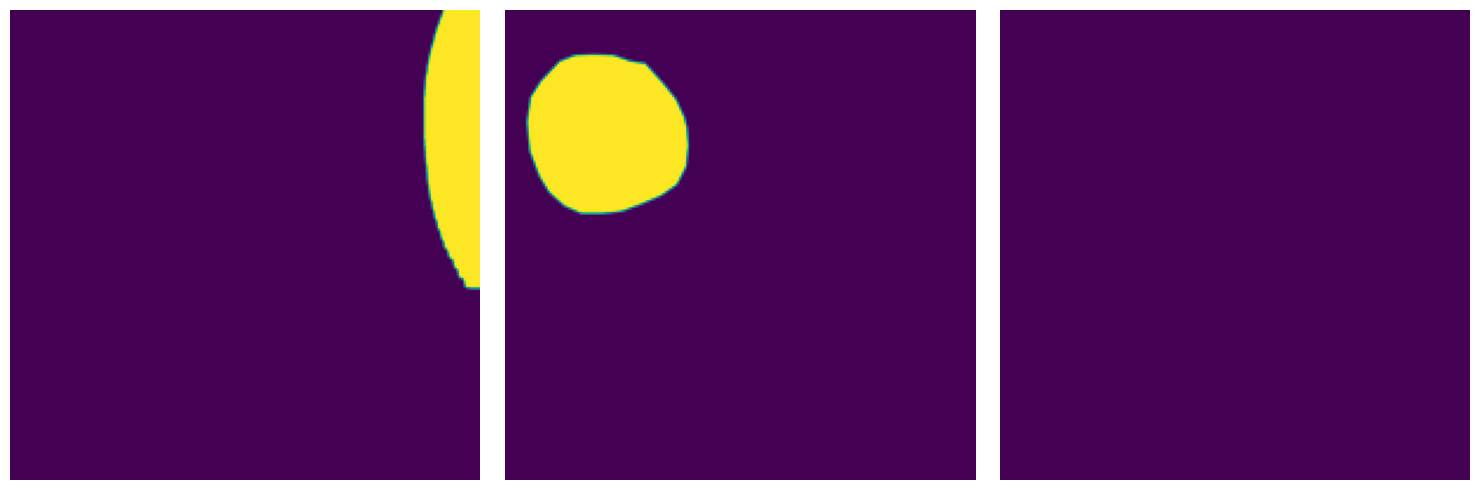

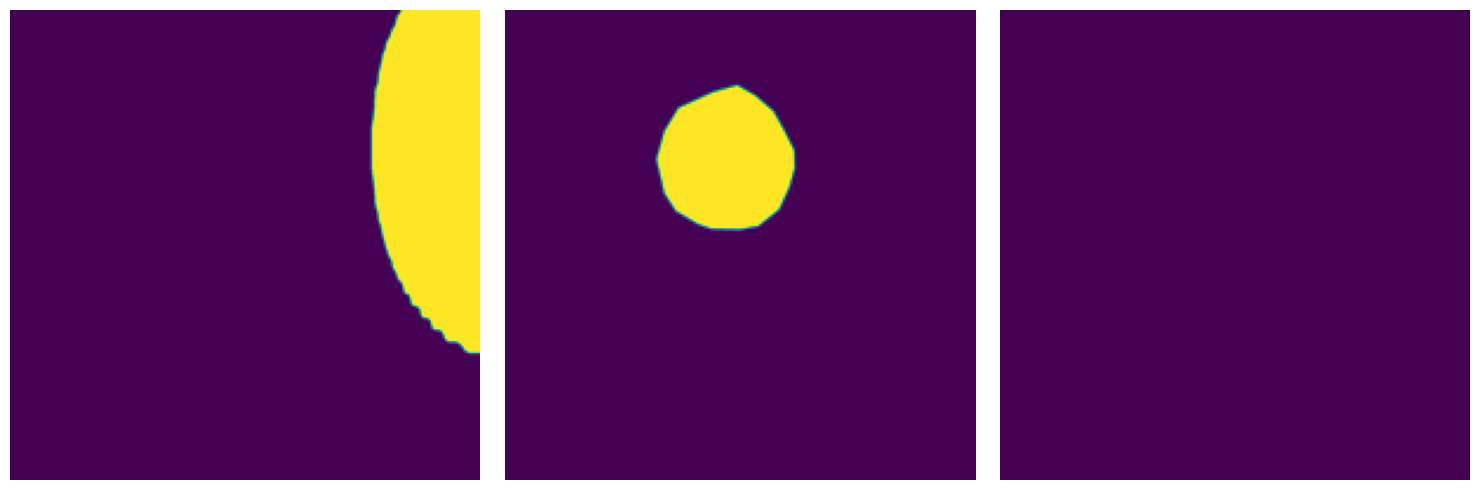

  5%|▍         | 439/9210 [00:01<00:35, 243.89it/s]

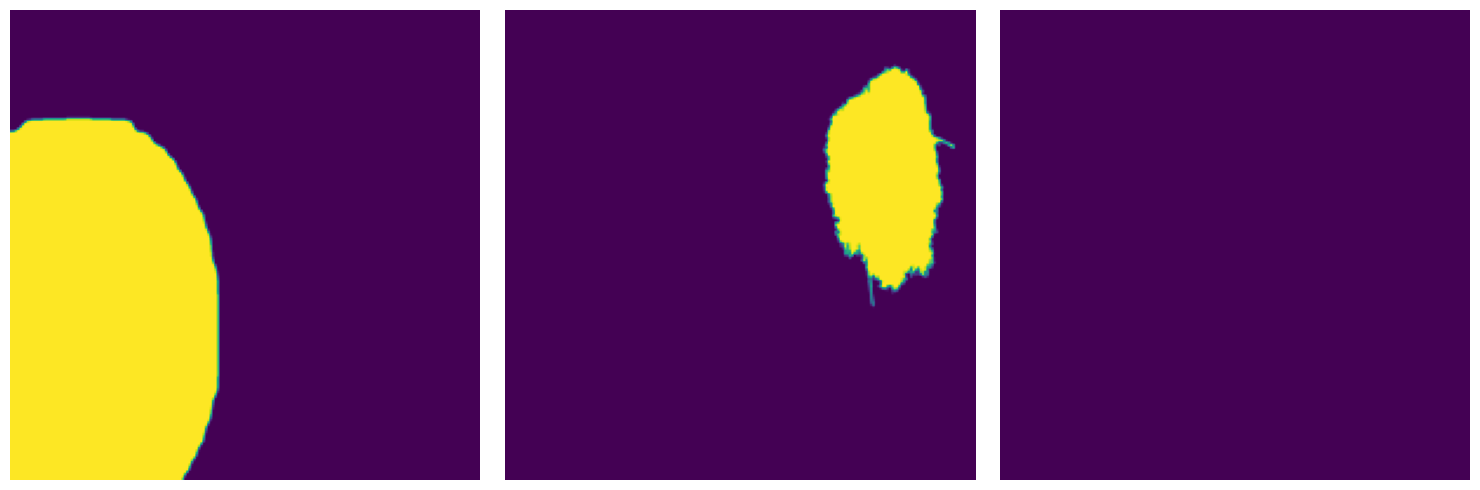

  6%|▌         | 530/9210 [00:02<00:39, 221.43it/s]

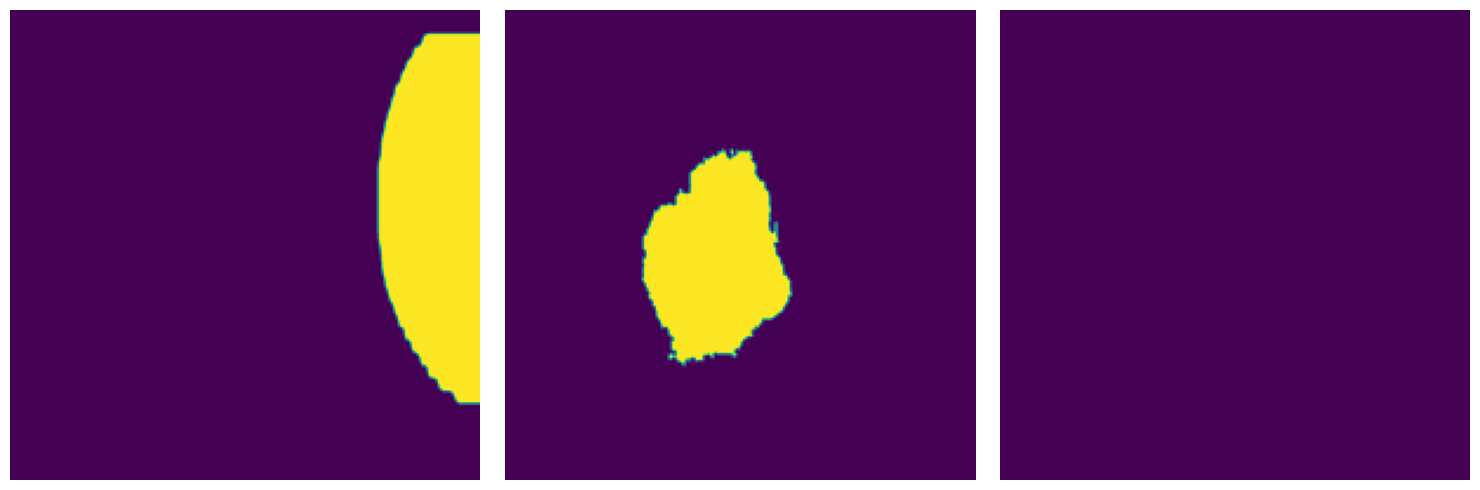

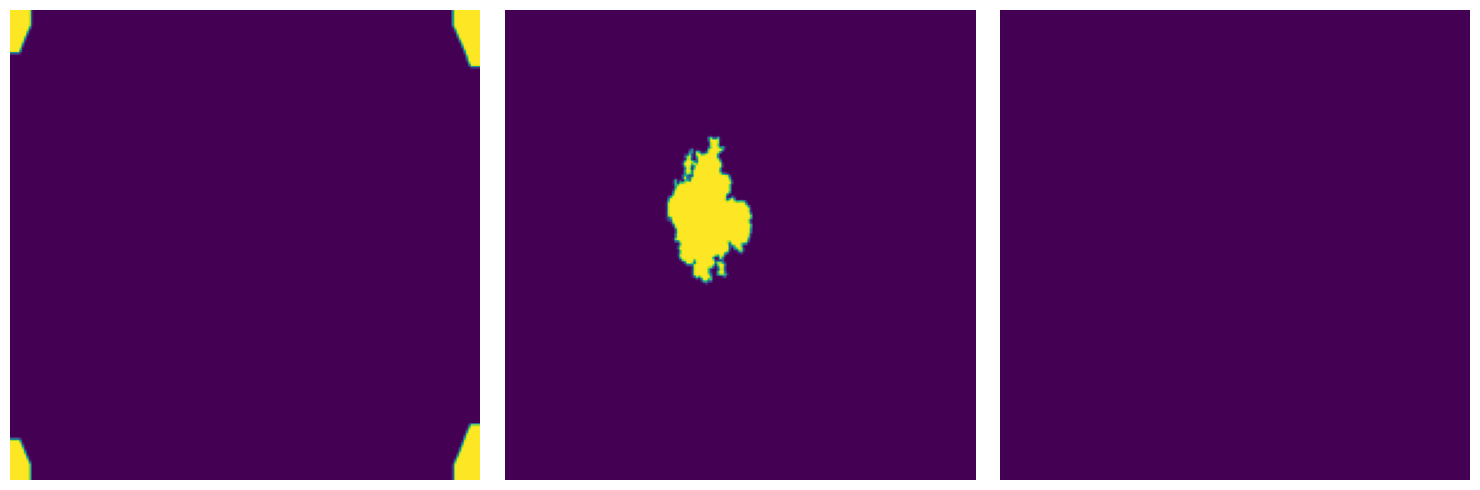

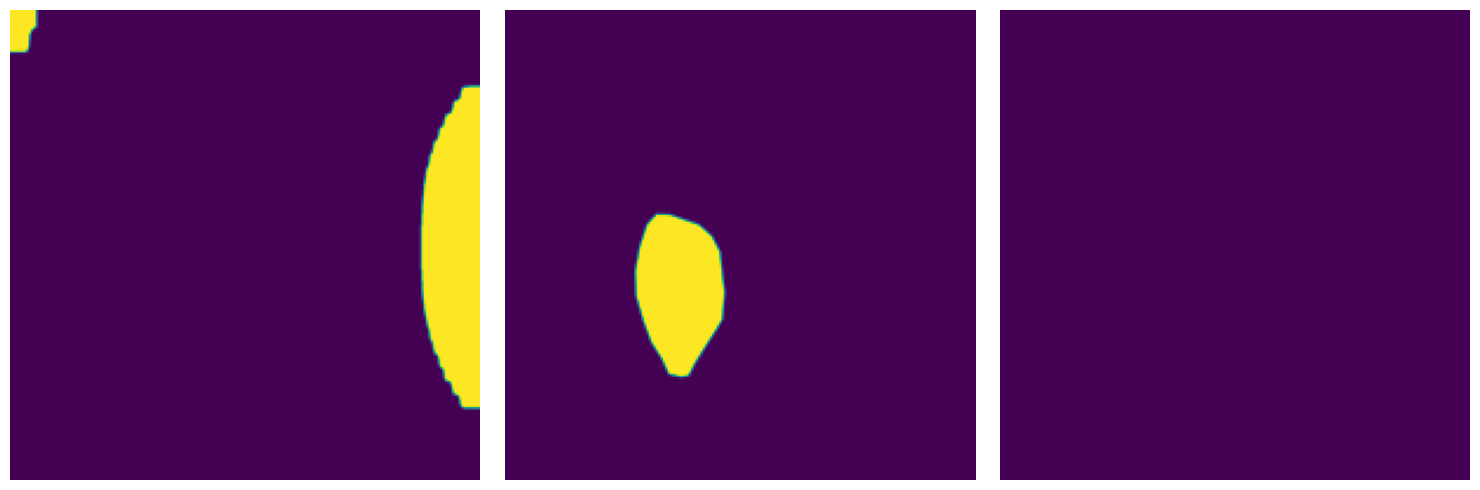

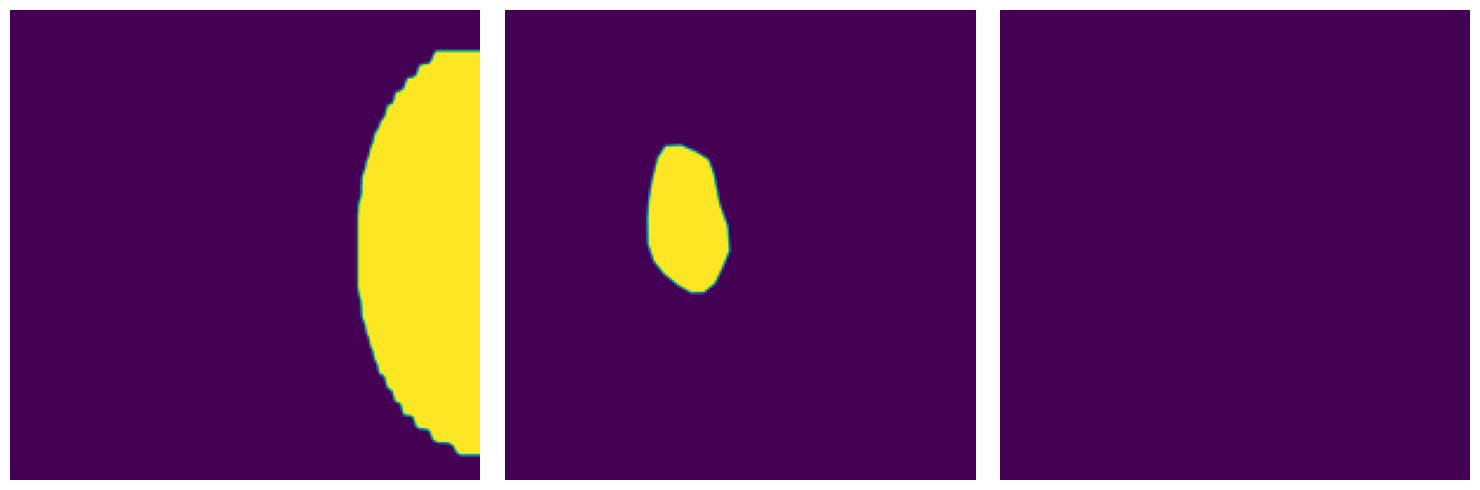

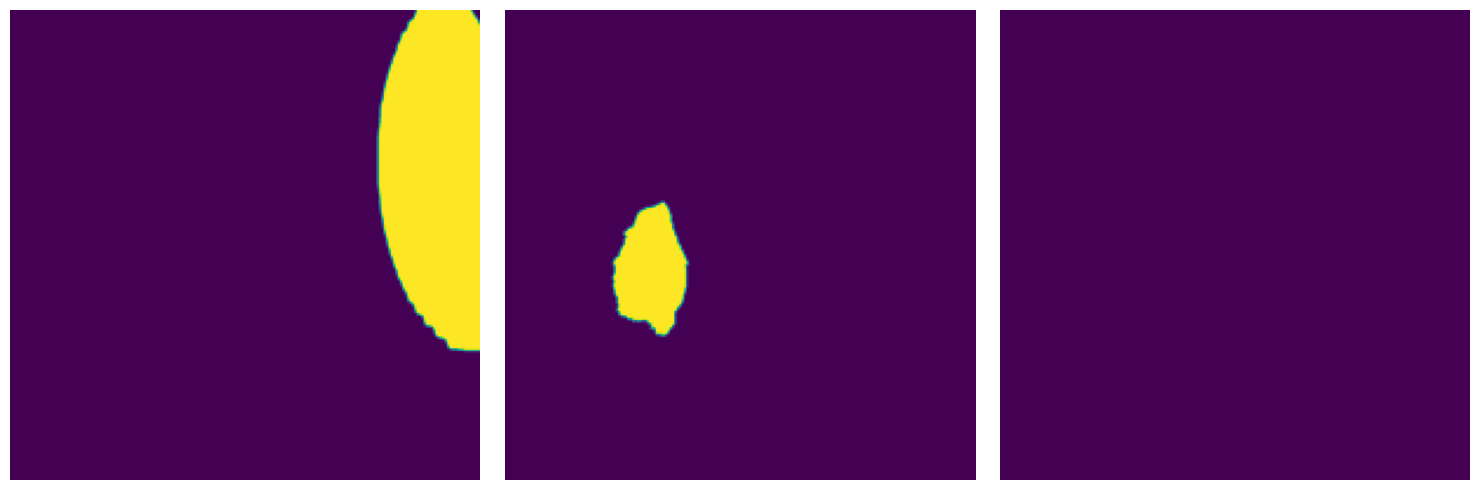

  6%|▌         | 567/9210 [00:04<03:21, 42.80it/s] 

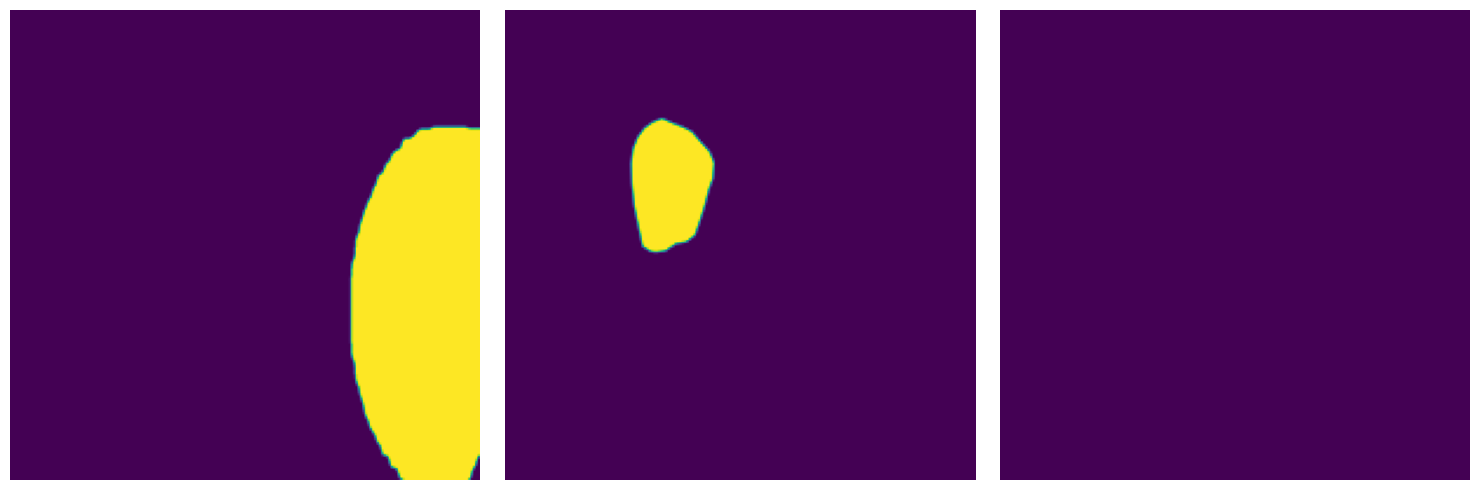

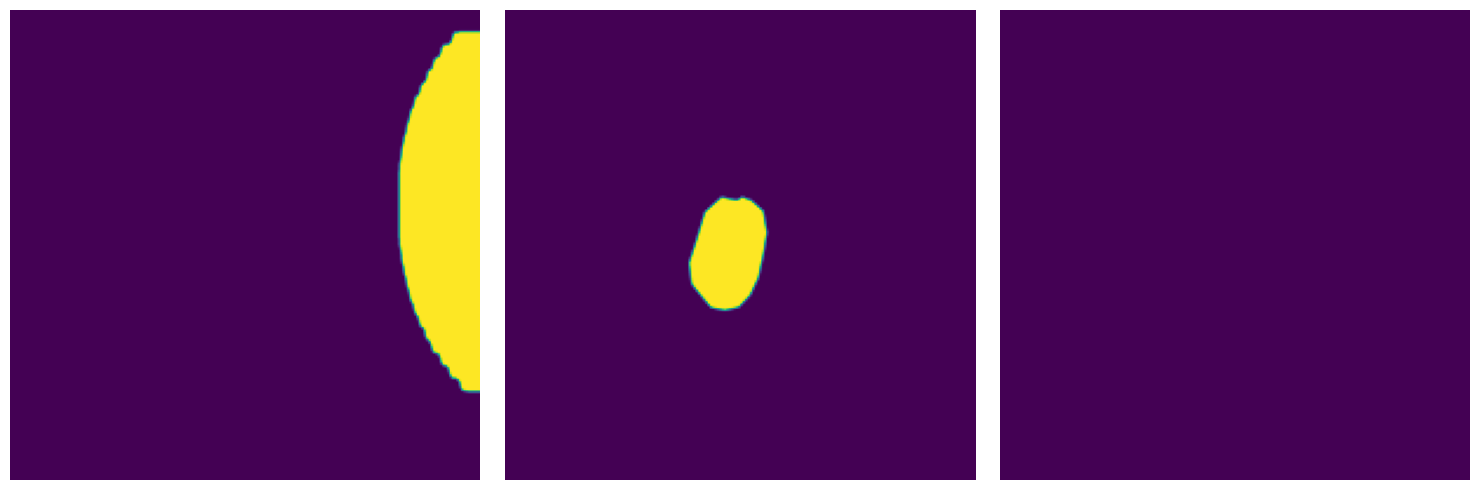

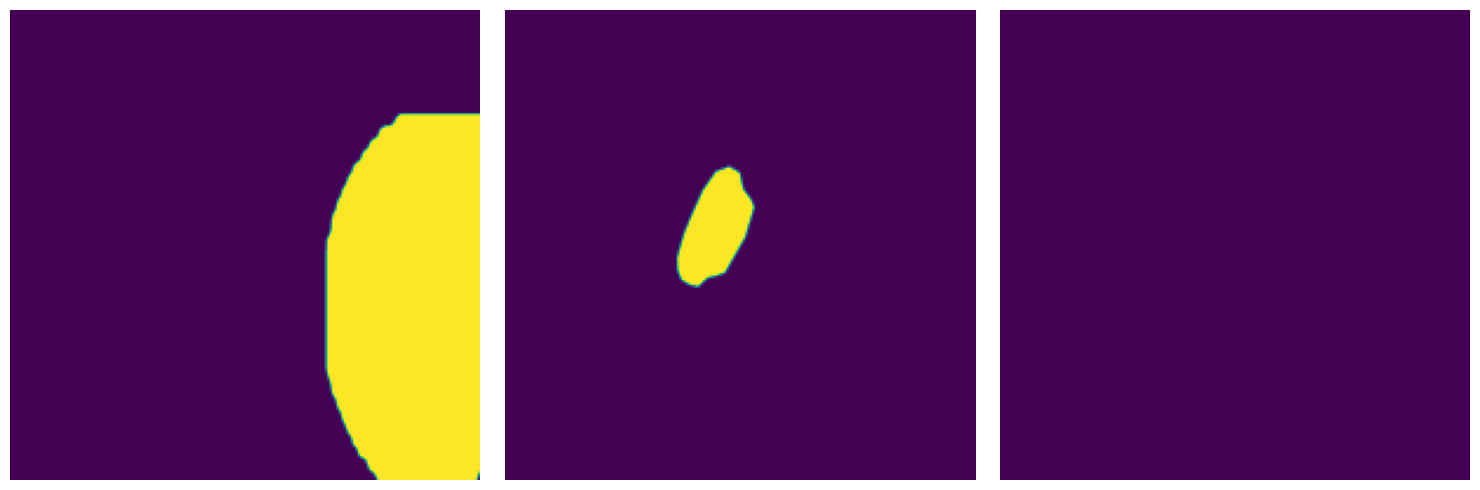

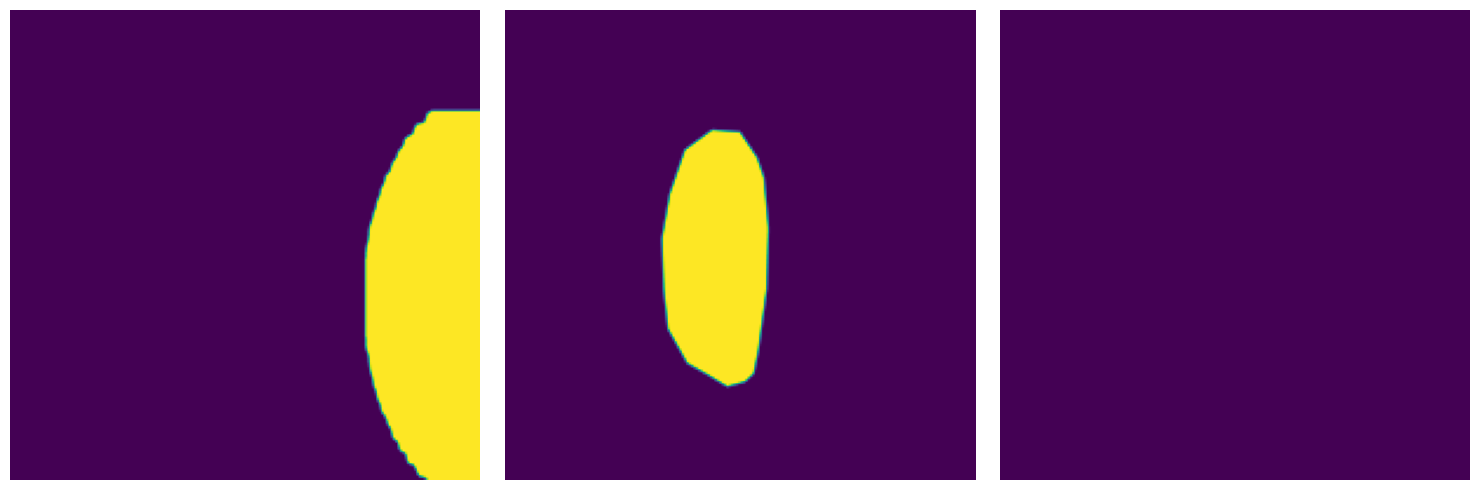

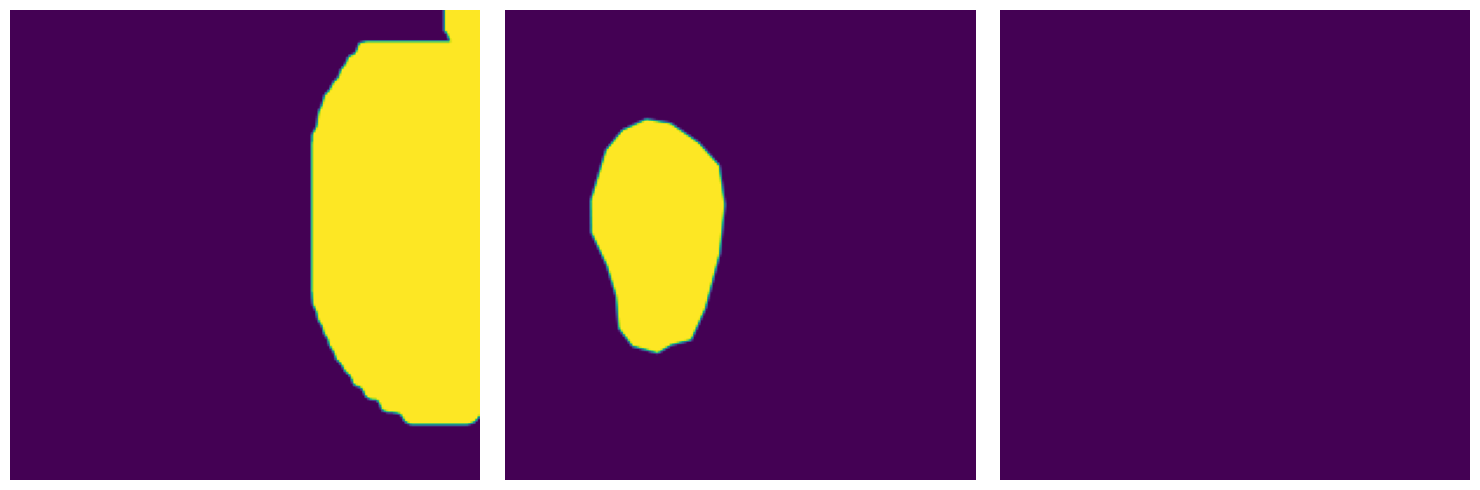

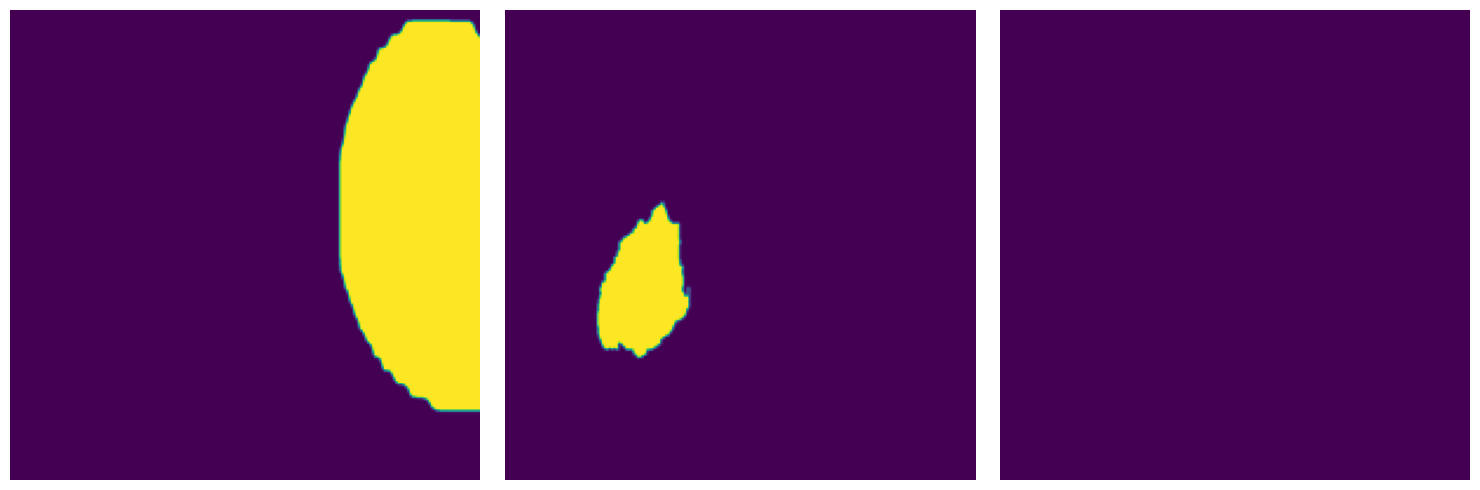

  6%|▋         | 594/9210 [00:07<05:47, 24.82it/s]

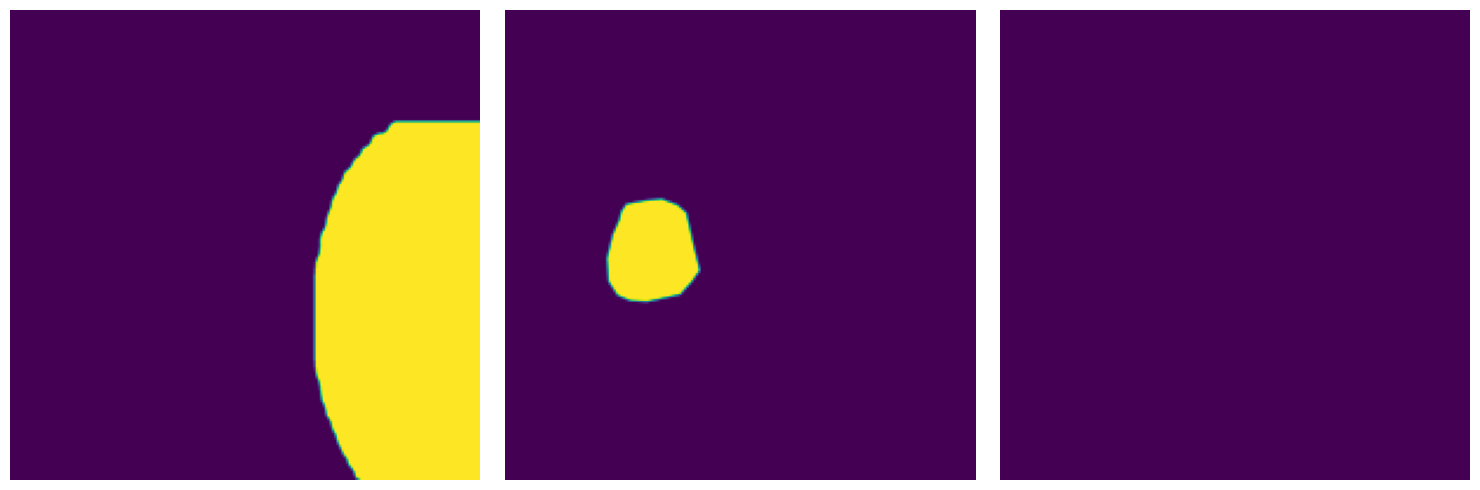

  7%|▋         | 613/9210 [00:08<05:27, 26.24it/s]

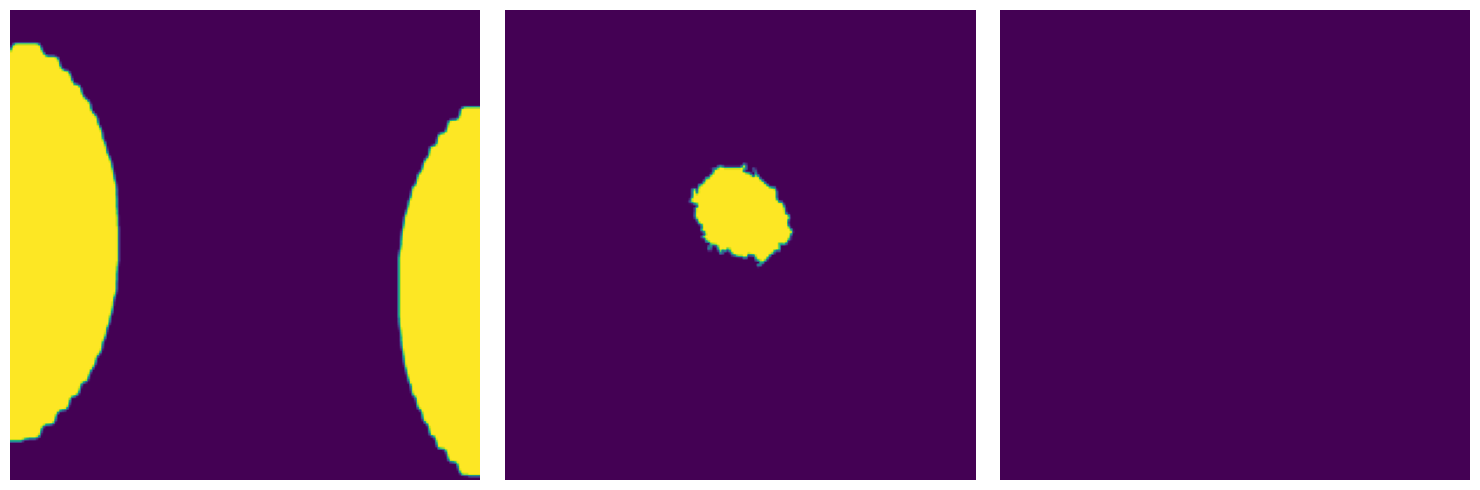

  7%|▋         | 627/9210 [00:08<05:25, 26.33it/s]

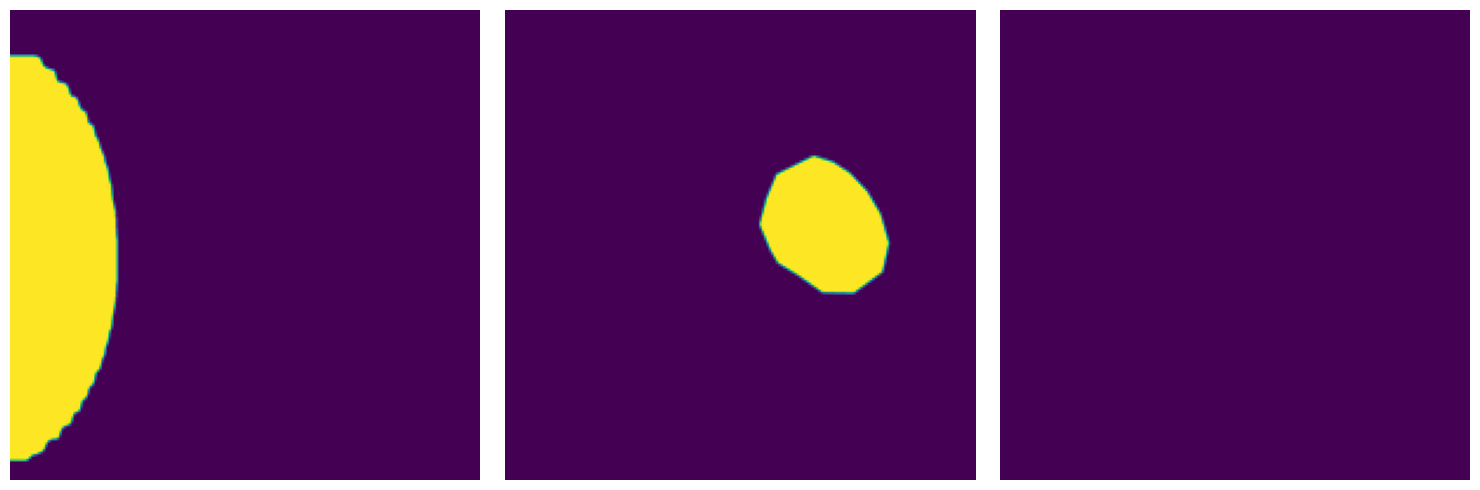

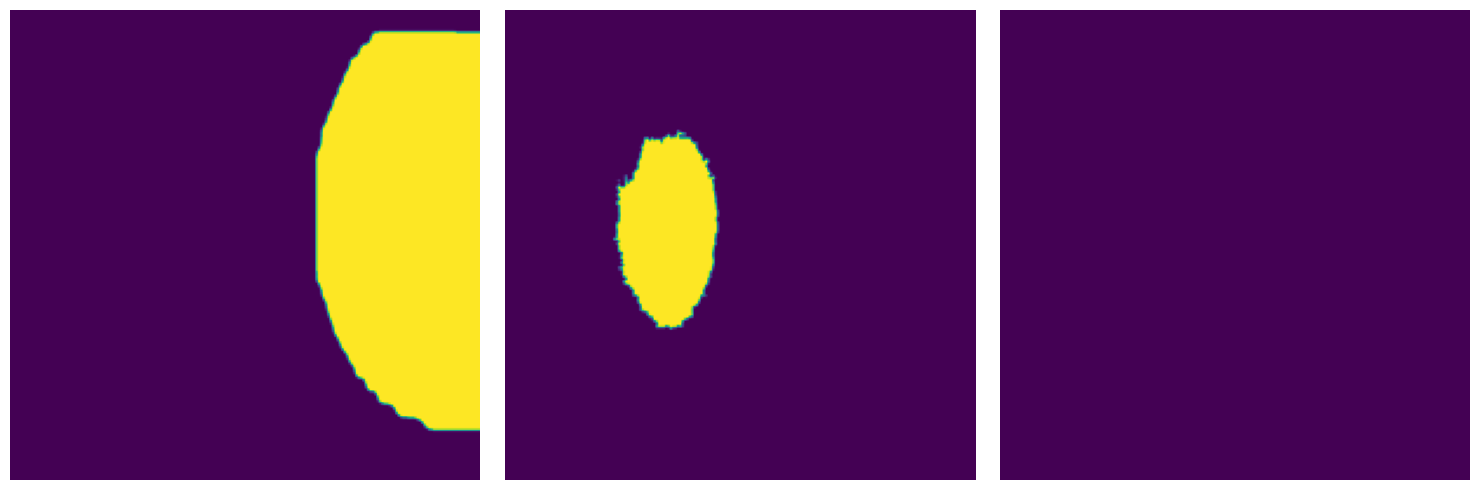

  7%|▋         | 638/9210 [00:09<05:55, 24.08it/s]

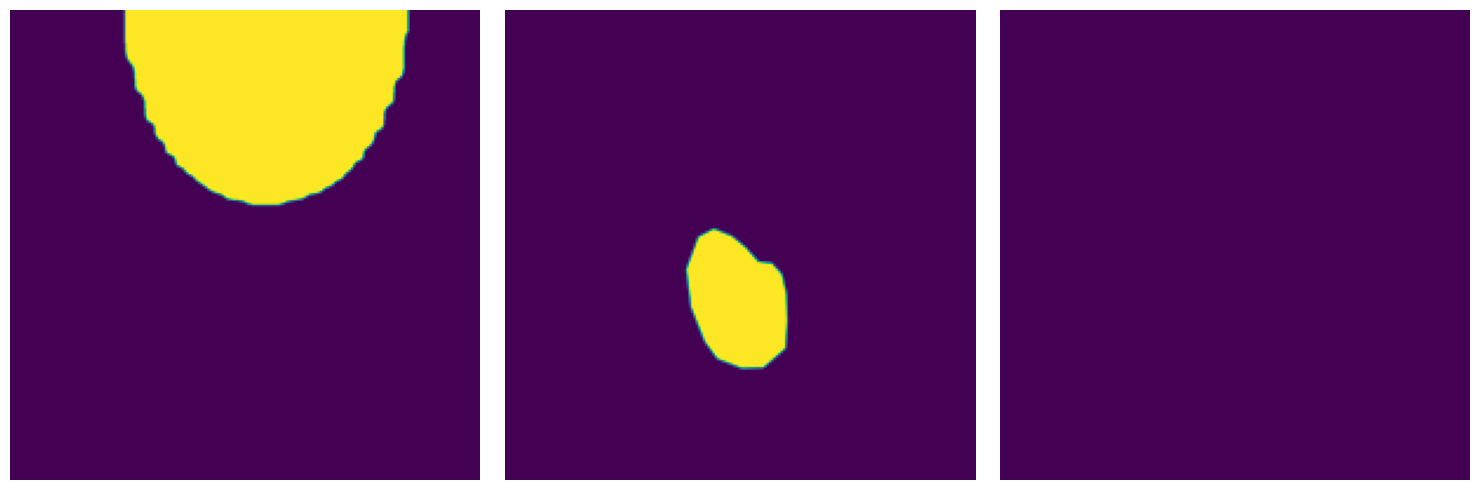

  7%|▋         | 646/9210 [00:09<05:56, 24.05it/s]

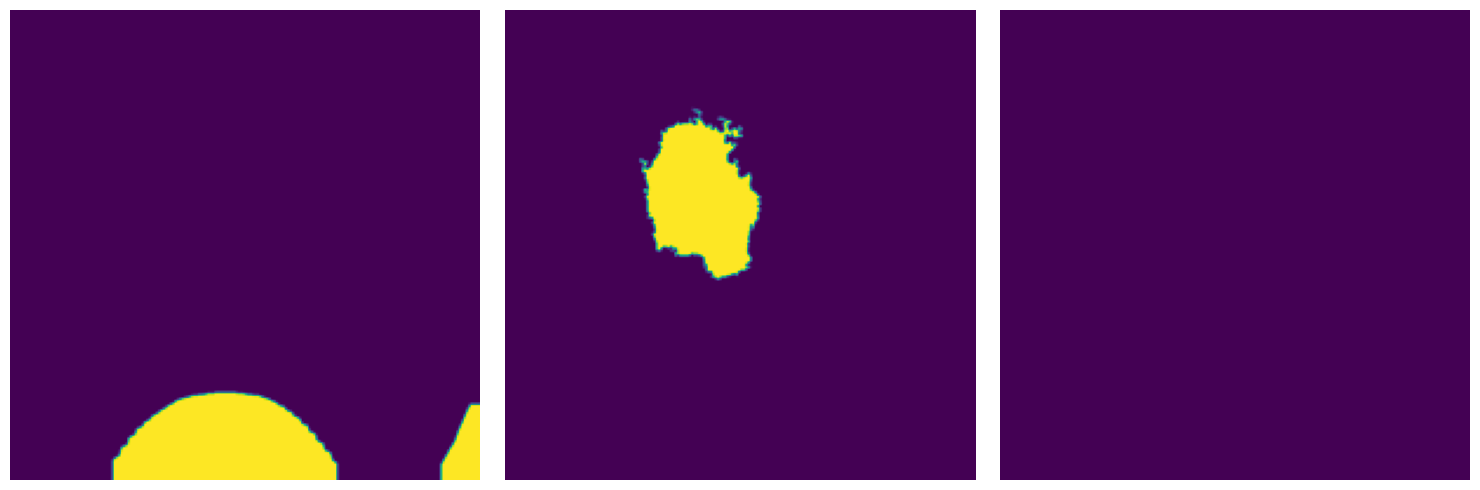

  7%|▋         | 653/9210 [00:10<06:03, 23.52it/s]

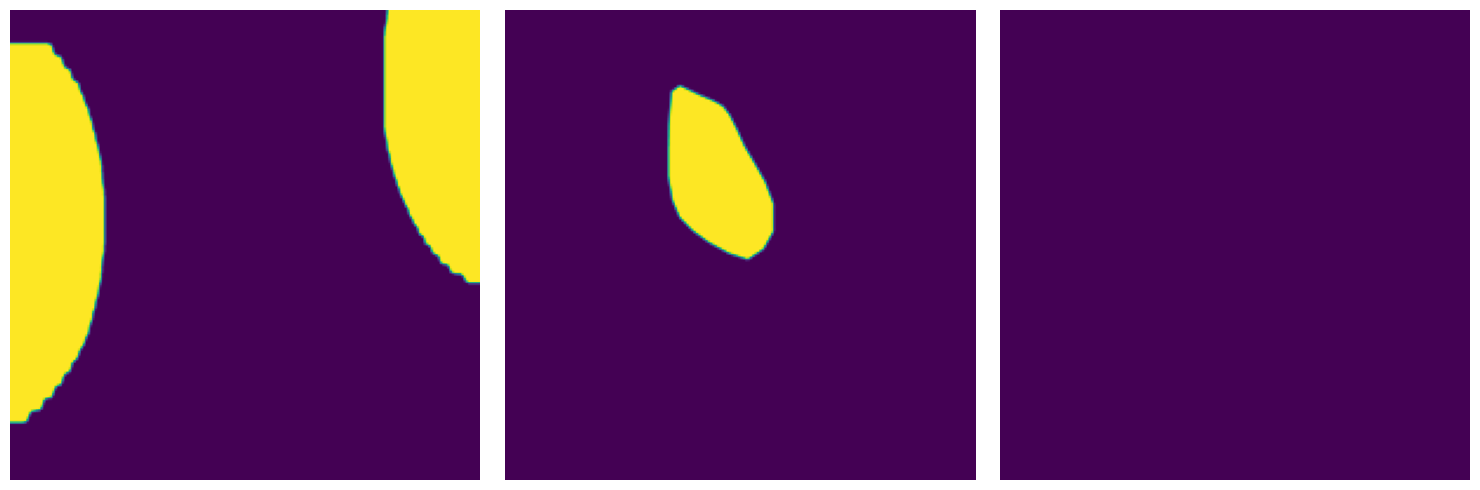

  7%|▋         | 658/9210 [00:10<06:29, 21.95it/s]

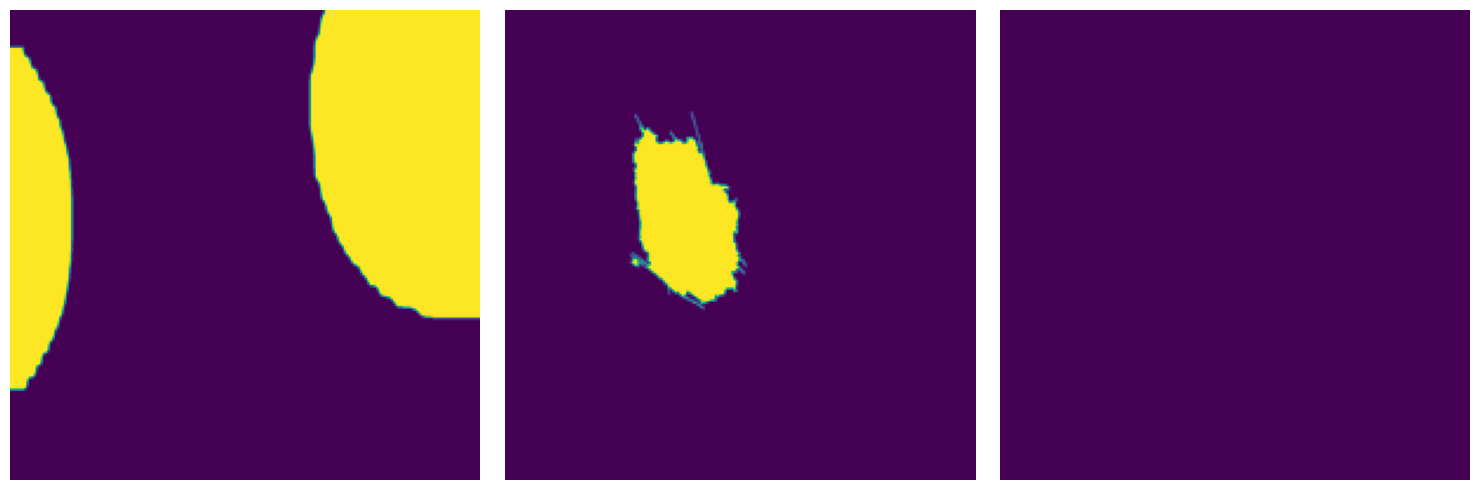

  7%|▋         | 667/9210 [00:10<06:12, 22.93it/s]

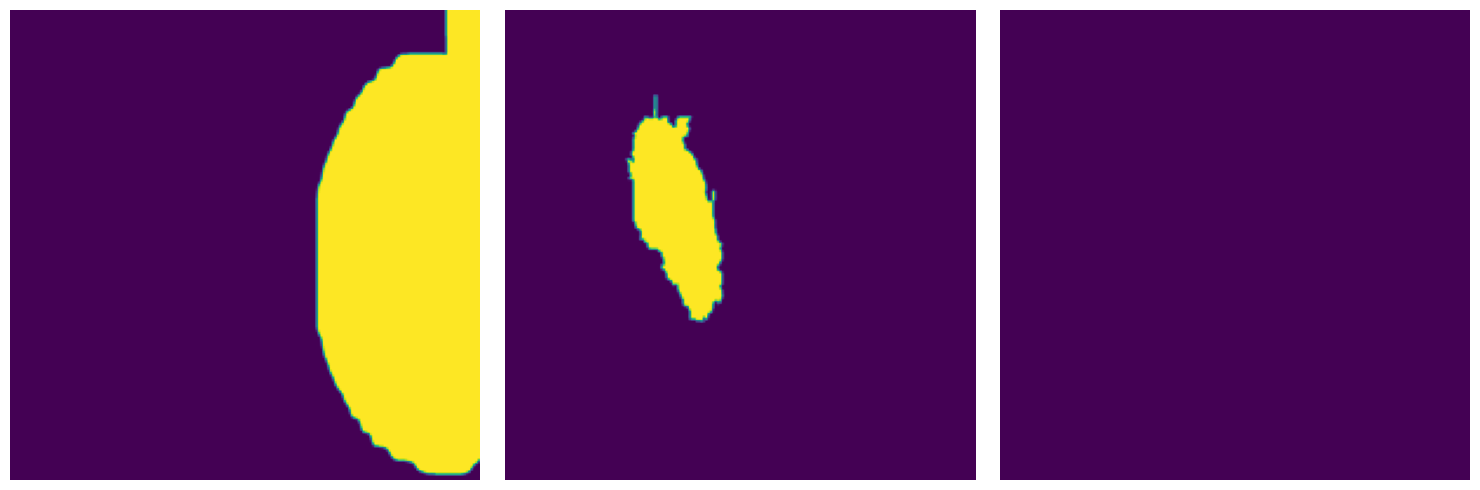

  7%|▋         | 673/9210 [00:11<06:32, 21.78it/s]

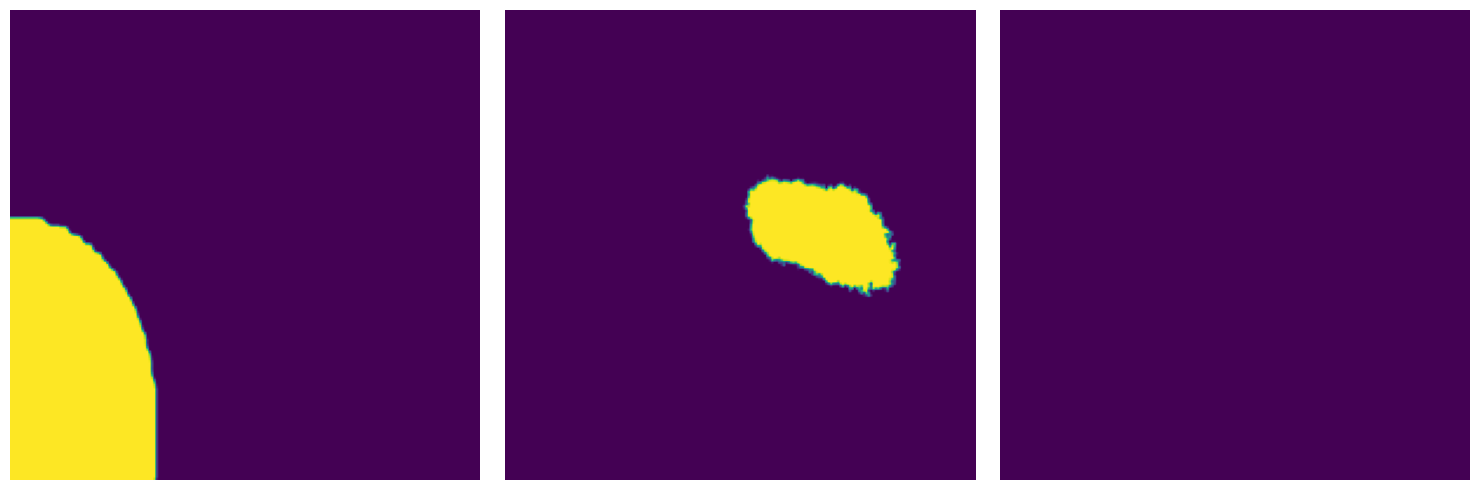

  7%|▋         | 677/9210 [00:11<07:18, 19.48it/s]

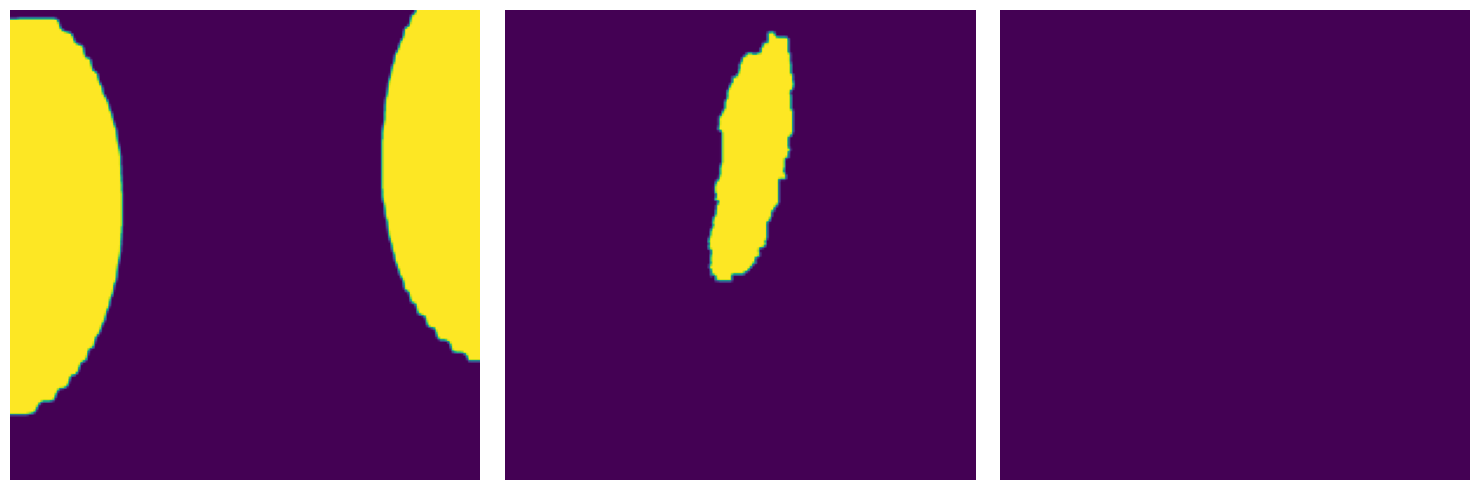

  7%|▋         | 680/9210 [00:11<08:27, 16.79it/s]

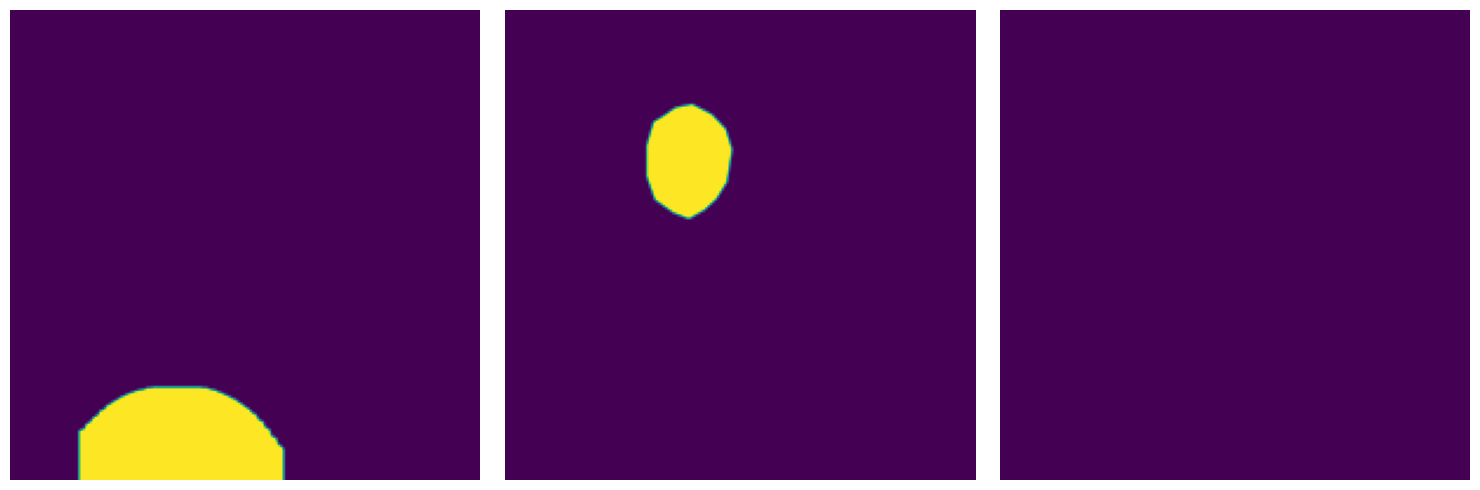

  8%|▊         | 736/9210 [00:12<02:06, 67.02it/s]

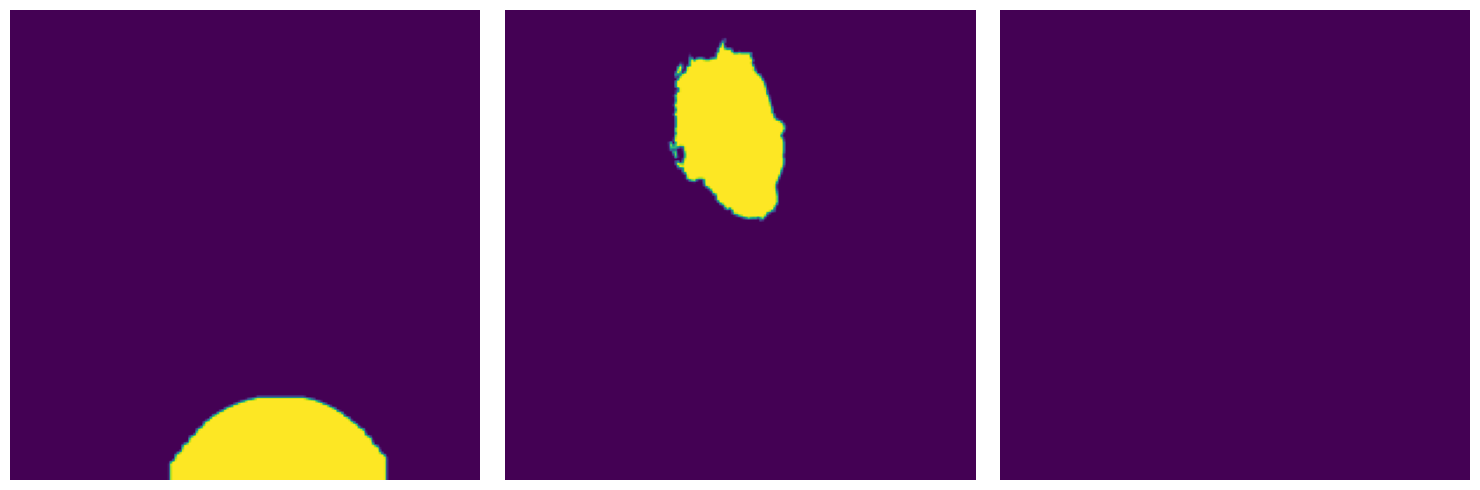

  8%|▊         | 752/9210 [00:12<02:21, 59.81it/s]

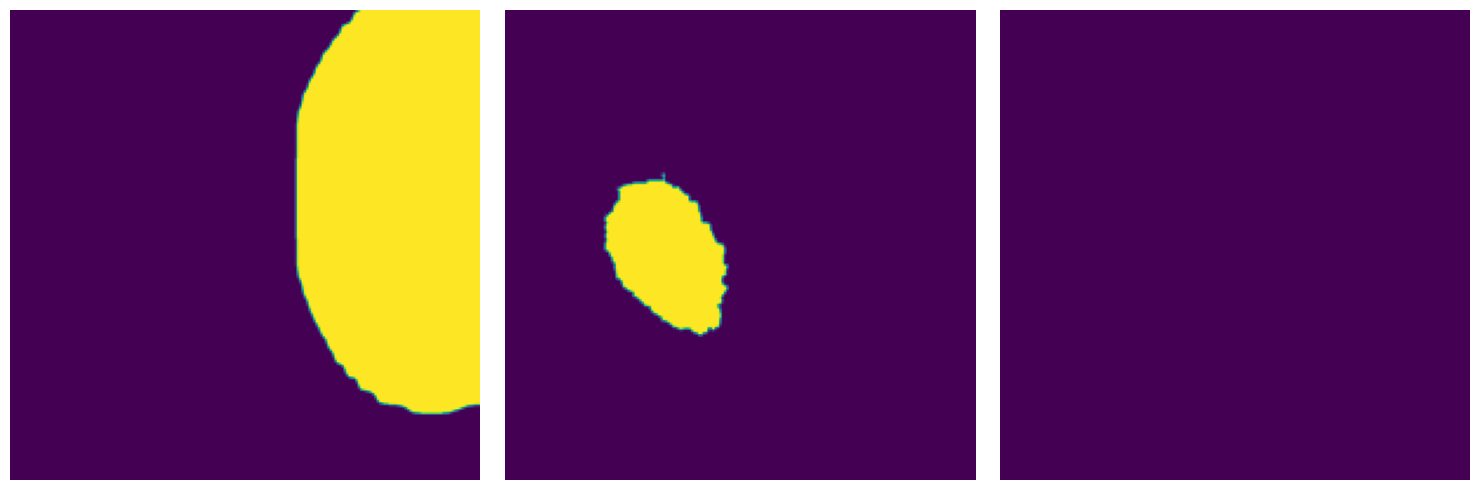

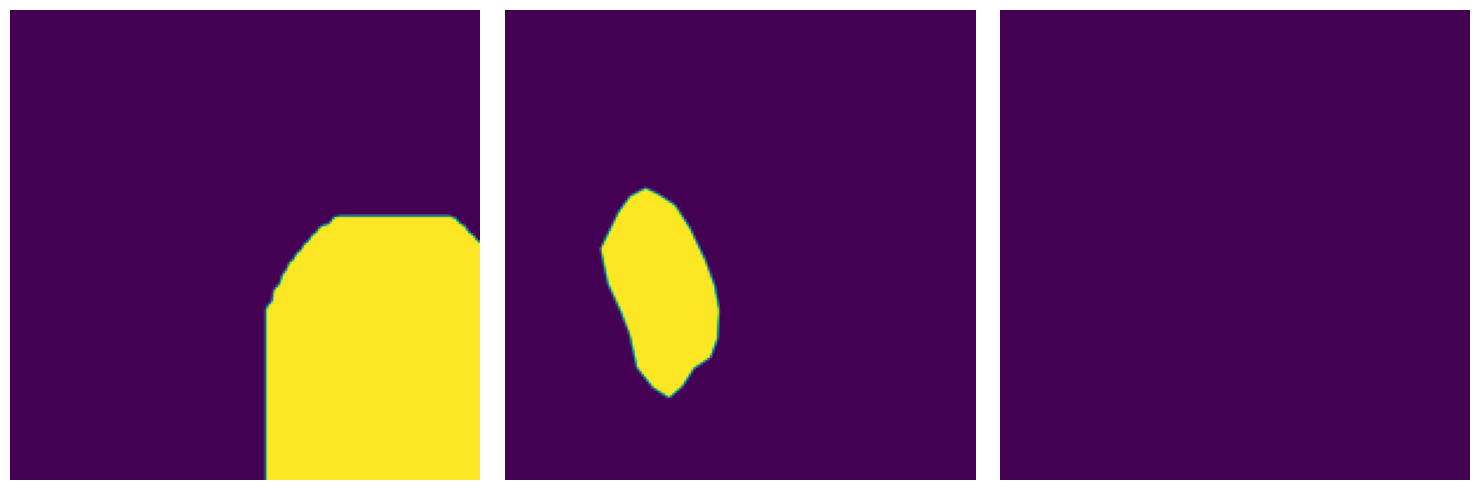

  8%|▊         | 765/9210 [00:13<03:27, 40.77it/s]

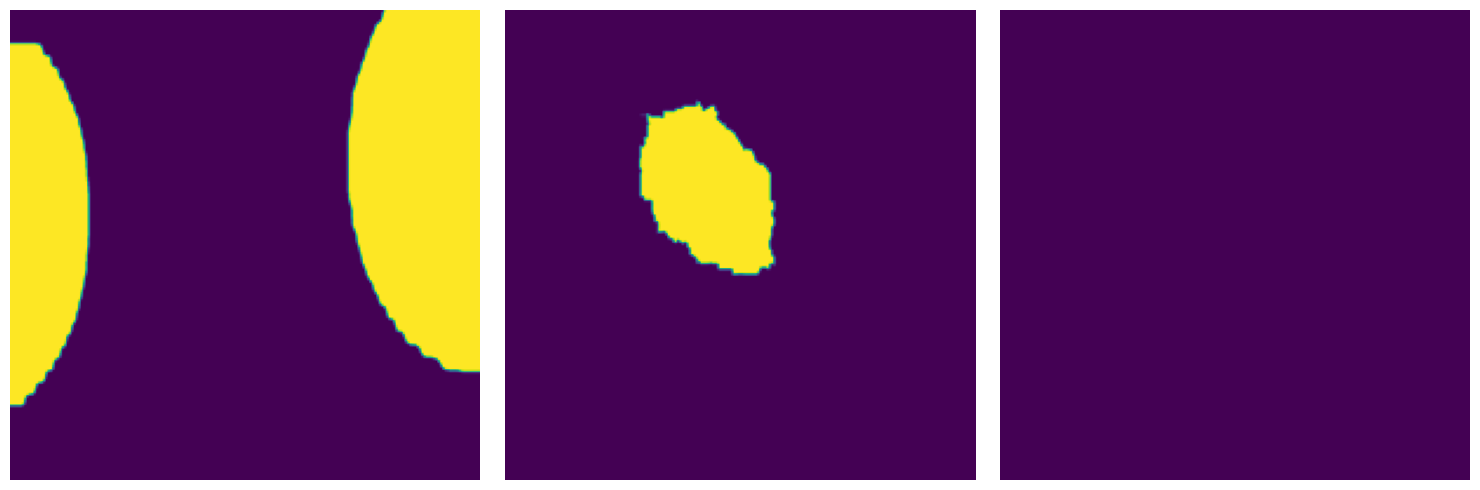

  8%|▊         | 775/9210 [00:13<03:42, 37.90it/s]

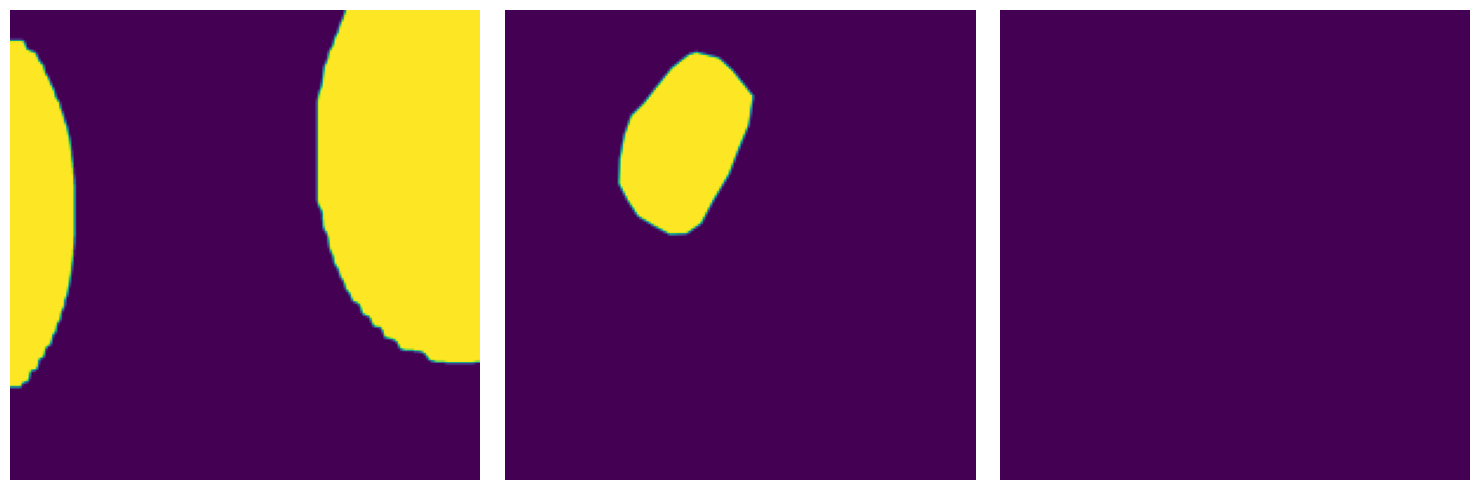

  9%|▊         | 804/9210 [00:13<02:50, 49.38it/s]

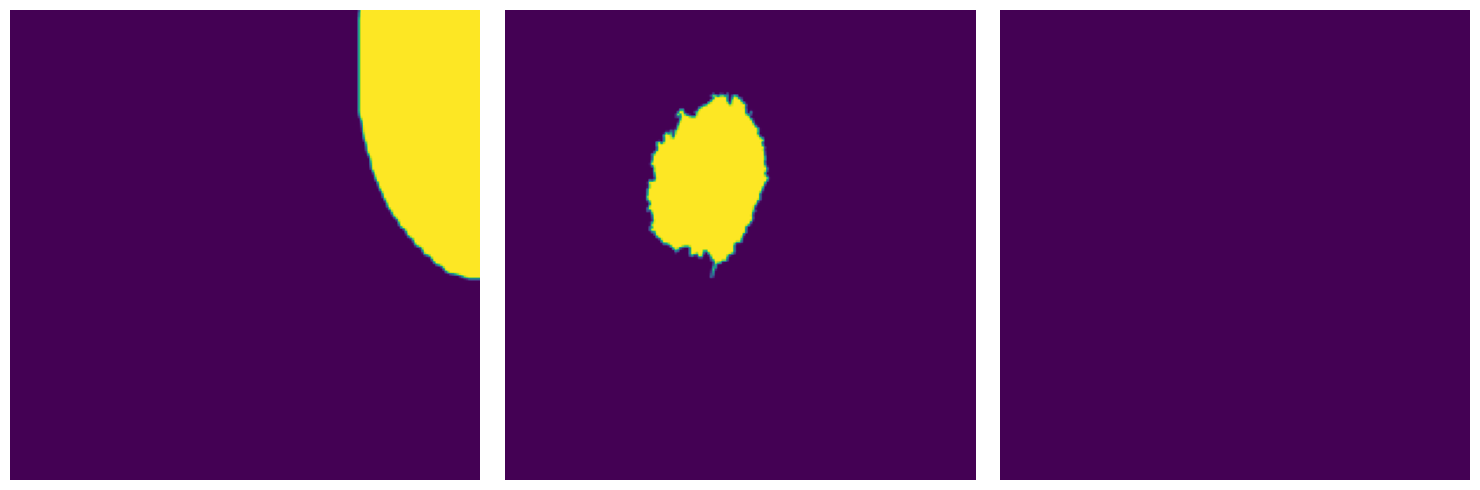

  9%|▉         | 812/9210 [00:14<03:17, 42.46it/s]

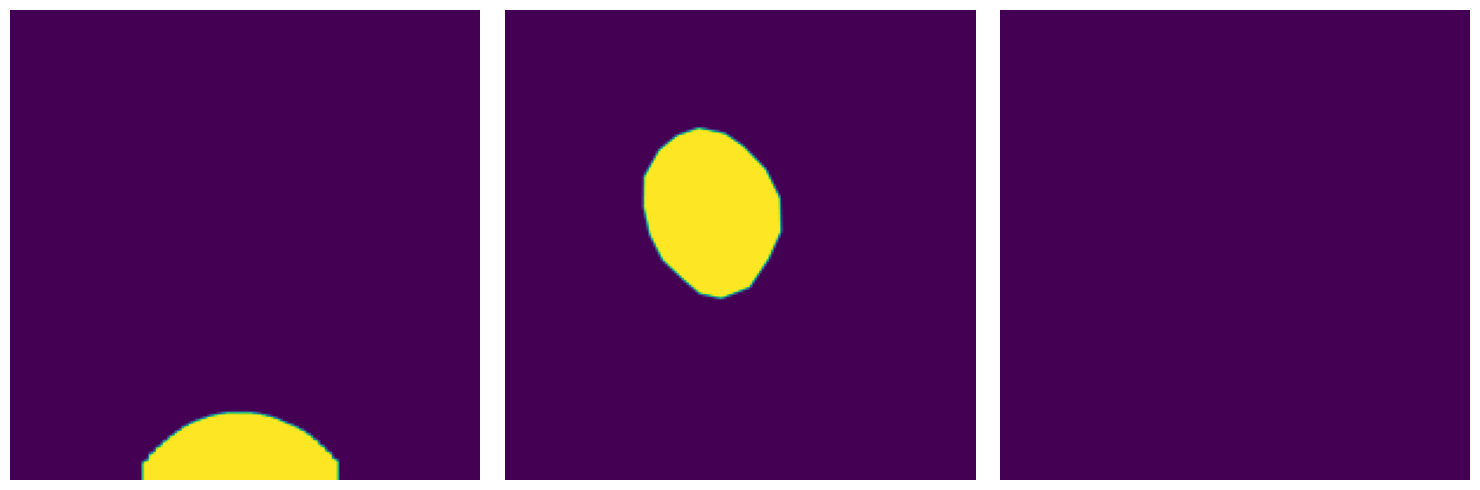

  9%|▉         | 823/9210 [00:14<03:32, 39.51it/s]

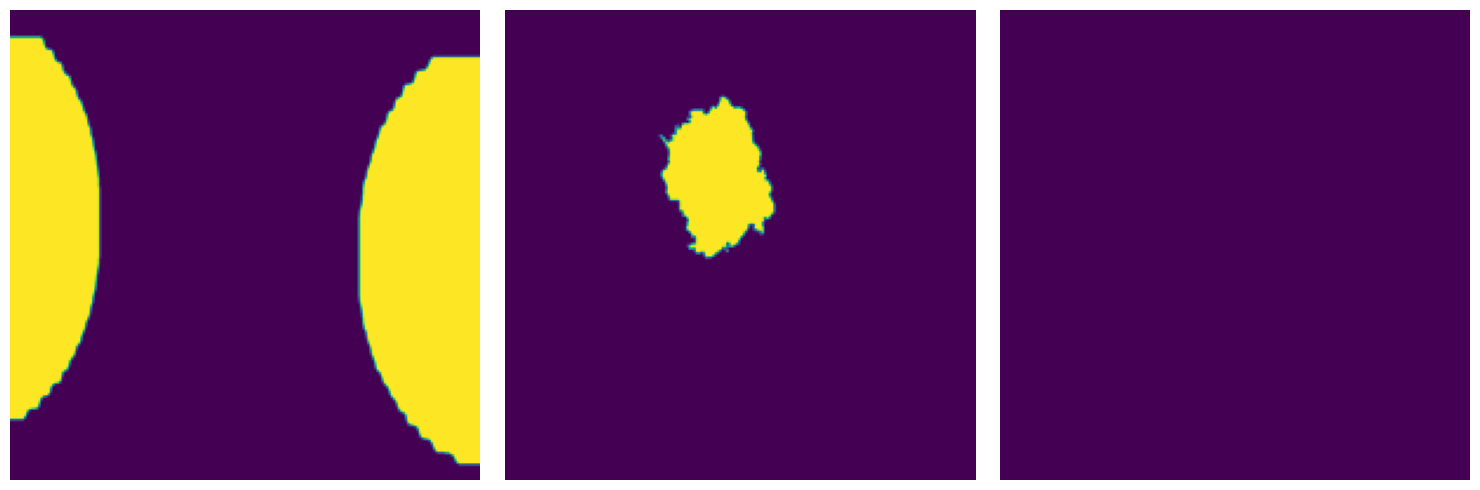

 12%|█▏        | 1129/9210 [00:15<00:23, 349.32it/s]

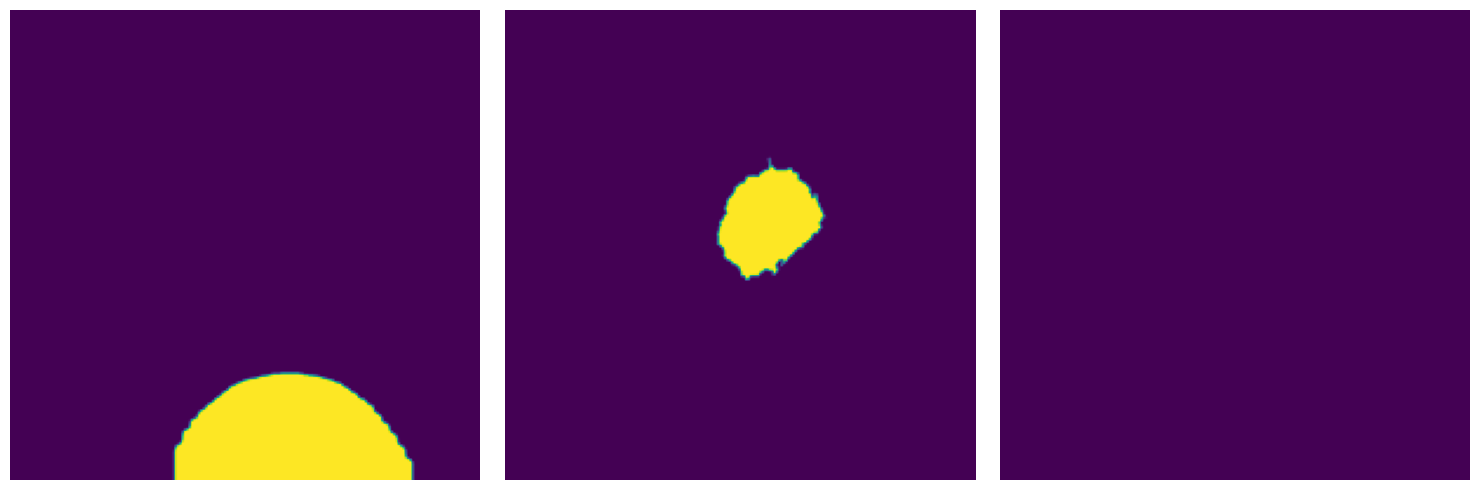

 13%|█▎        | 1222/9210 [00:16<00:31, 256.88it/s]

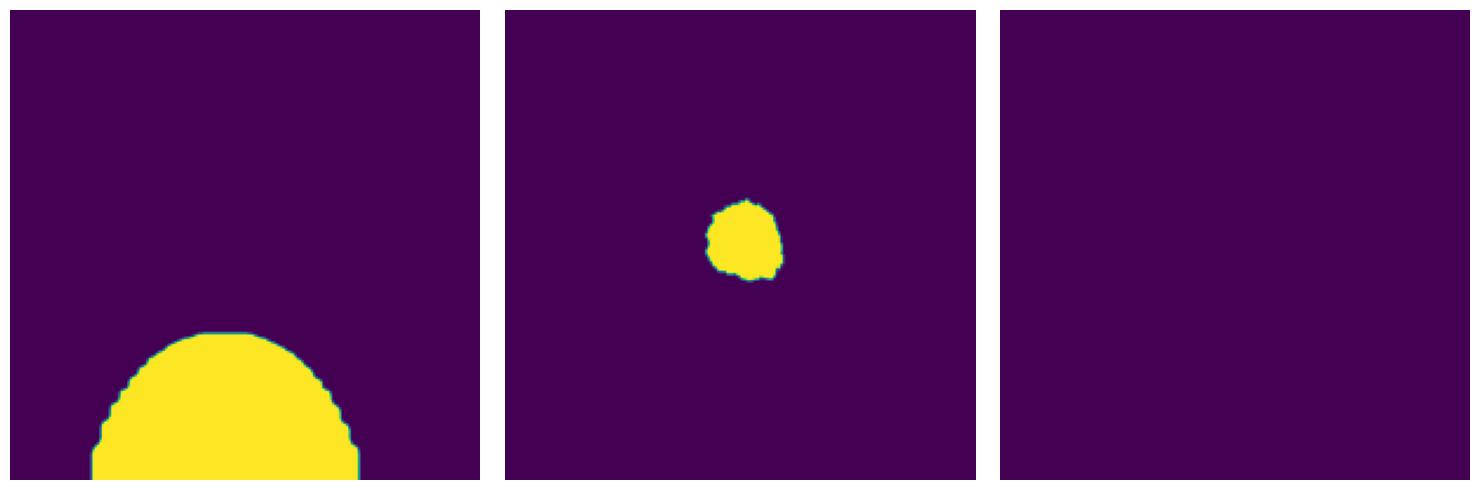

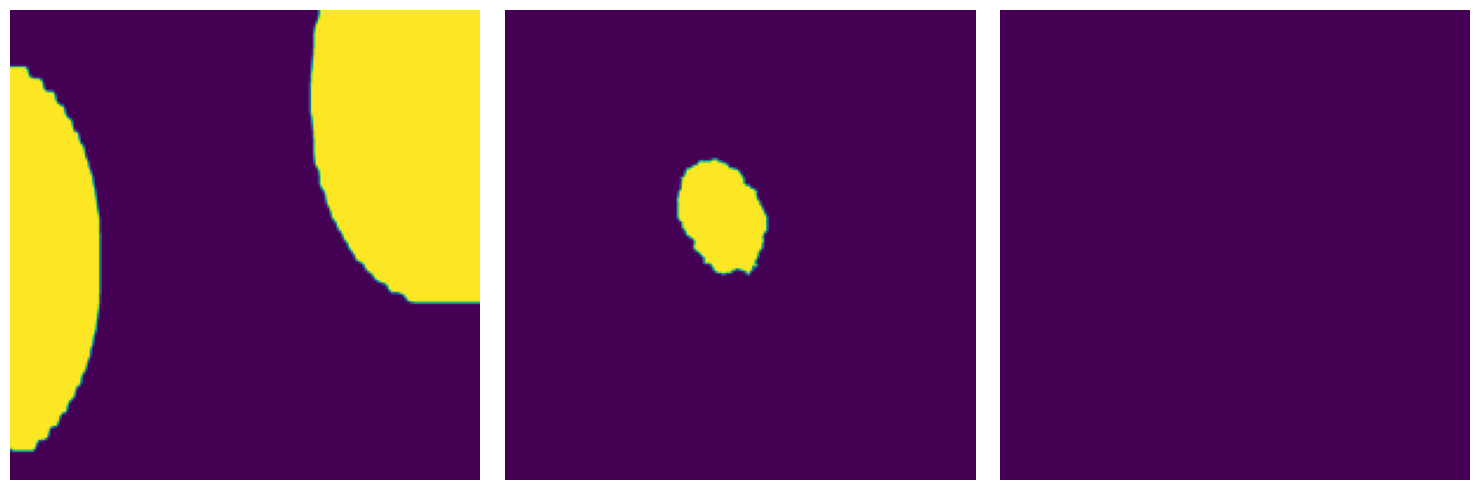

 14%|█▍        | 1311/9210 [00:16<00:45, 172.33it/s]

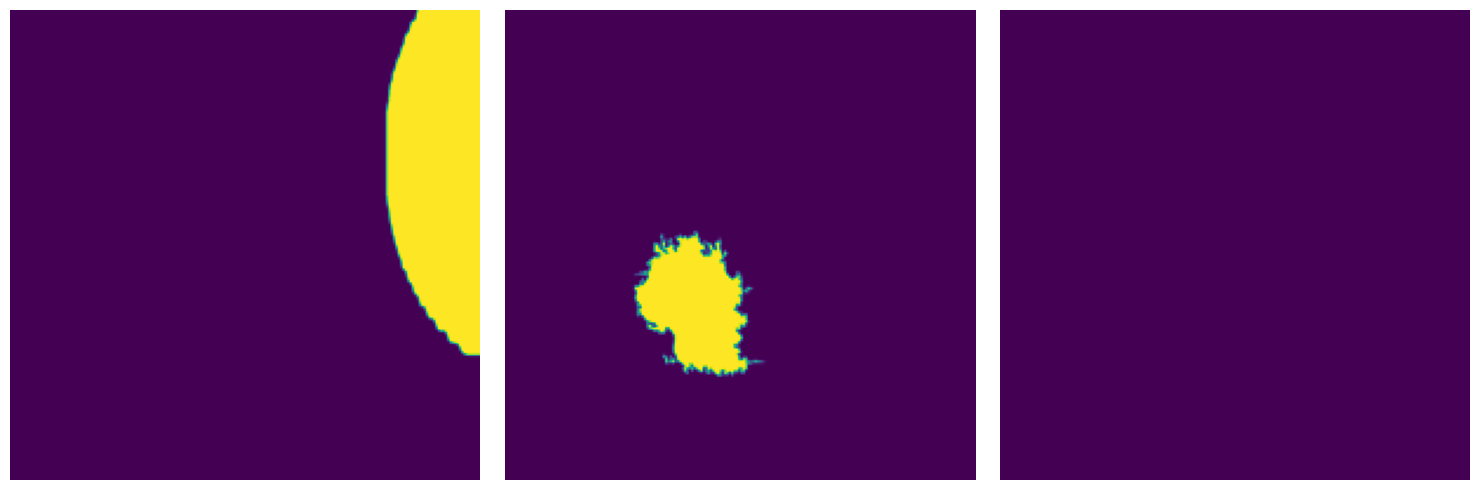

 16%|█▌        | 1446/9210 [00:17<00:33, 233.79it/s]

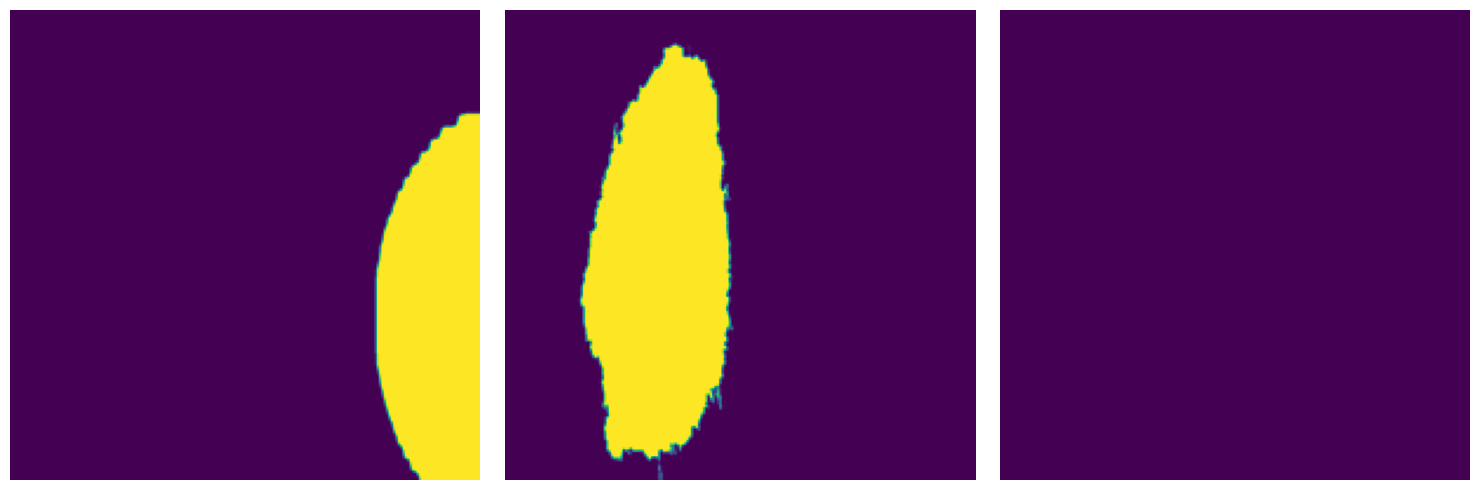

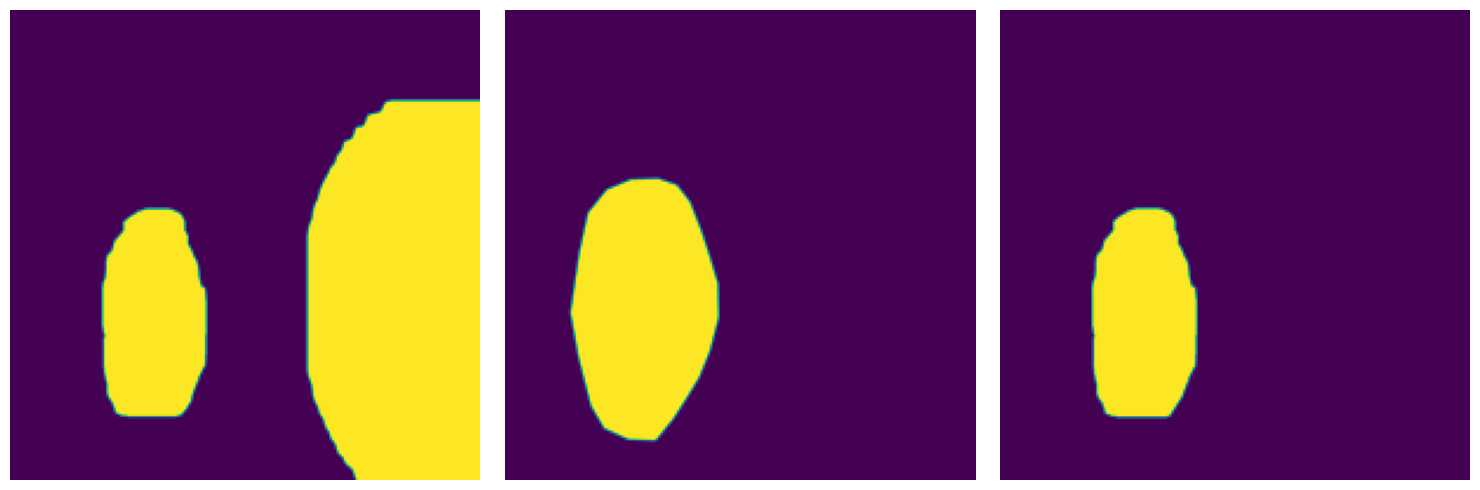

 17%|█▋        | 1535/9210 [00:18<00:46, 164.26it/s]

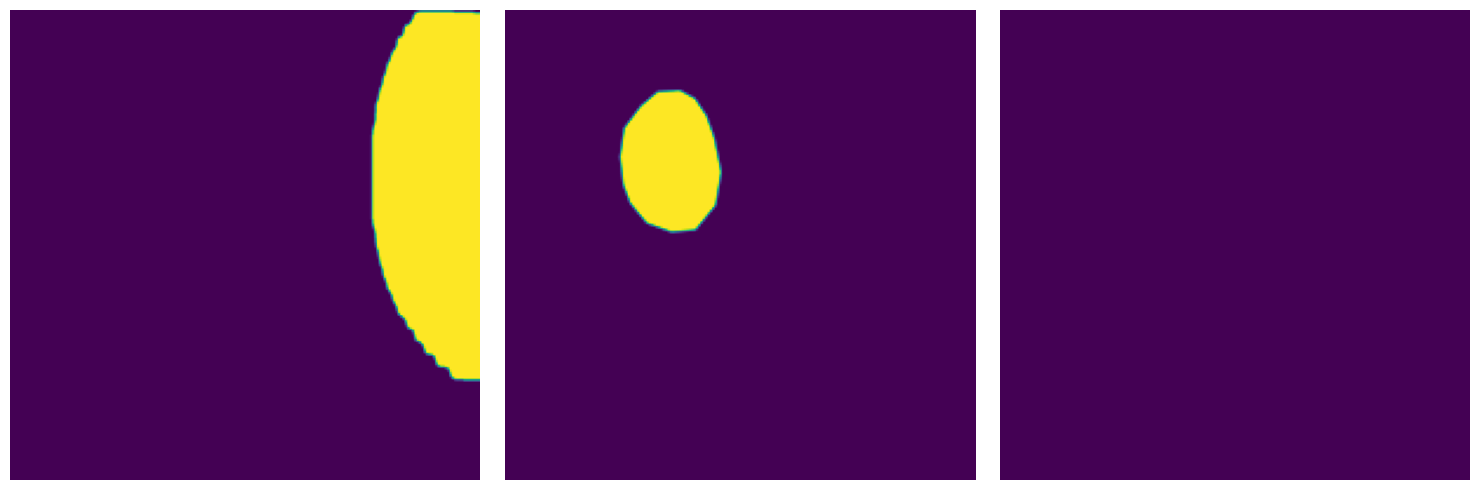

 17%|█▋        | 1582/9210 [00:18<00:52, 146.04it/s]

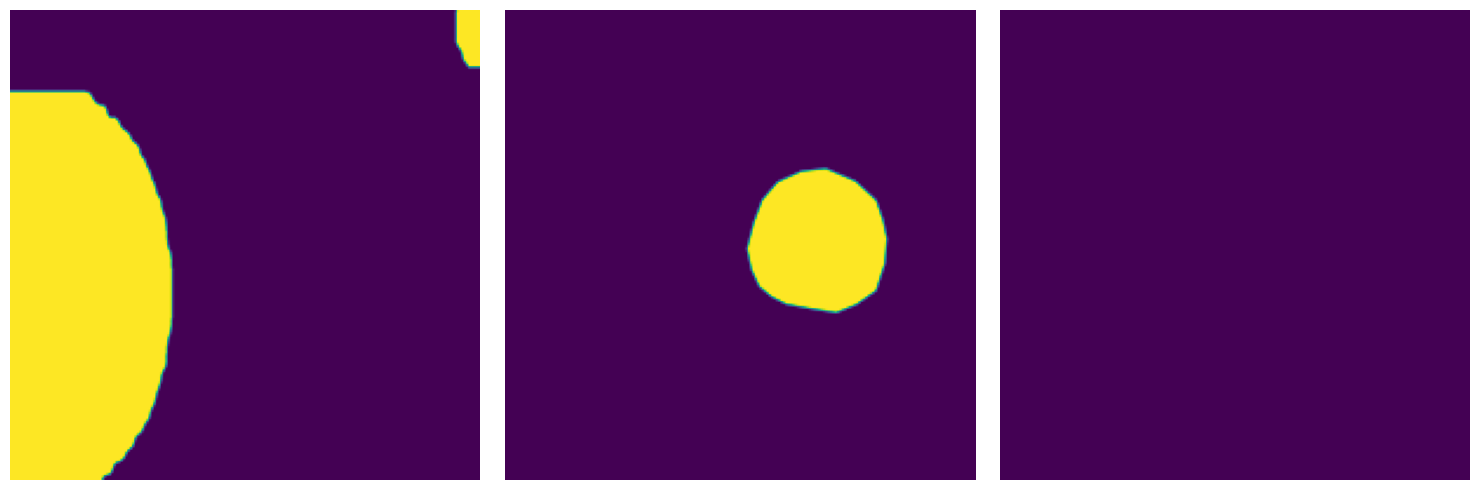

 18%|█▊        | 1622/9210 [00:19<00:58, 130.14it/s]

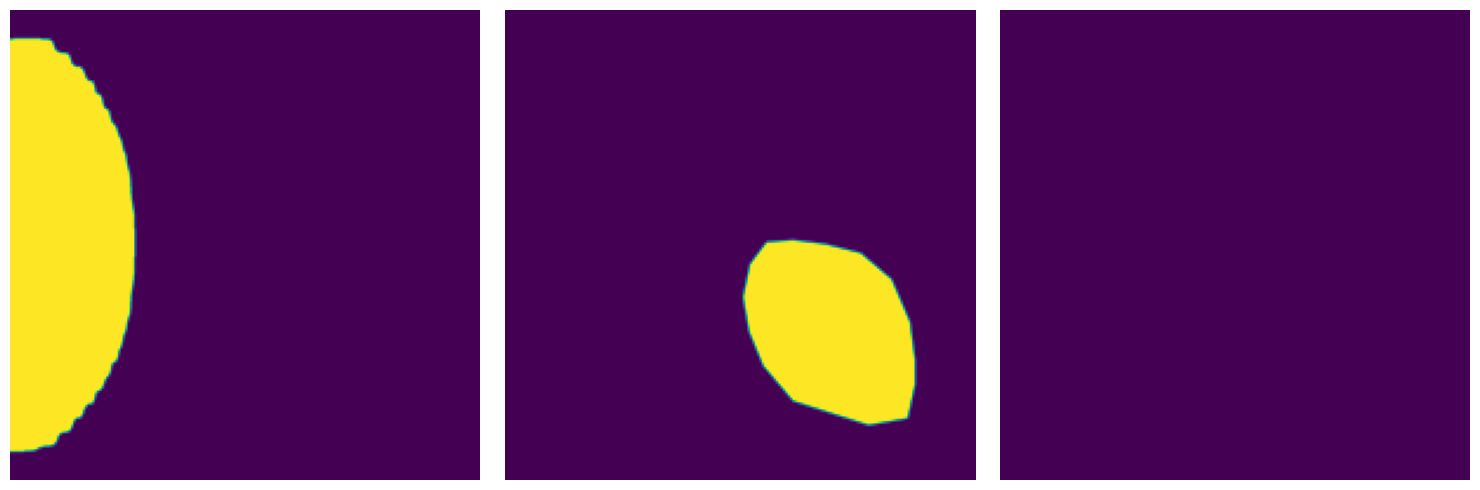

 18%|█▊        | 1645/9210 [00:19<01:08, 109.76it/s]

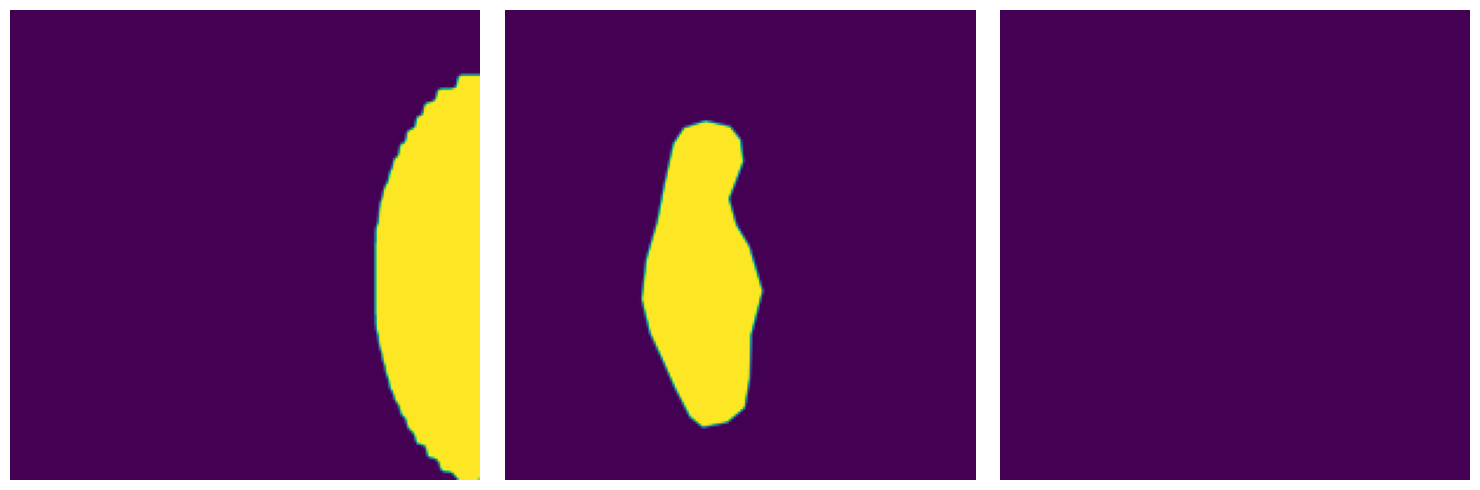

 19%|█▊        | 1711/9210 [00:19<00:55, 134.45it/s]

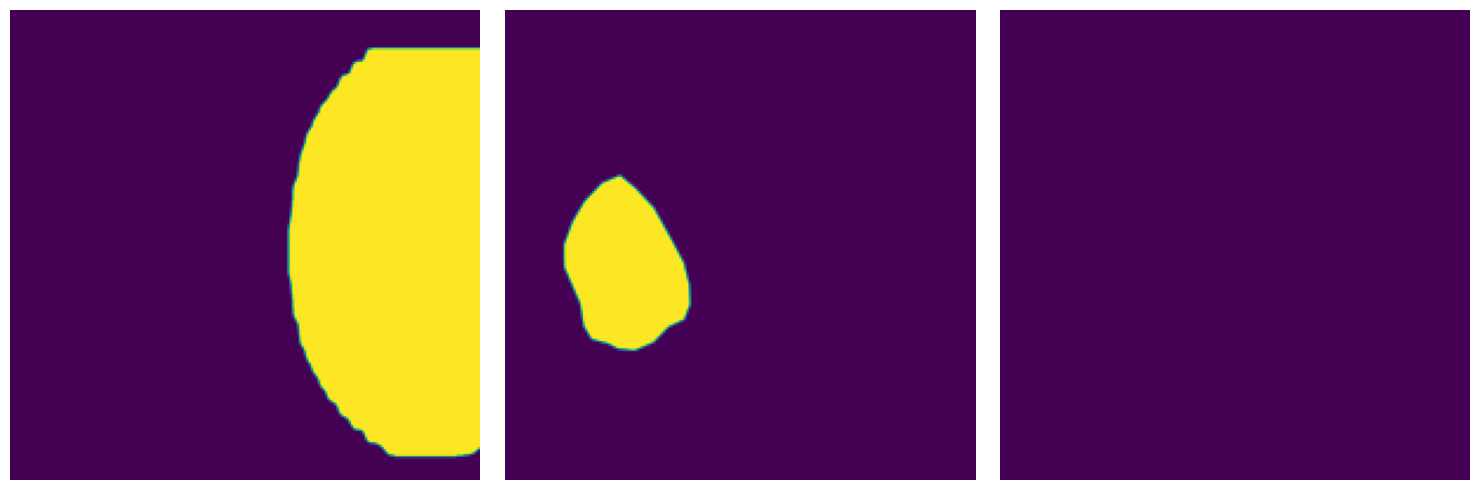

 19%|█▉        | 1735/9210 [00:20<01:08, 109.07it/s]

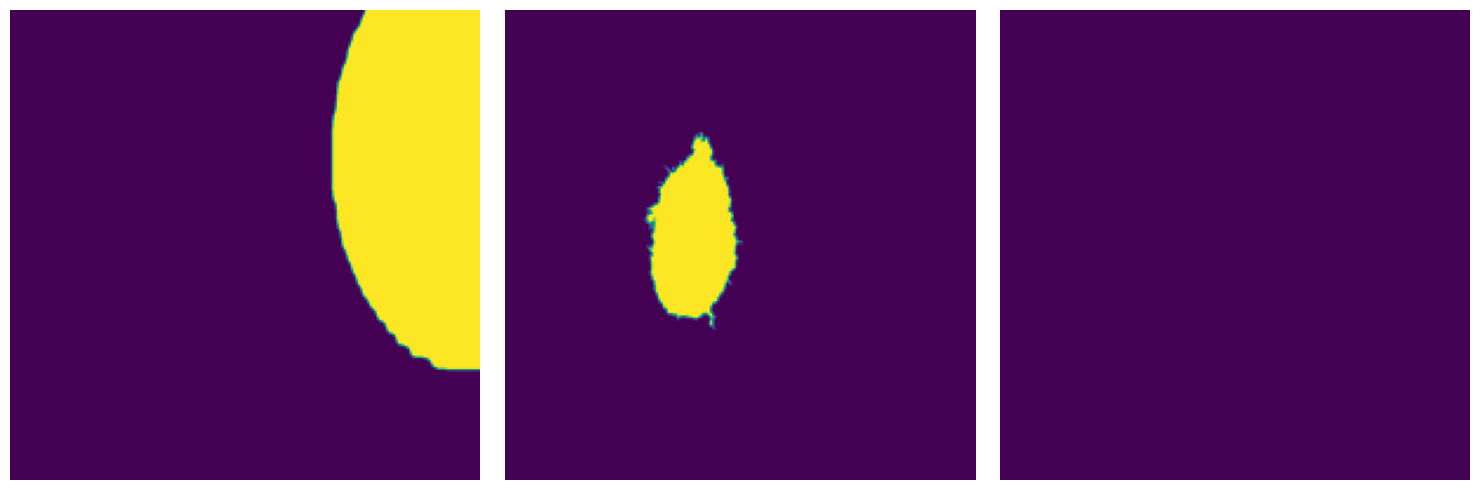

 20%|█▉        | 1804/9210 [00:20<00:53, 139.20it/s]

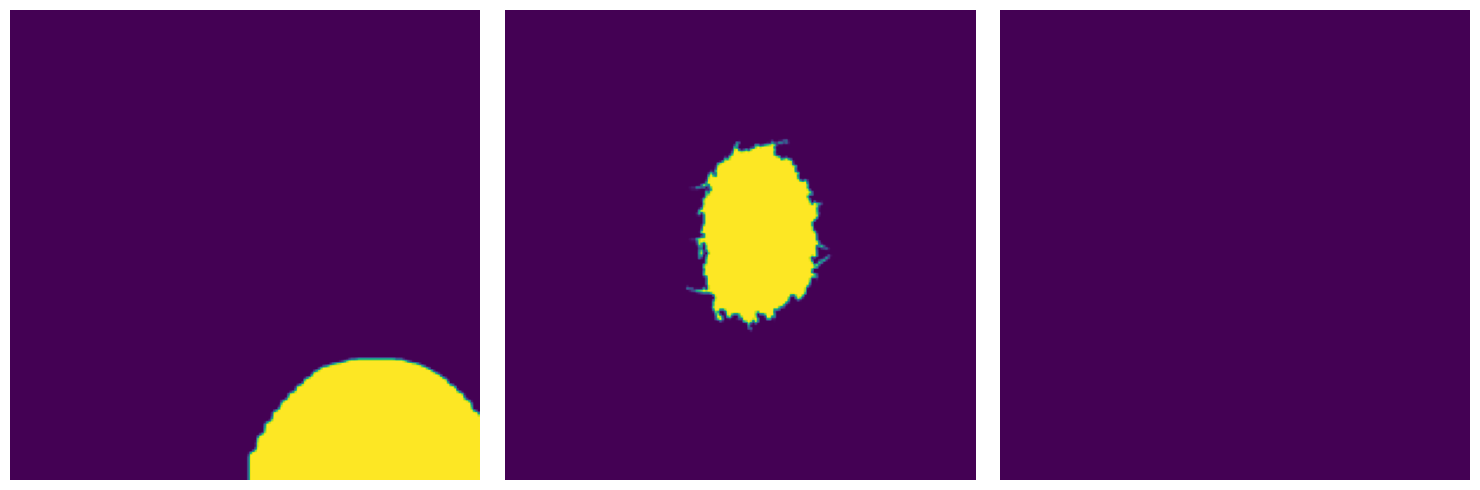

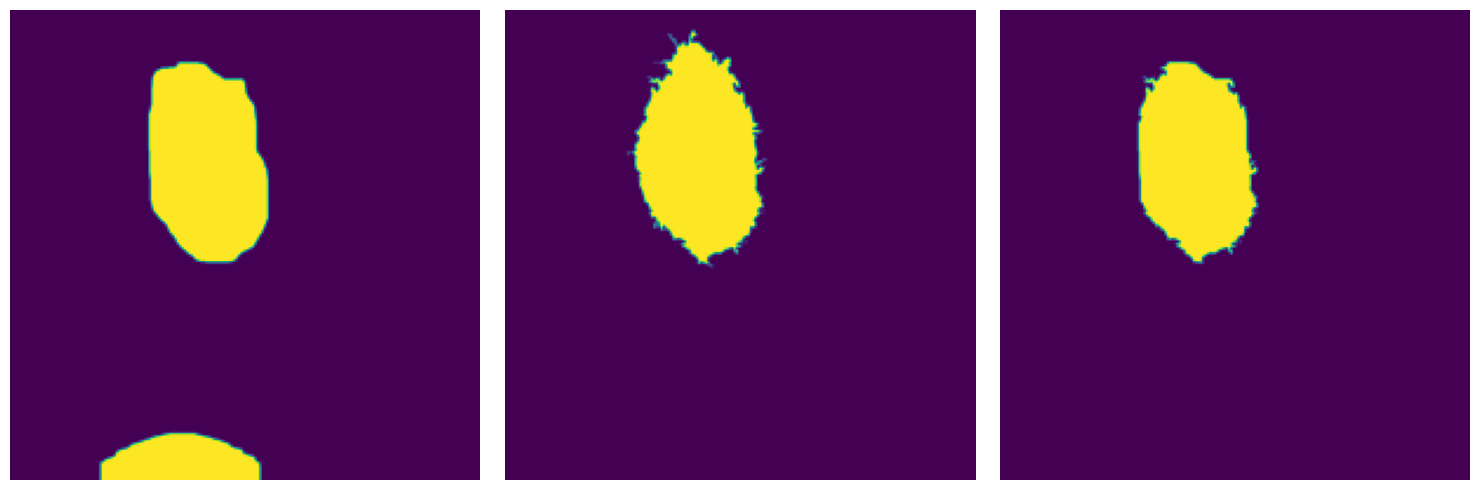

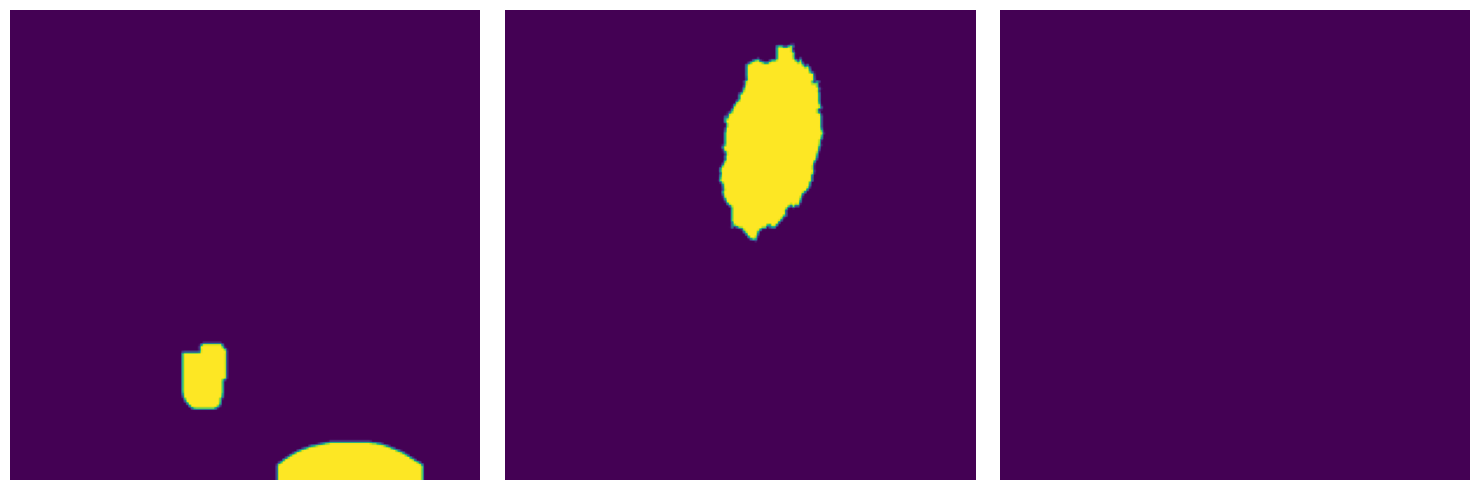

 20%|█▉        | 1830/9210 [00:21<01:47, 68.56it/s] 

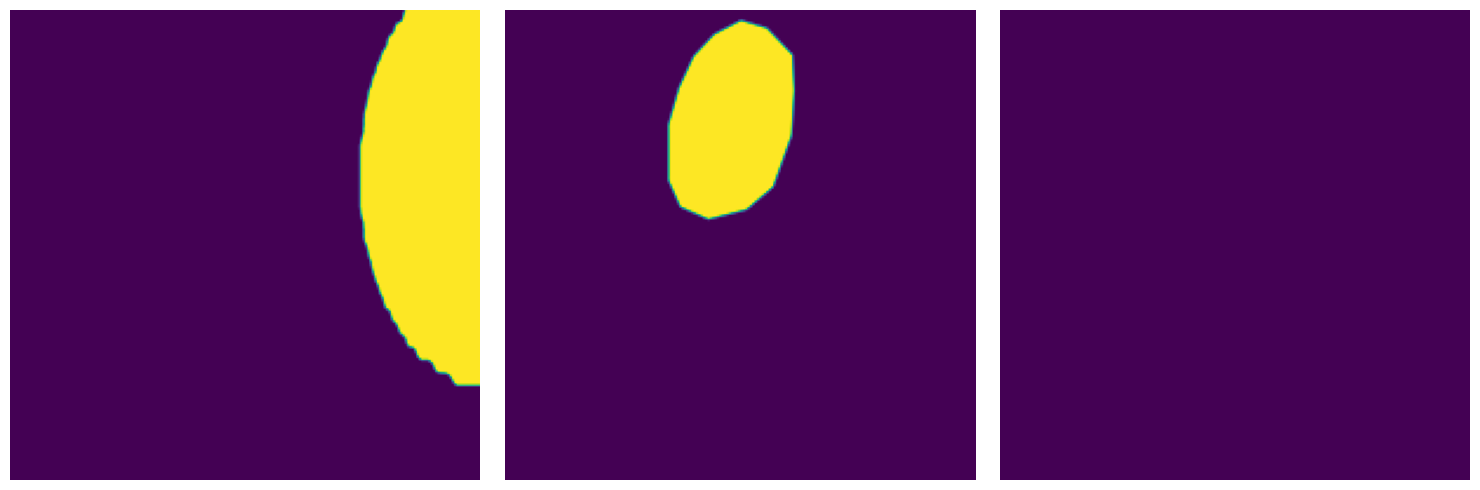

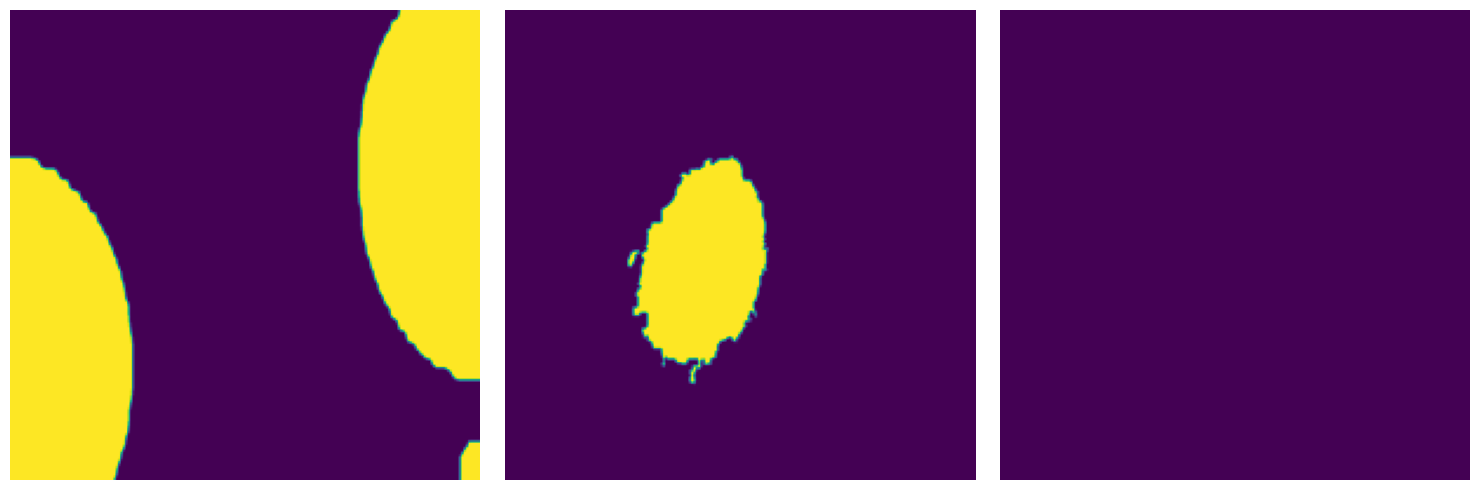

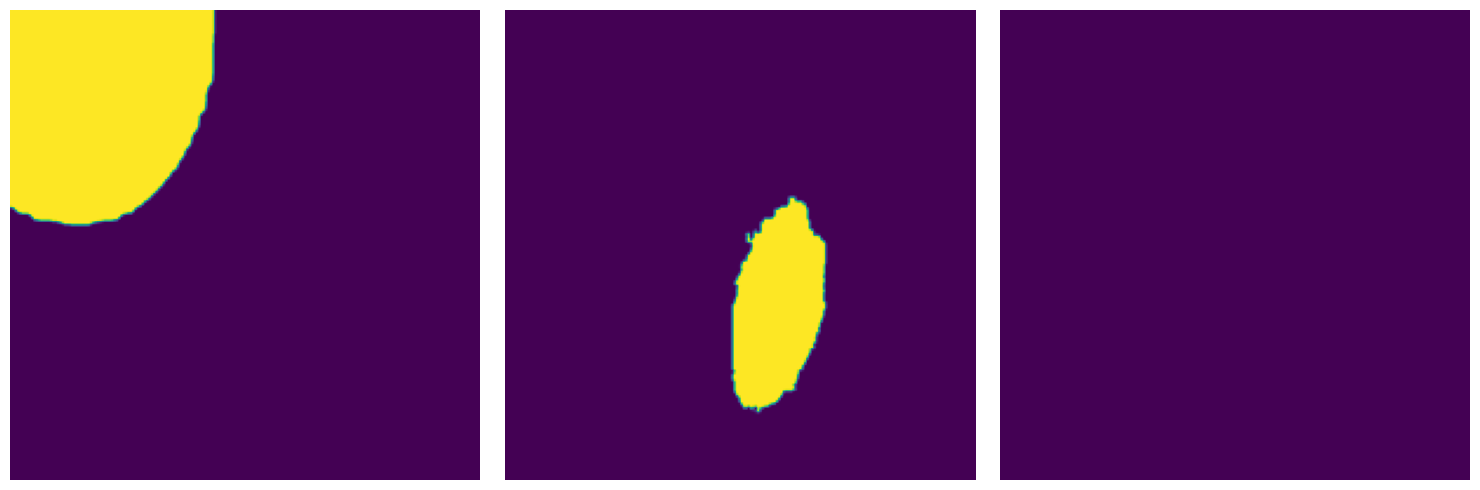

 20%|██        | 1849/9210 [00:22<02:42, 45.22it/s]

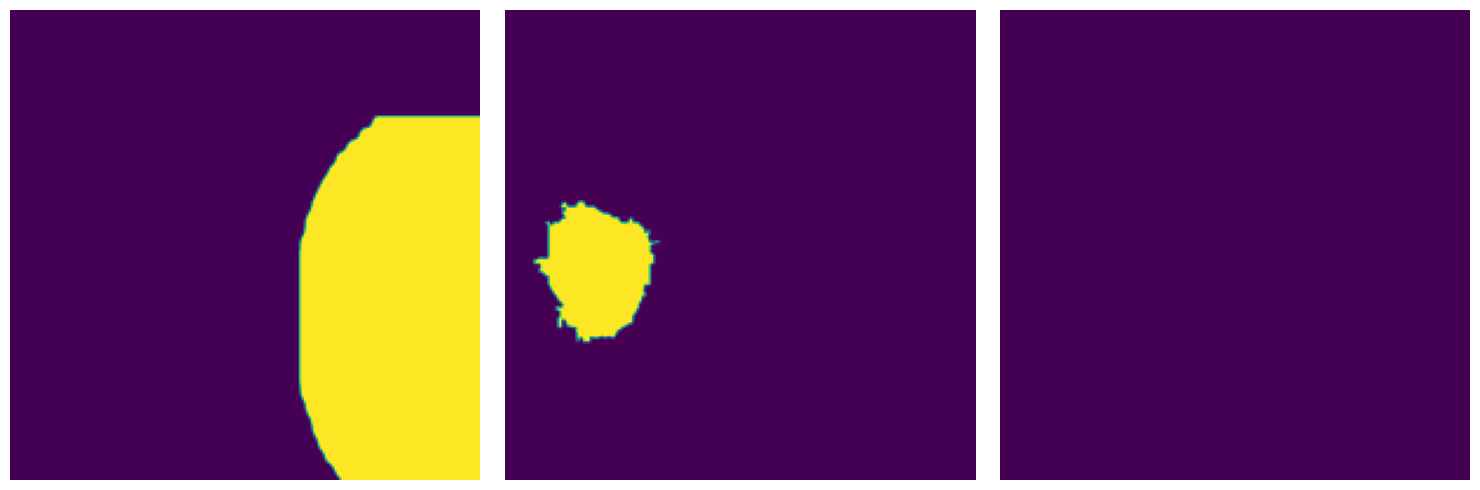

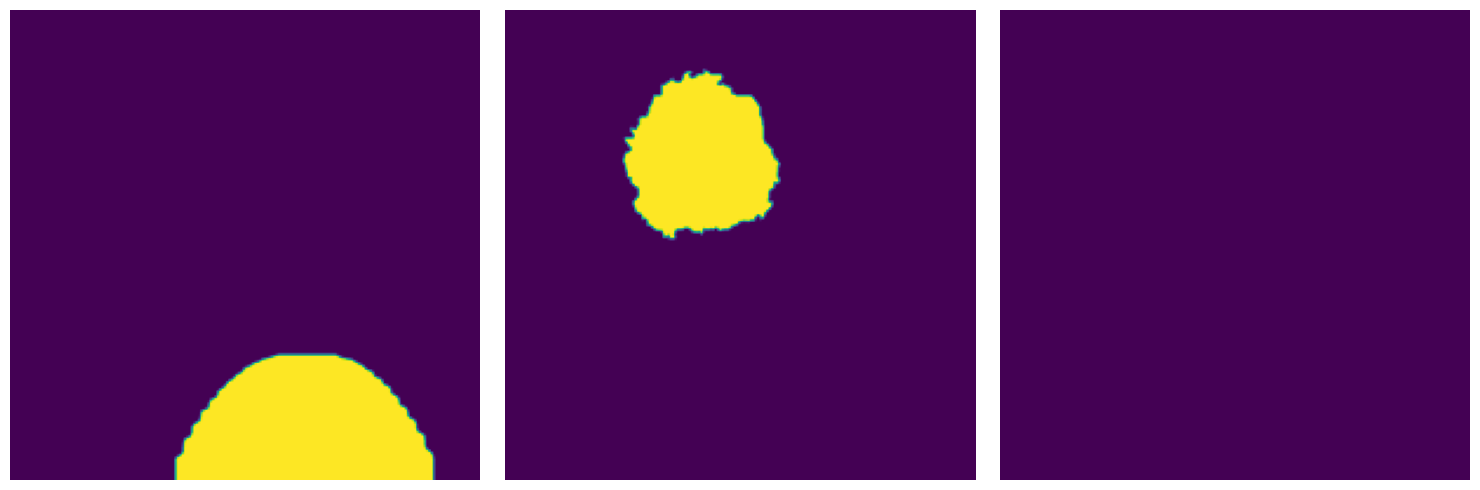

 21%|██▏       | 1962/9210 [00:23<01:10, 102.28it/s]

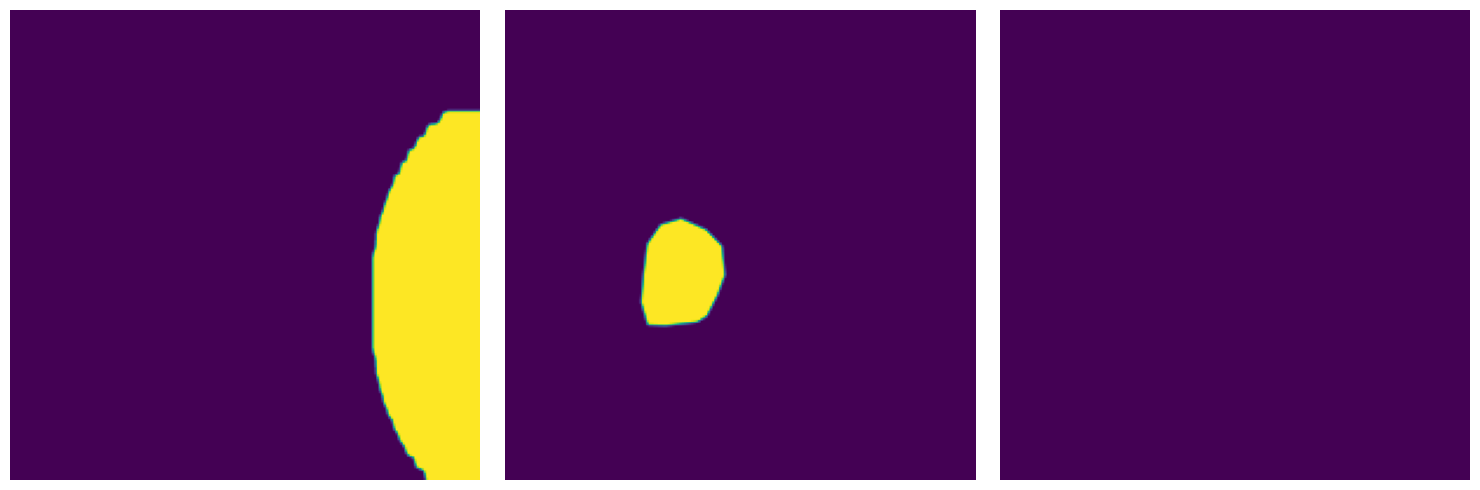

 22%|██▏       | 1993/9210 [00:24<01:25, 84.22it/s] 

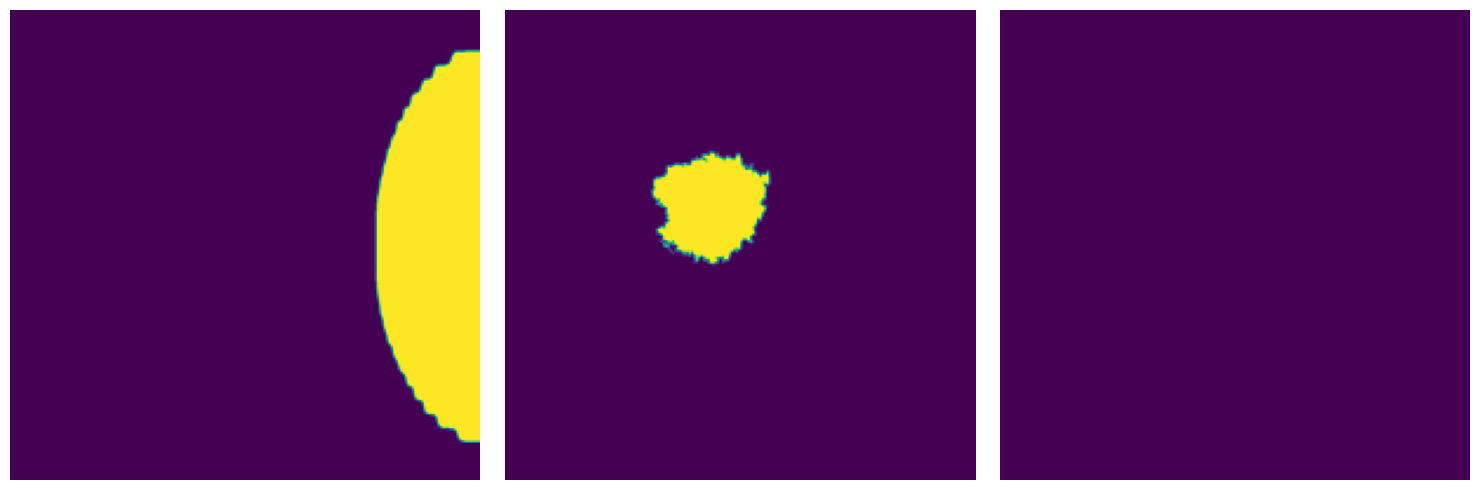

 22%|██▏       | 2020/9210 [00:24<01:39, 72.45it/s]

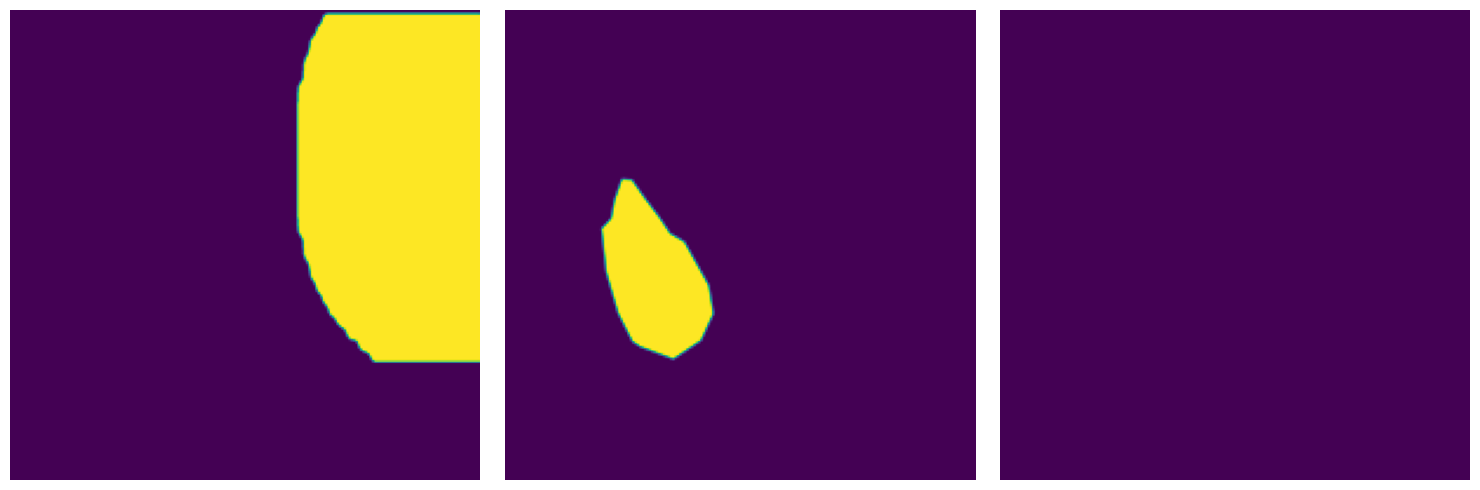

 23%|██▎       | 2143/9210 [00:25<00:46, 152.61it/s]

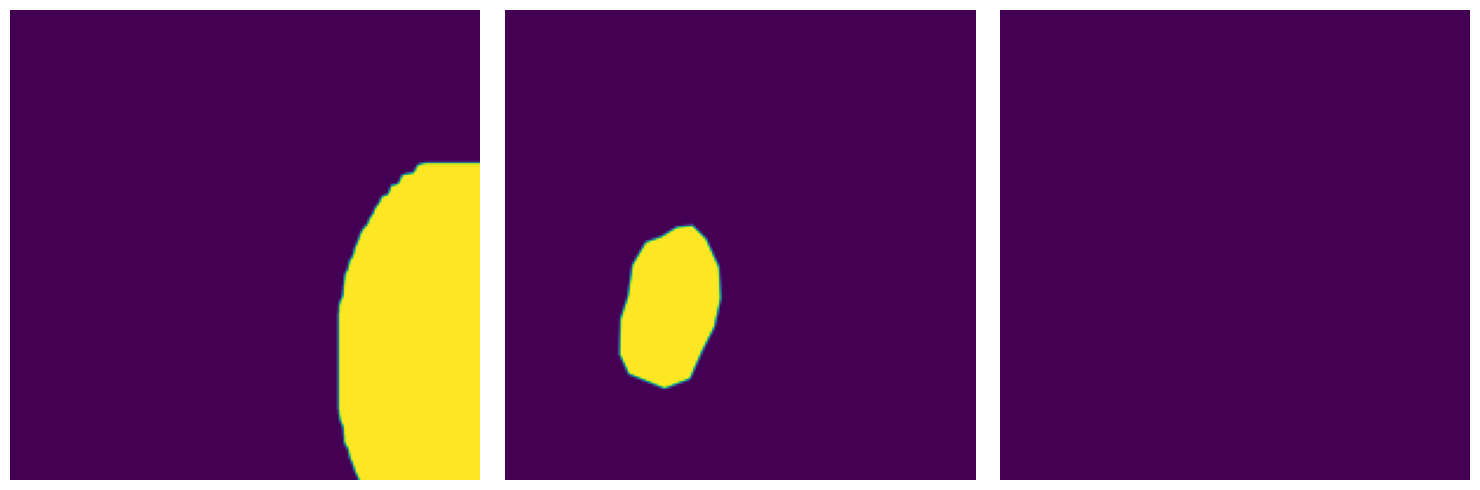

 24%|██▎       | 2175/9210 [00:25<01:05, 107.74it/s]

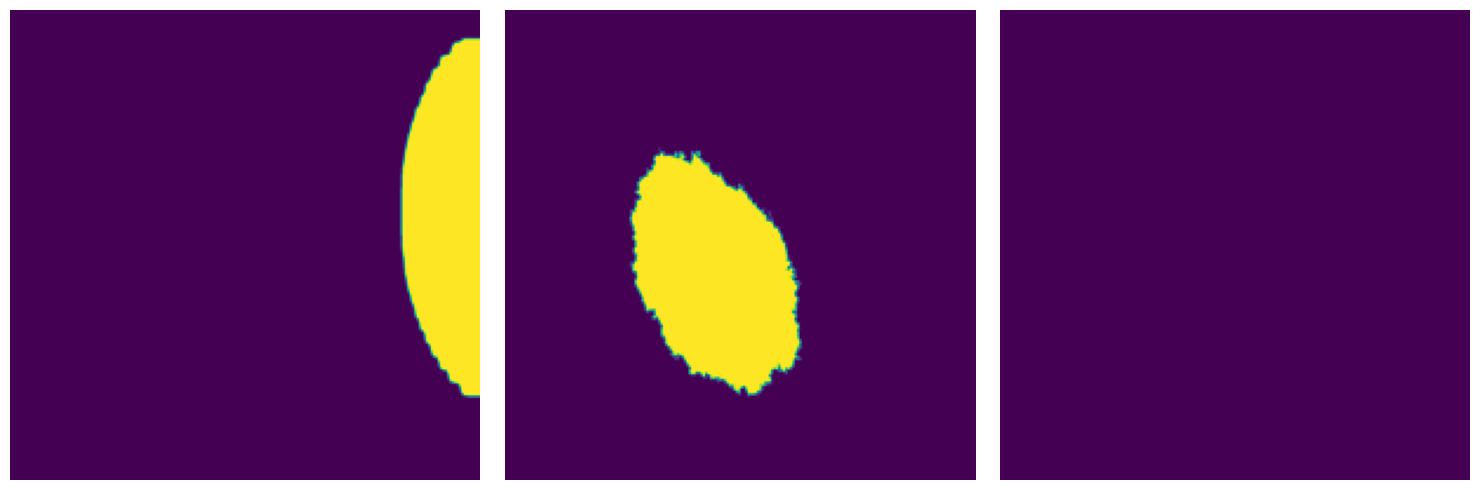

 24%|██▍       | 2199/9210 [00:26<01:24, 82.72it/s] 

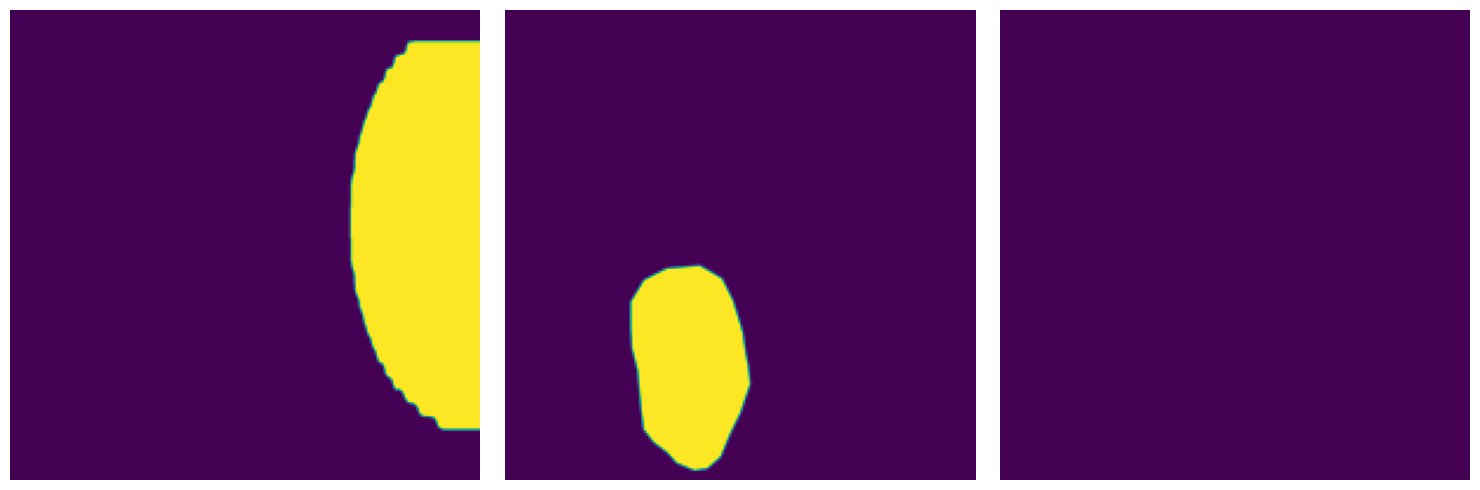

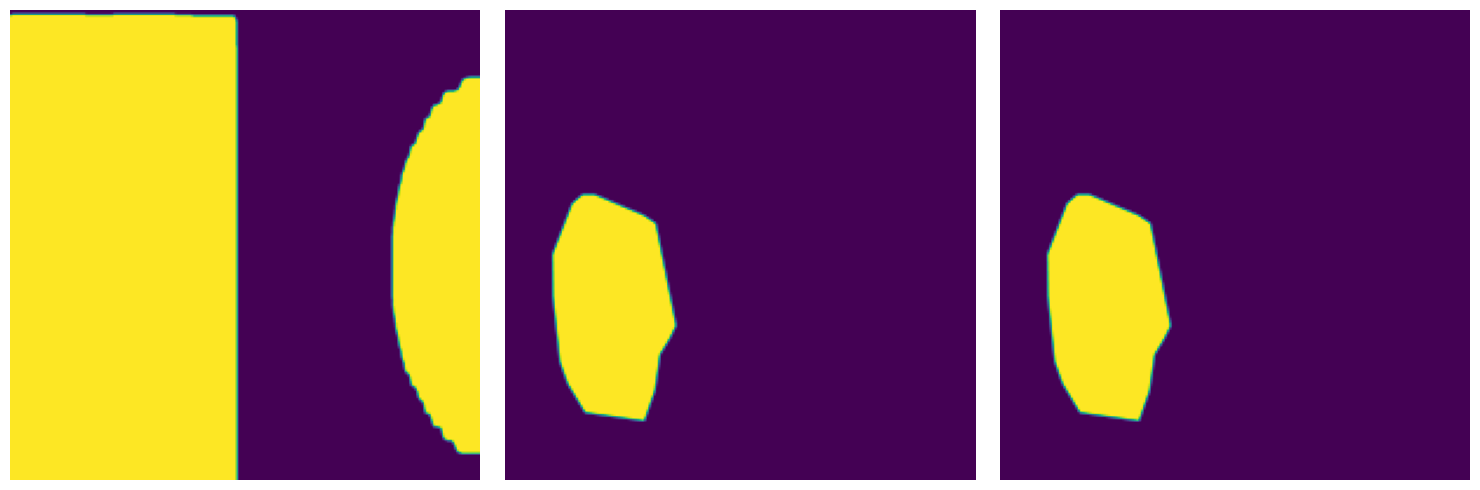

 24%|██▍       | 2218/9210 [00:27<03:02, 38.41it/s]

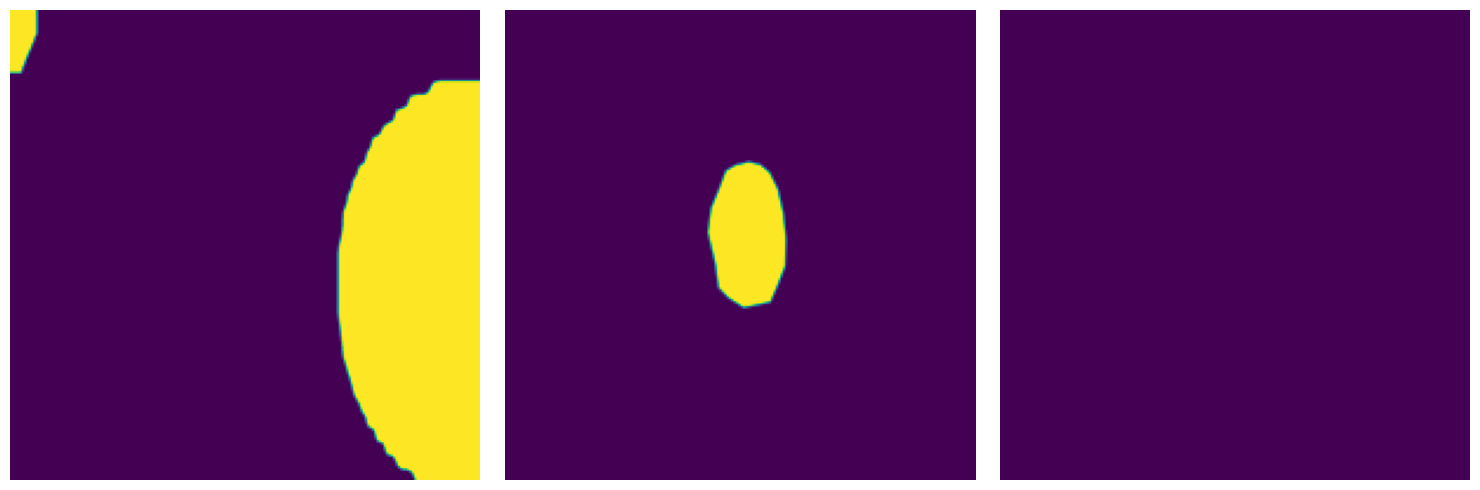

 24%|██▍       | 2243/9210 [00:28<02:51, 40.51it/s]

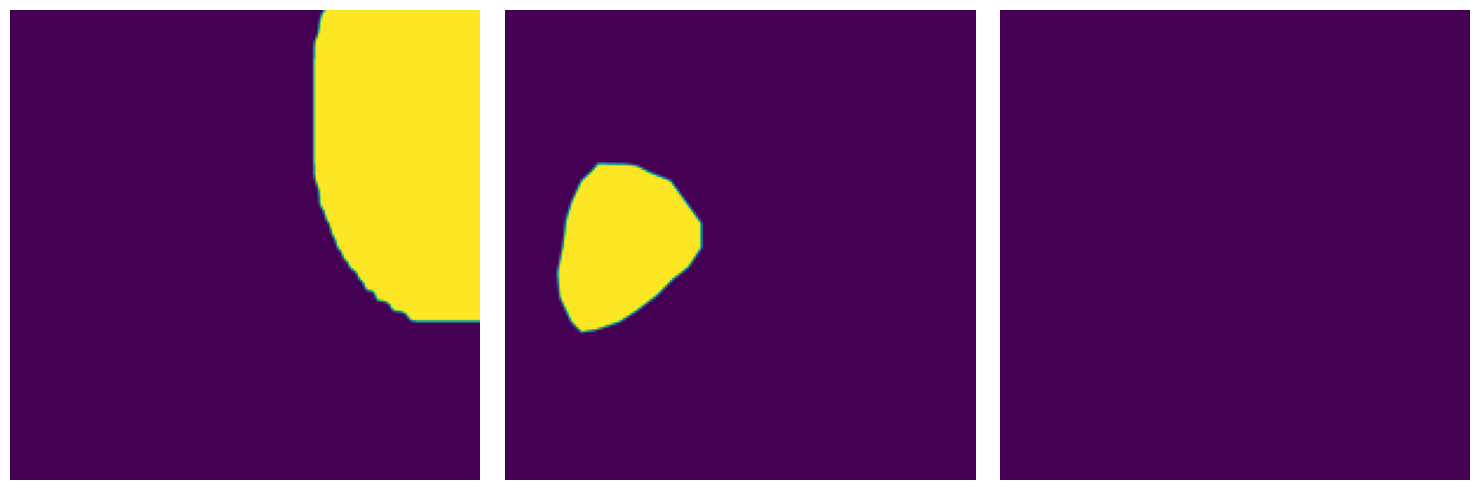

 24%|██▍       | 2254/9210 [00:28<02:57, 39.17it/s]

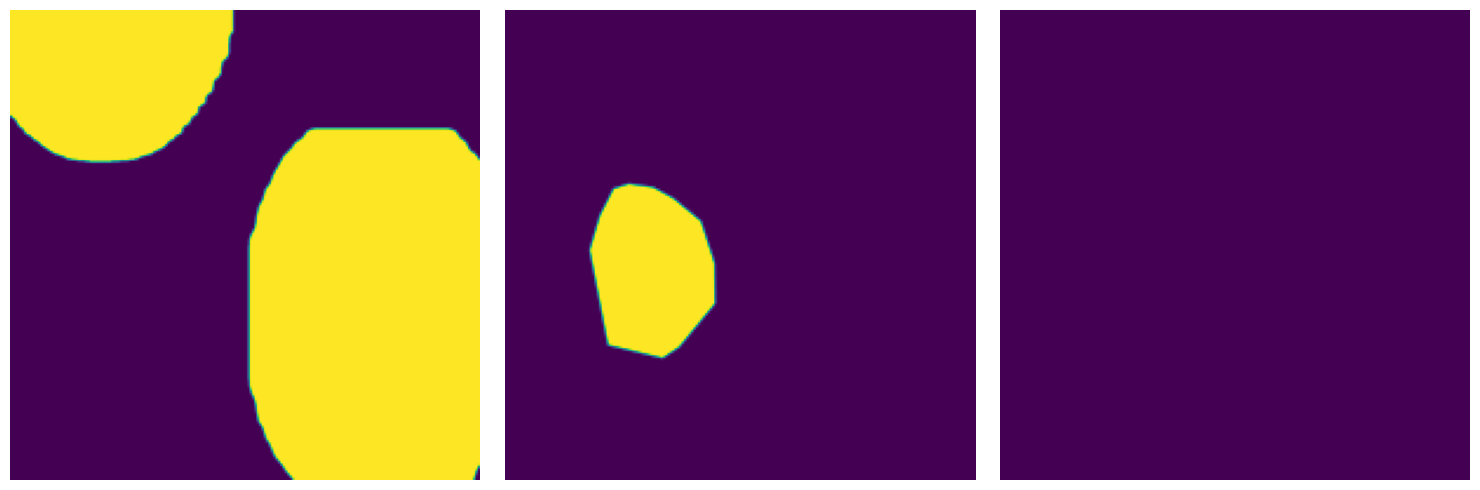

 25%|██▌       | 2311/9210 [00:29<01:45, 65.24it/s]

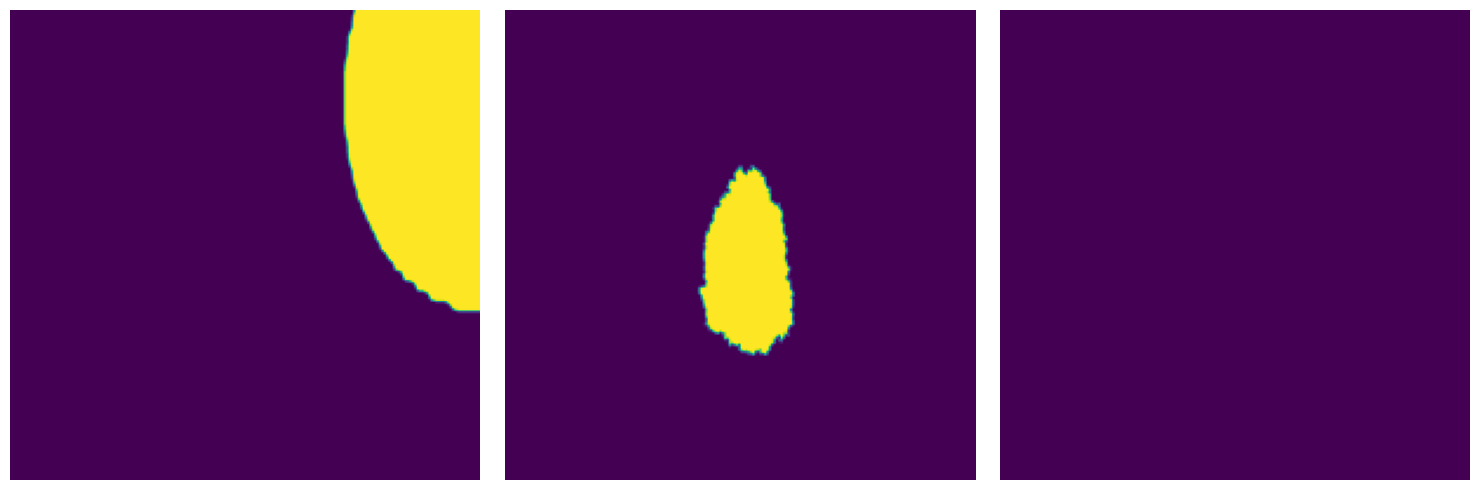

 25%|██▌       | 2330/9210 [00:29<01:50, 62.30it/s]

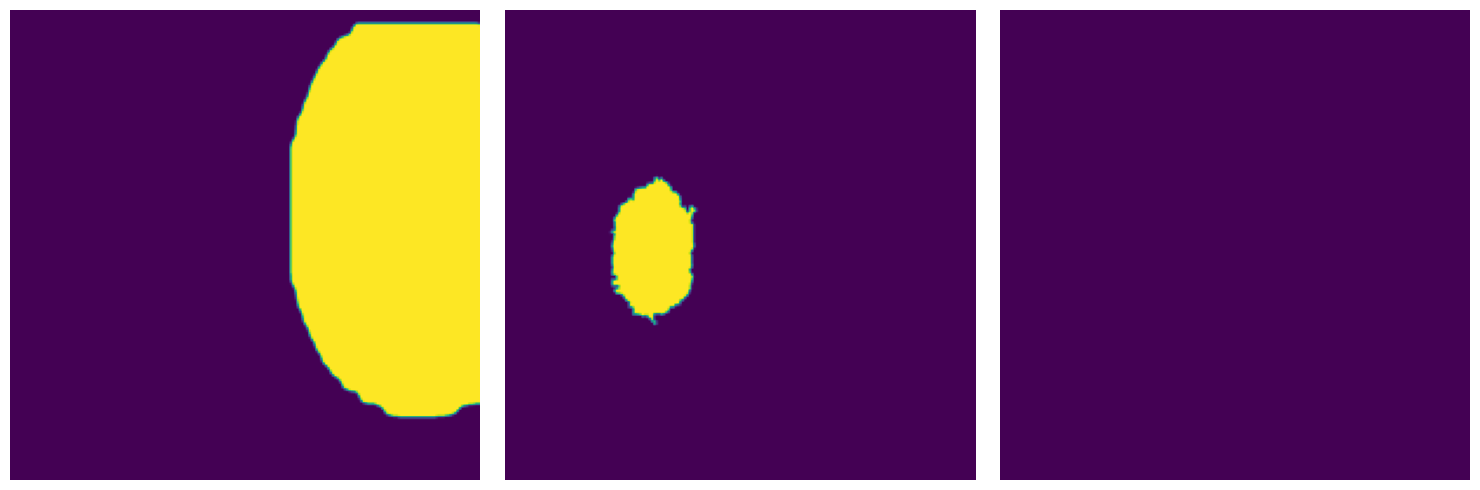

 25%|██▌       | 2347/9210 [00:30<02:12, 51.97it/s]

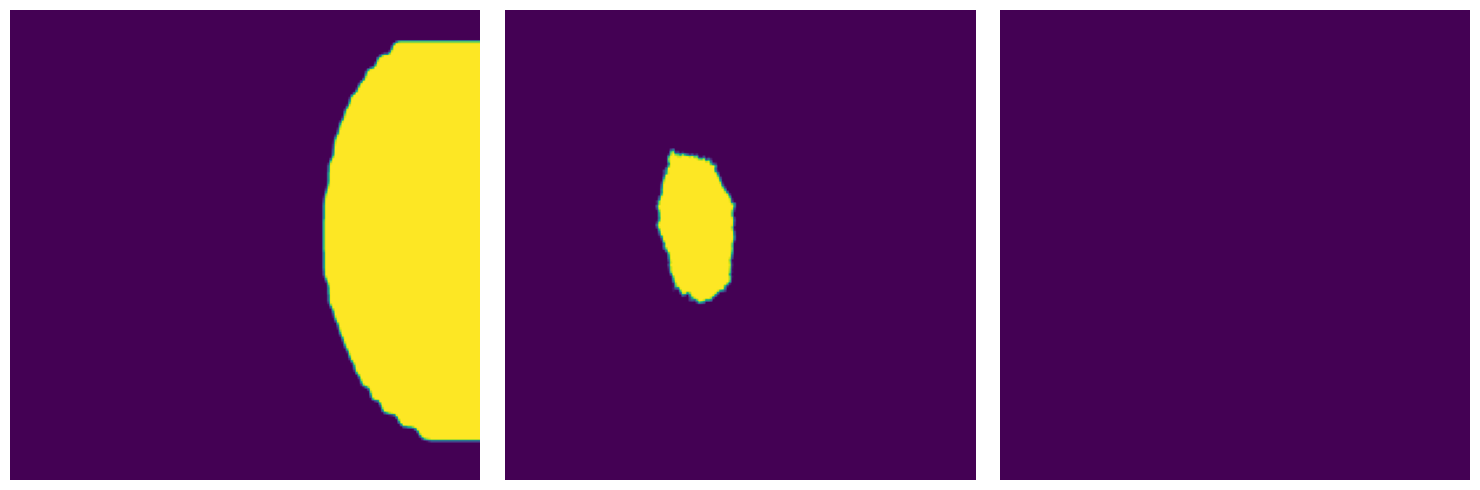

 26%|██▌       | 2359/9210 [00:30<02:40, 42.62it/s]

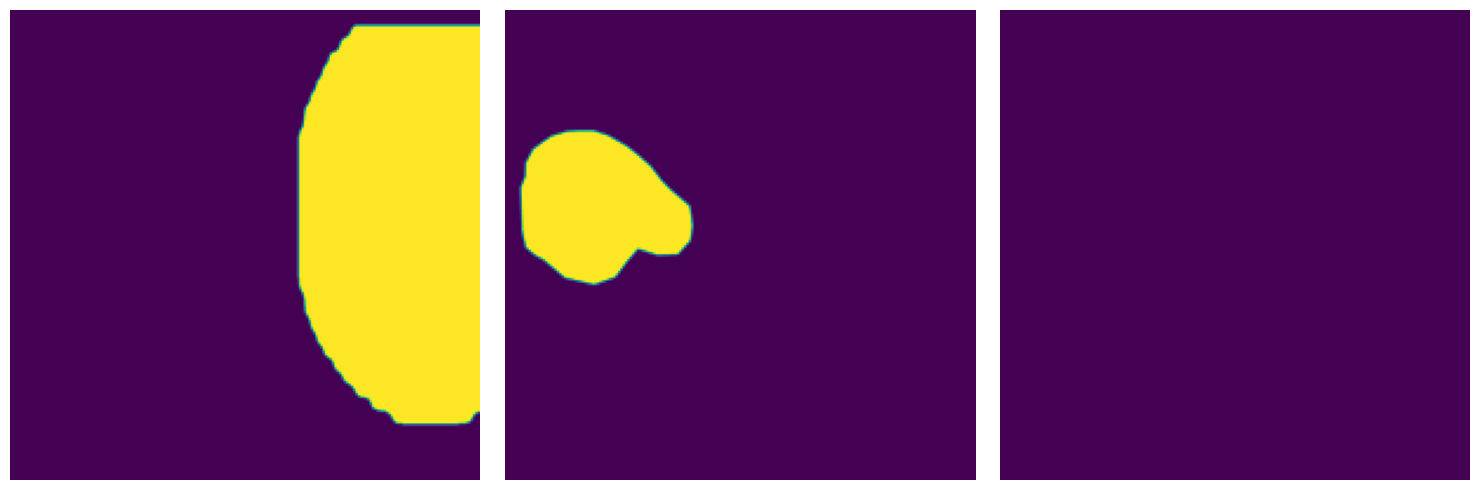

 26%|██▋       | 2425/9210 [00:31<01:19, 84.95it/s]

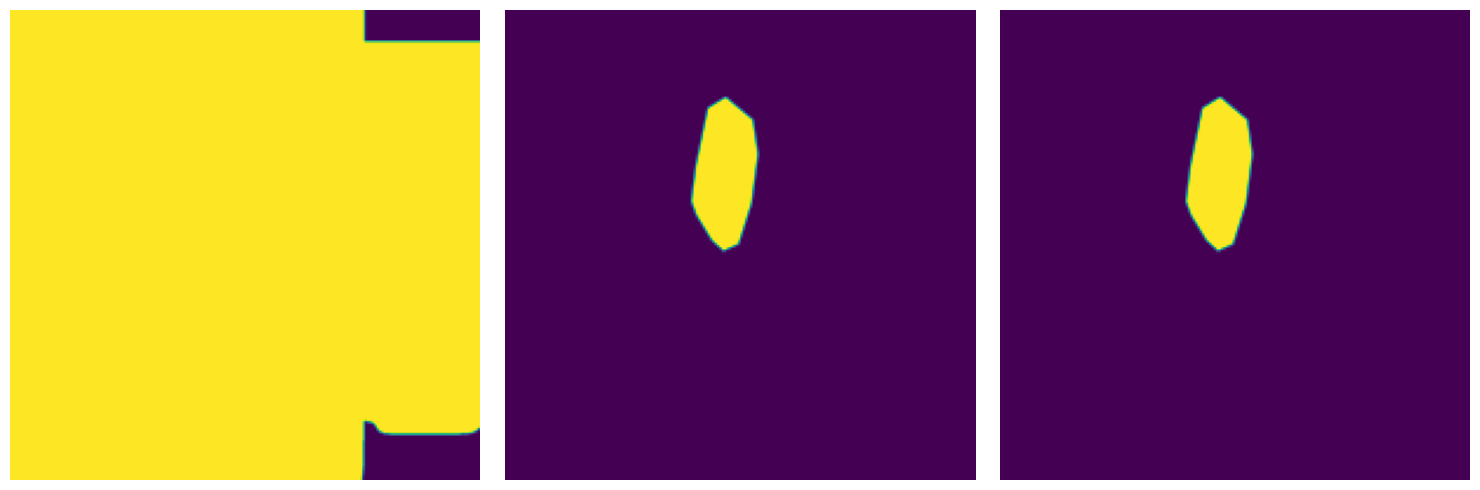

 28%|██▊       | 2544/9210 [00:31<00:42, 157.62it/s]

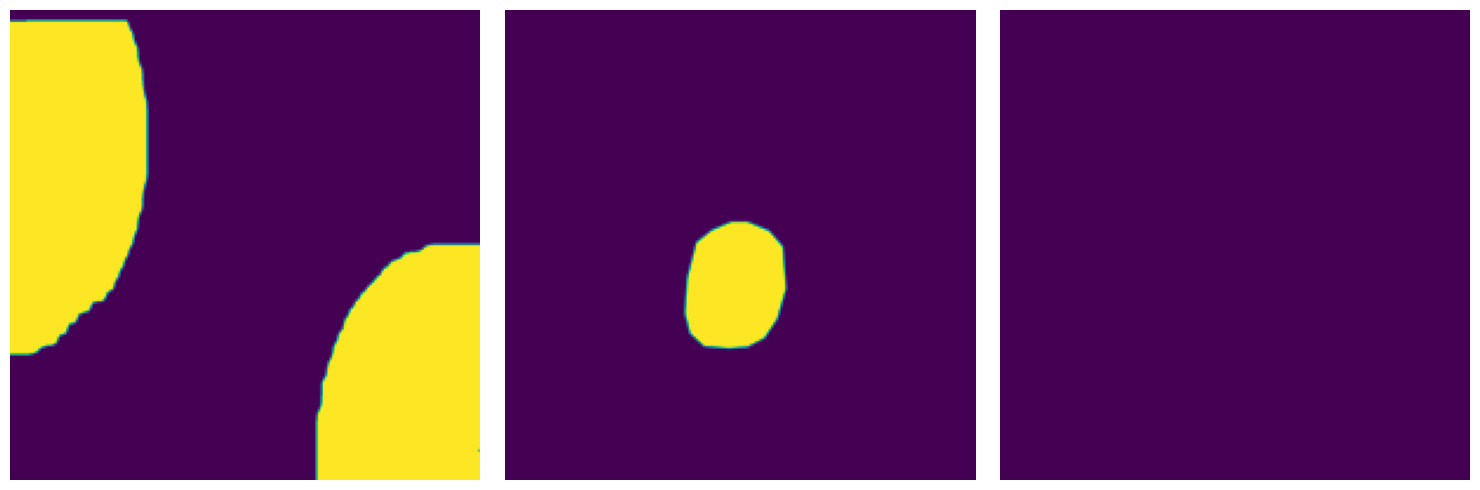

 29%|██▉       | 2678/9210 [00:32<00:28, 230.53it/s]

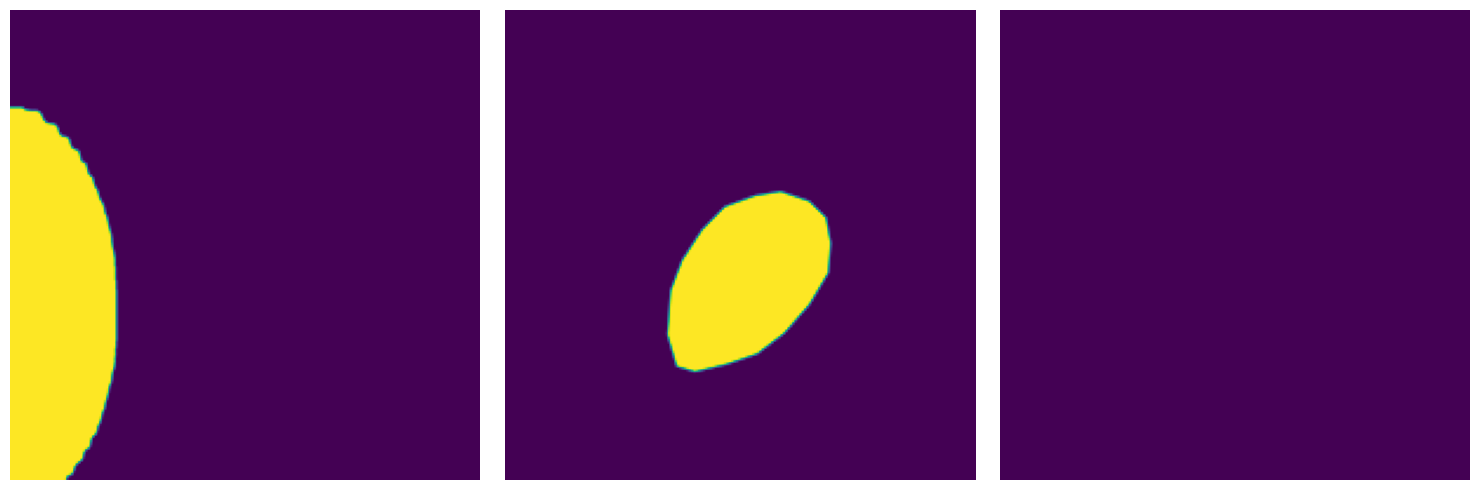

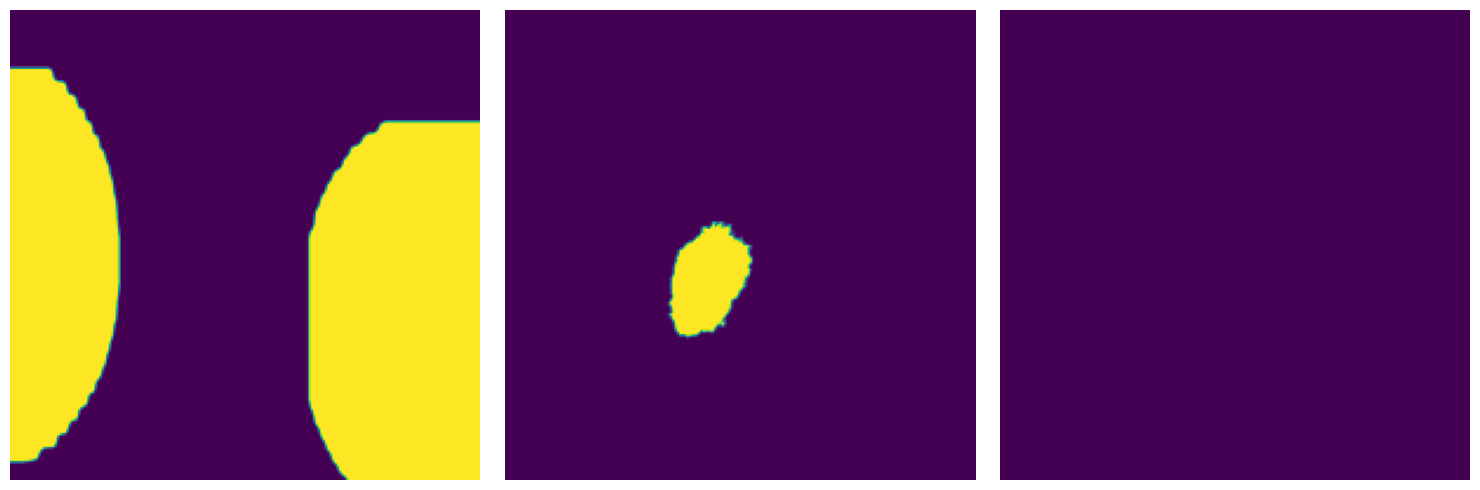

 30%|███       | 2800/9210 [00:33<00:37, 172.86it/s]

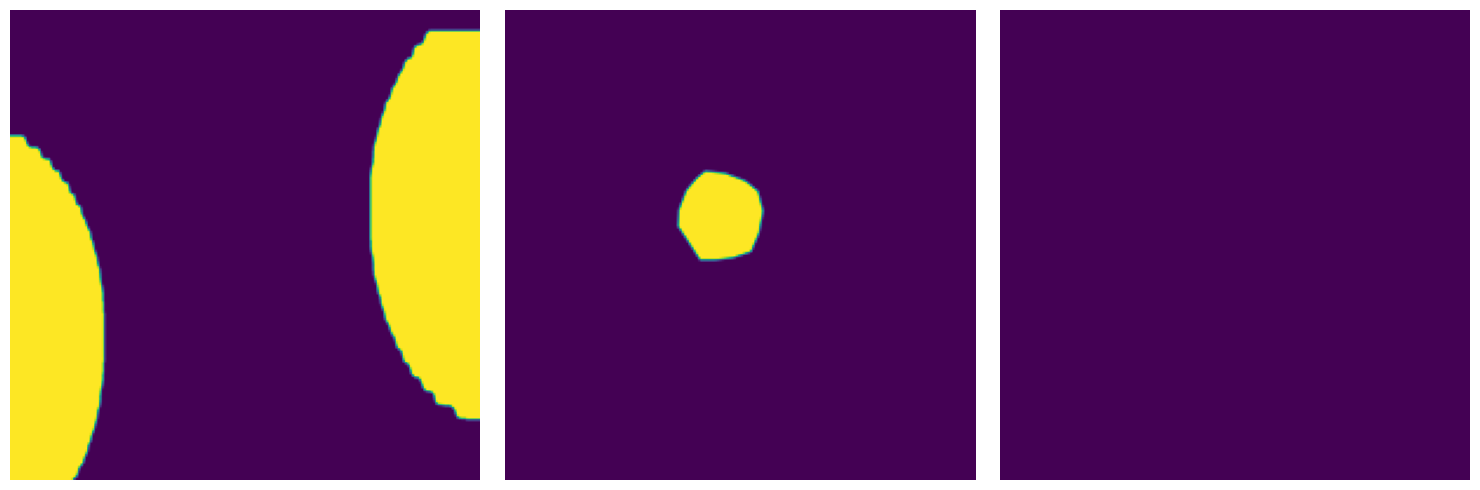

 31%|███▏      | 2885/9210 [00:34<00:34, 184.91it/s]

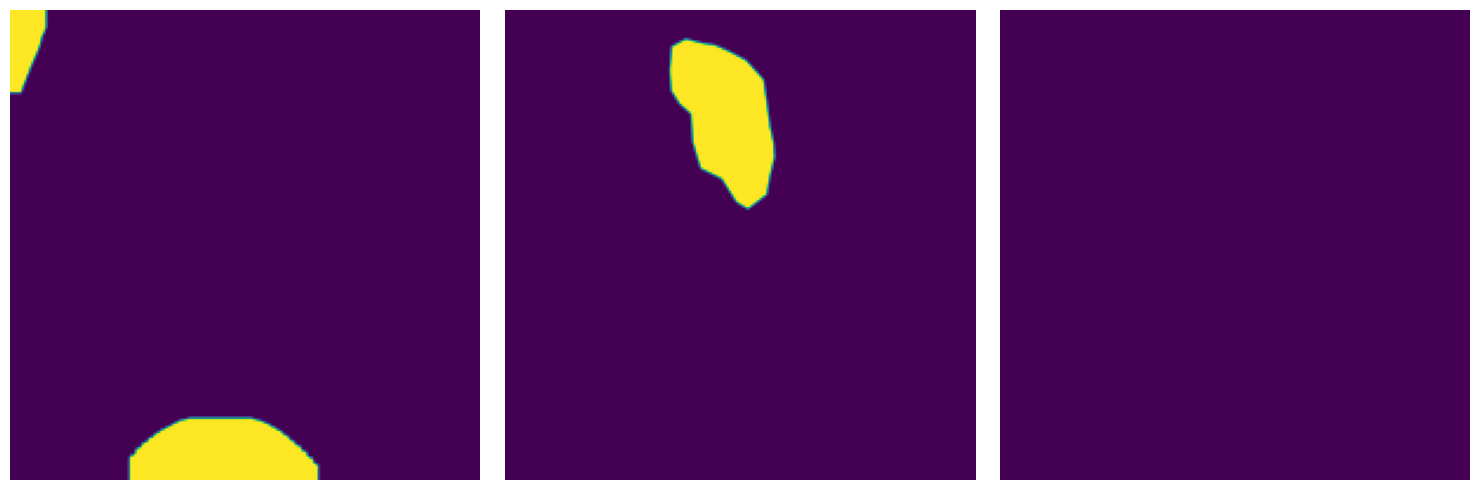

 32%|███▏      | 2919/9210 [00:34<00:43, 144.95it/s]

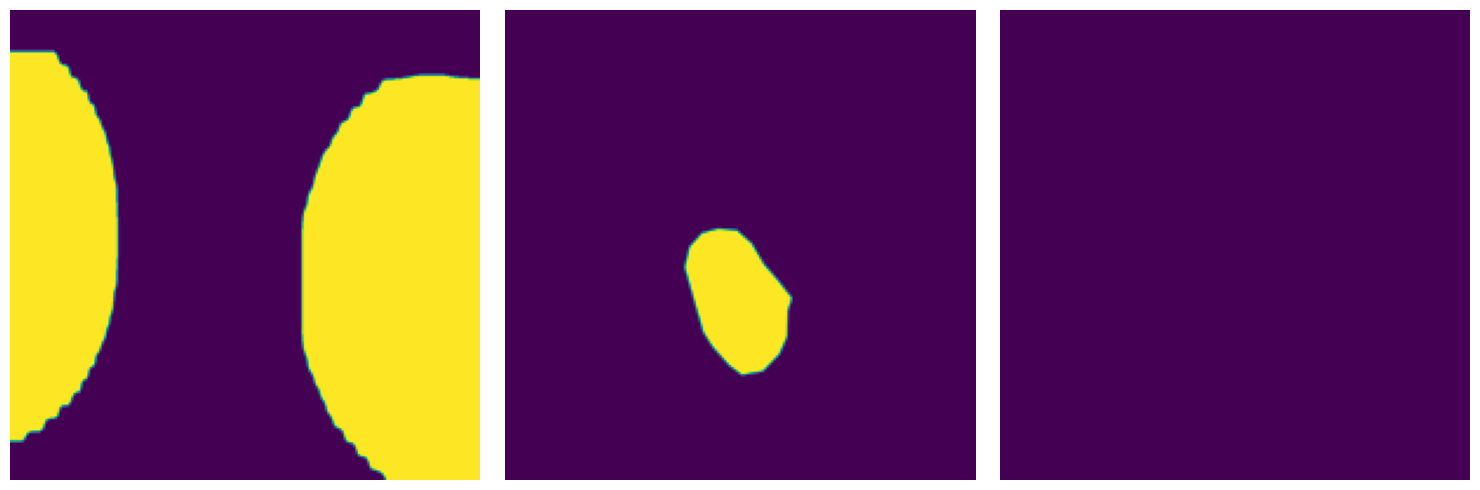

 32%|███▏      | 2946/9210 [00:34<01:02, 100.24it/s]

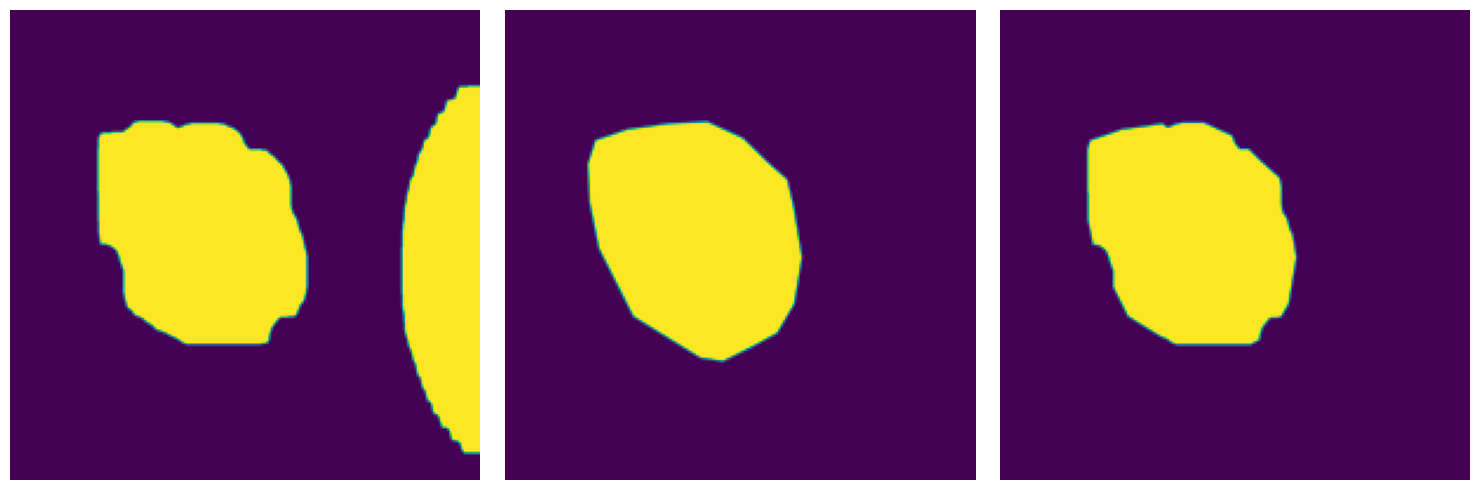

 33%|███▎      | 3016/9210 [00:35<00:47, 129.55it/s]

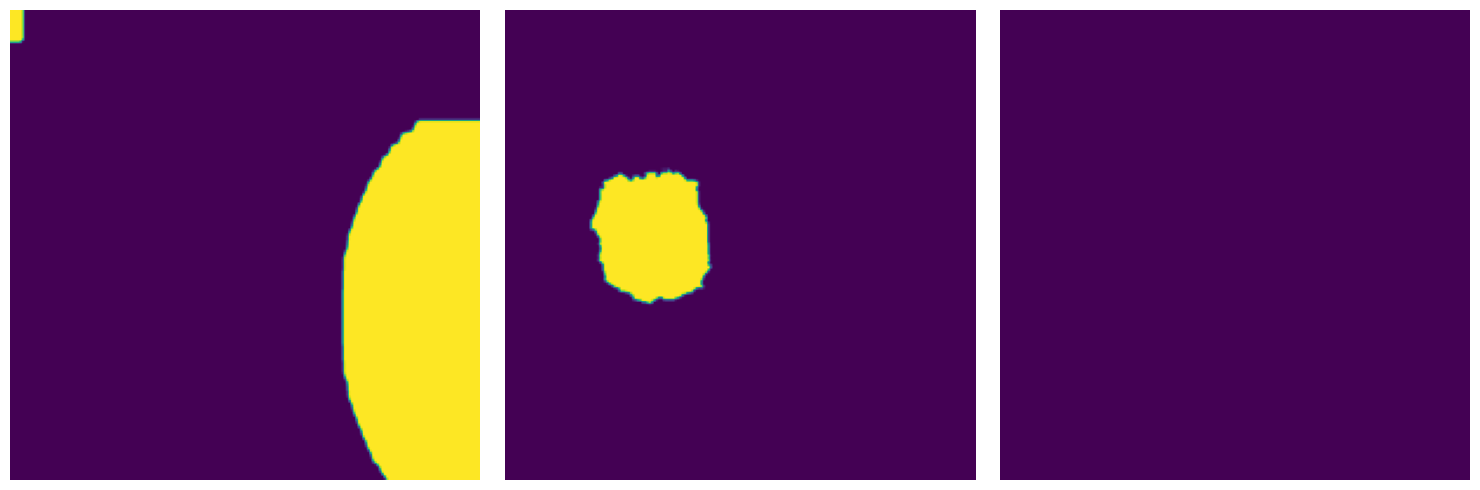

 34%|███▎      | 3092/9210 [00:35<00:39, 155.82it/s]

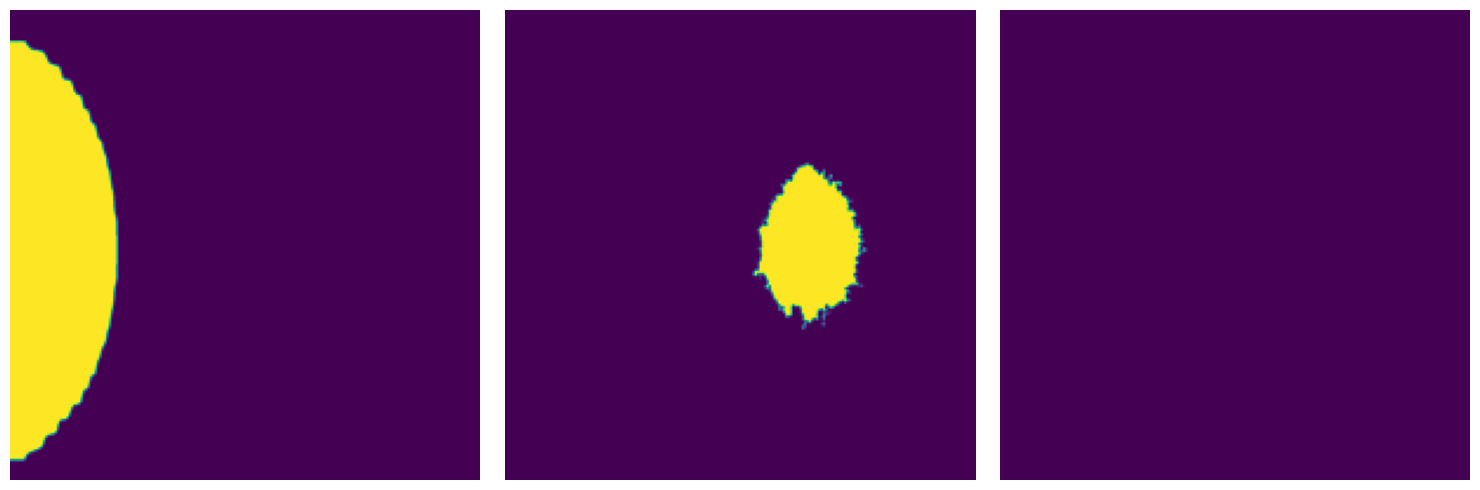

 34%|███▍      | 3171/9210 [00:36<00:35, 172.45it/s]

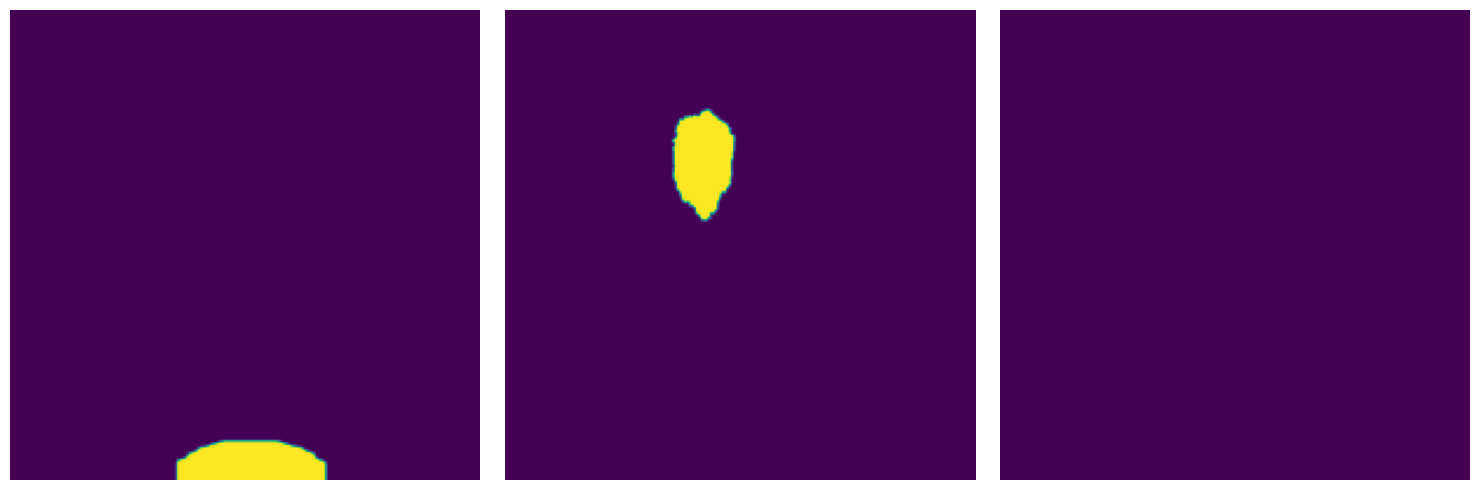

 37%|███▋      | 3450/9210 [00:37<00:15, 365.88it/s]

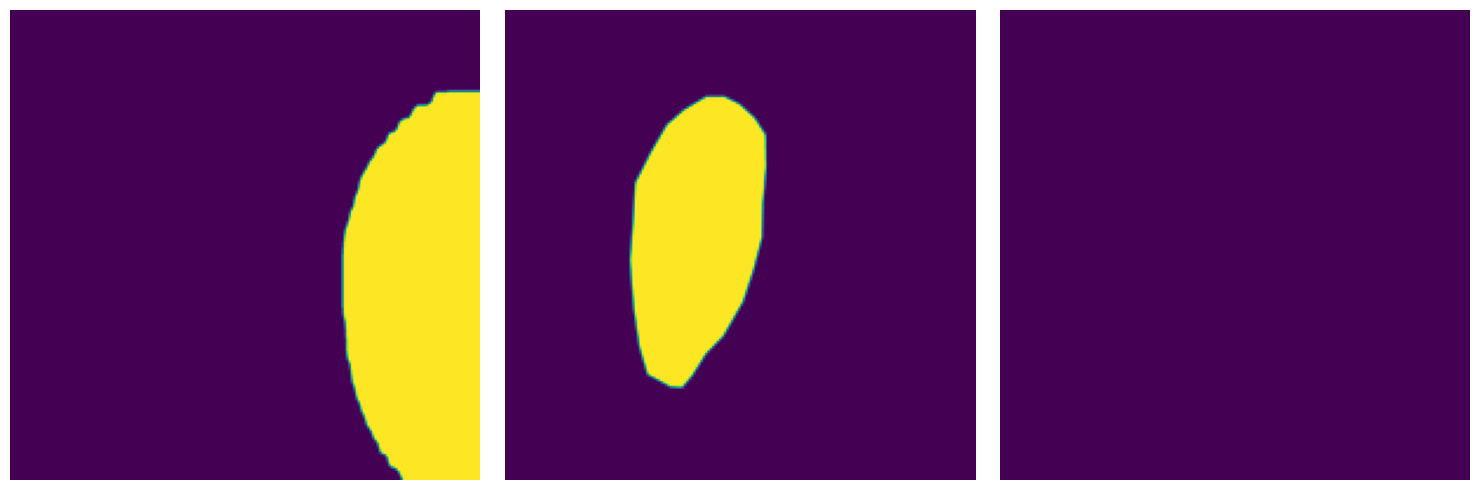

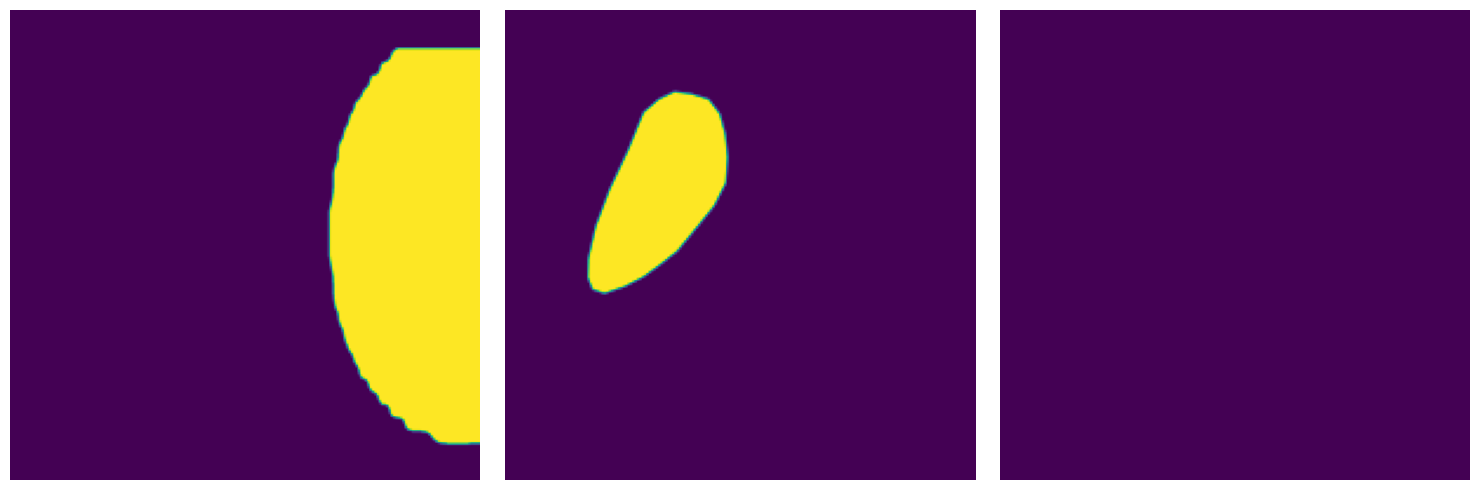

 38%|███▊      | 3495/9210 [00:38<00:44, 128.14it/s]

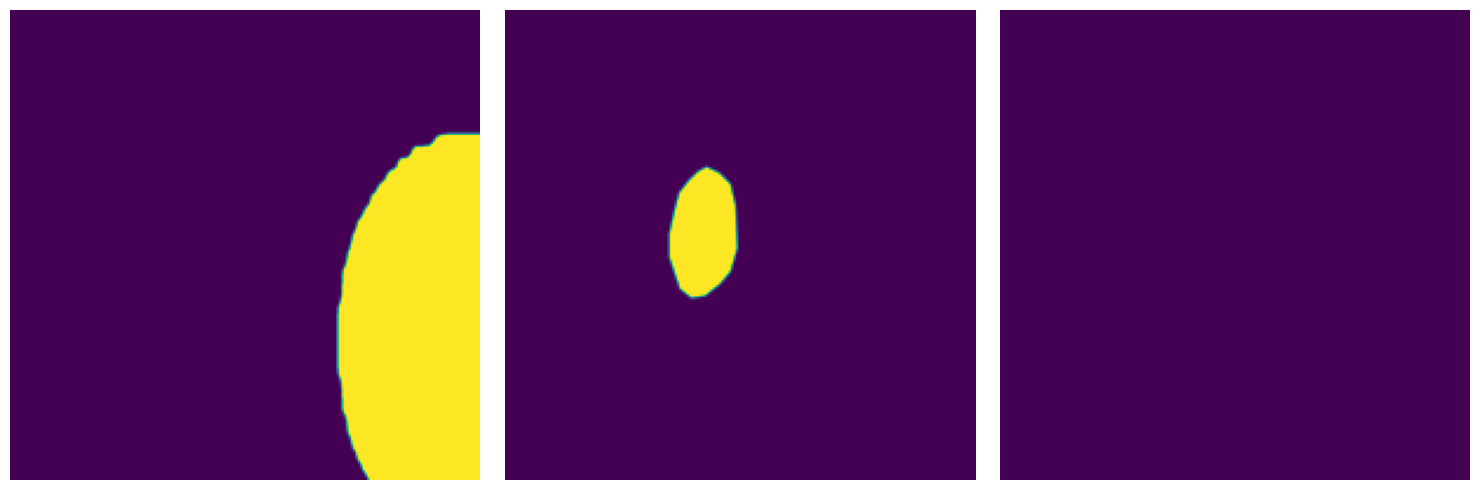

 39%|███▉      | 3633/9210 [00:38<00:30, 181.49it/s]

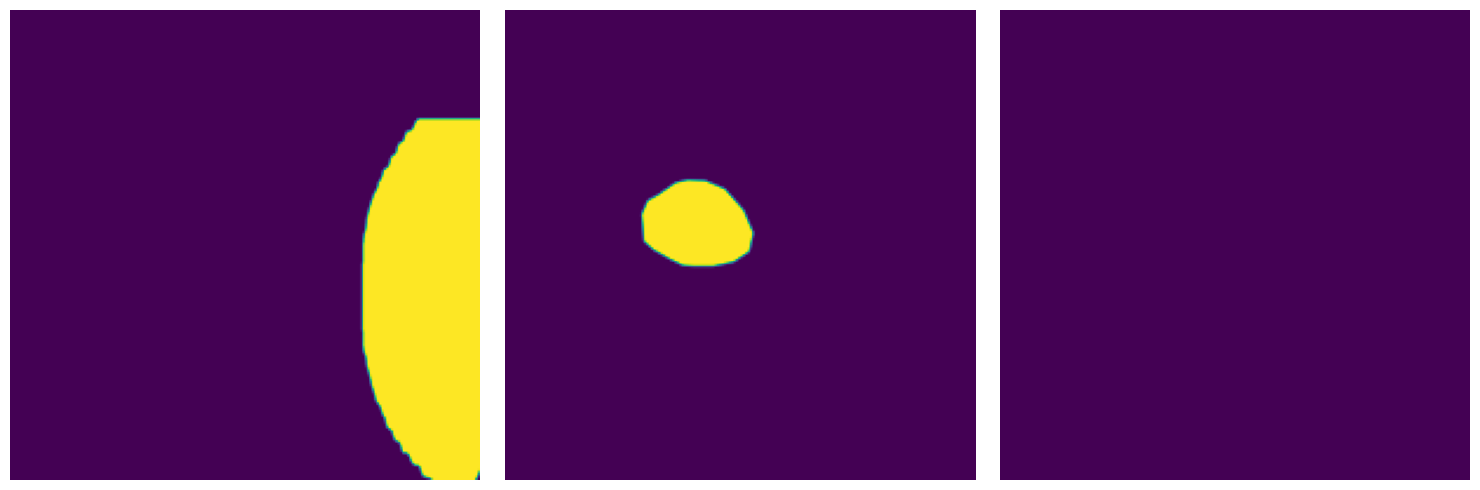

 40%|███▉      | 3675/9210 [00:39<00:42, 128.74it/s]

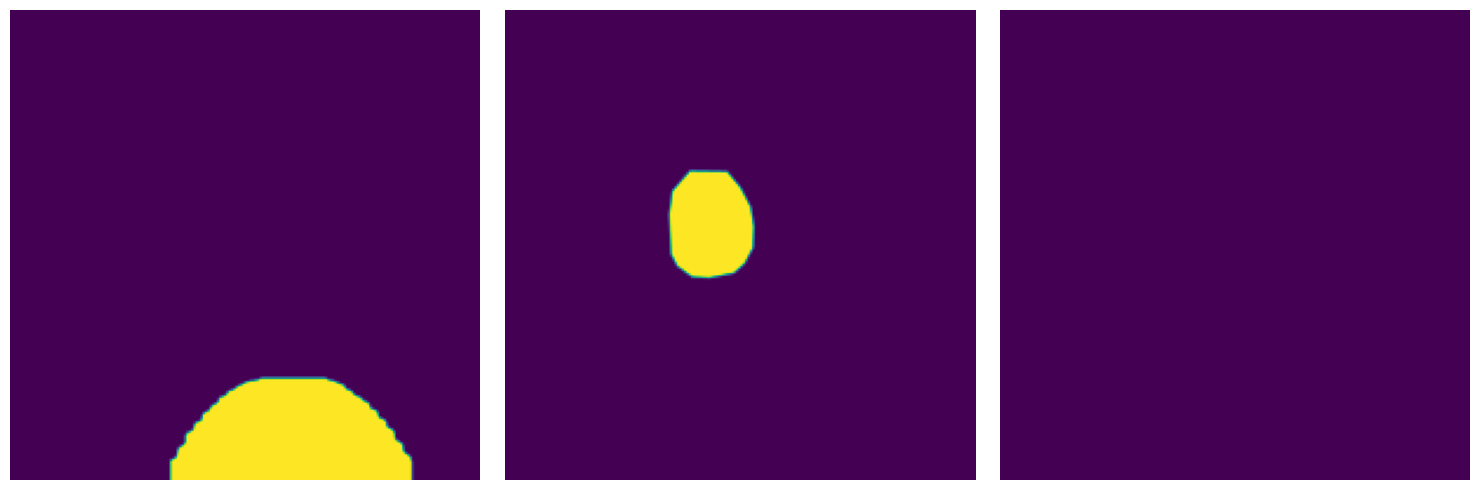

 40%|████      | 3704/9210 [00:39<00:48, 113.55it/s]

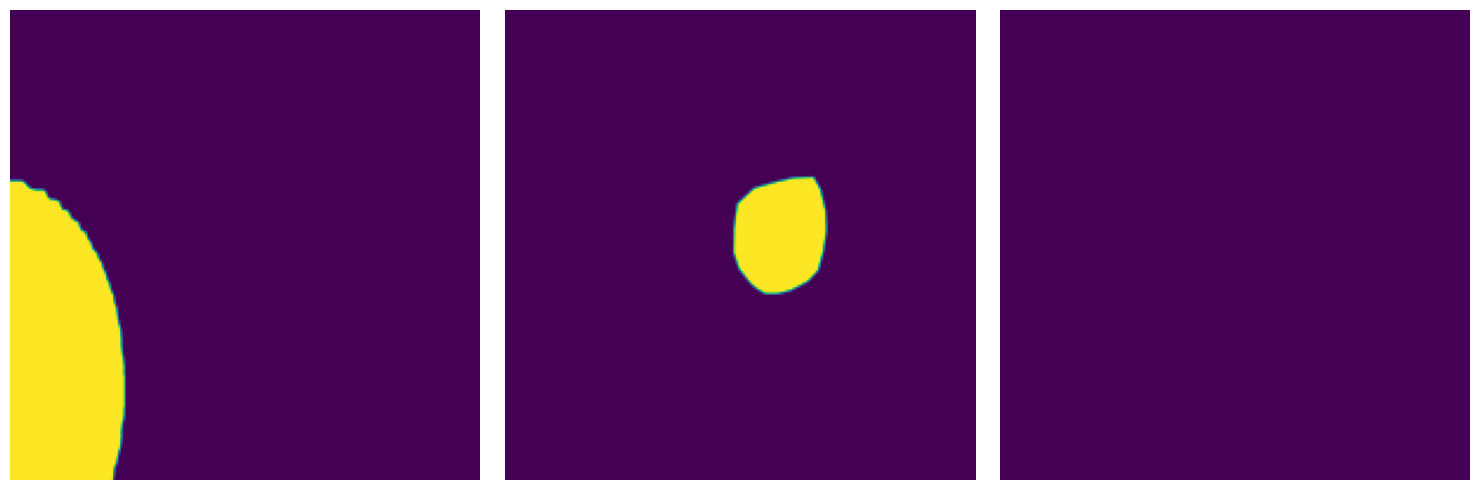

 44%|████▍     | 4072/9210 [00:41<00:13, 383.28it/s]

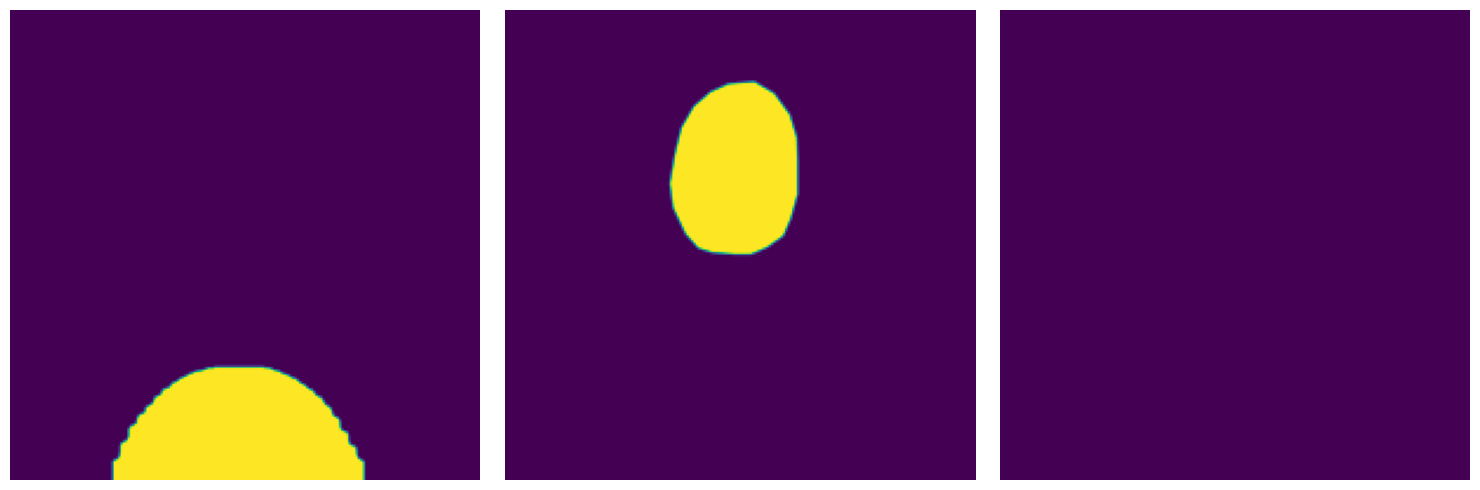

 47%|████▋     | 4312/9210 [00:41<00:12, 376.95it/s]

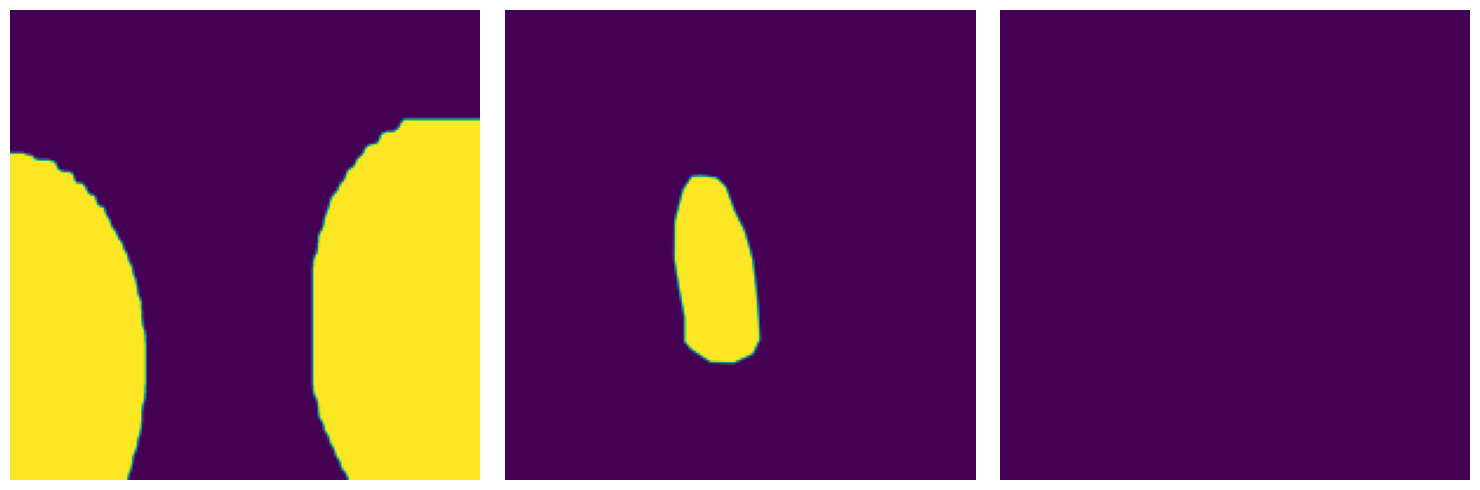

 47%|████▋     | 4357/9210 [00:42<00:27, 178.17it/s]

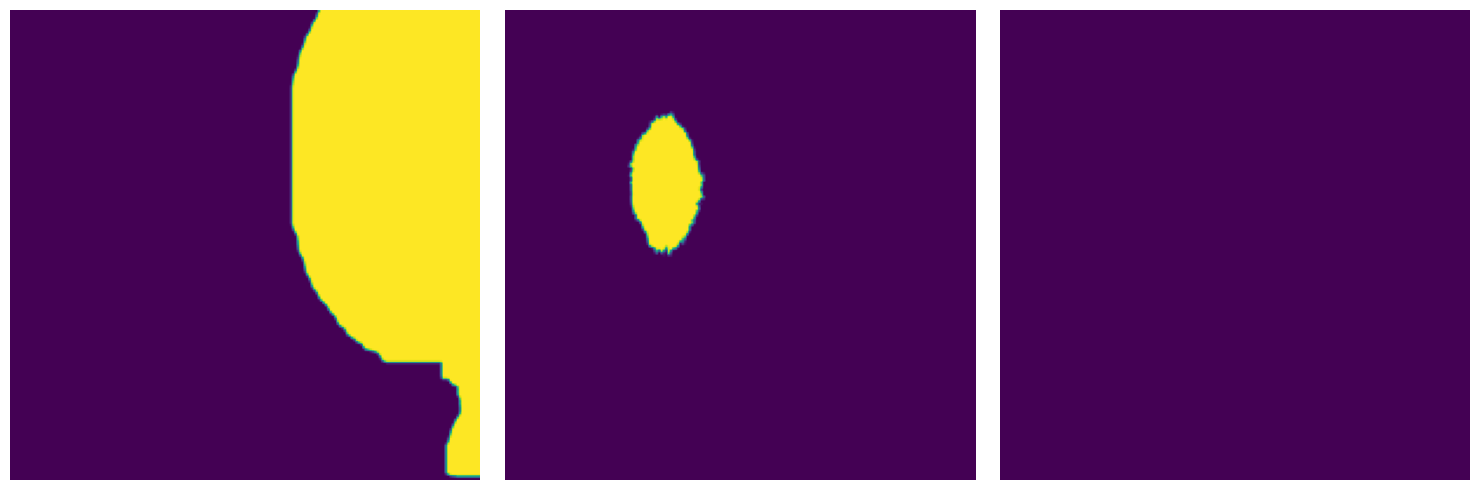

 49%|████▉     | 4539/9210 [00:43<00:18, 252.34it/s]

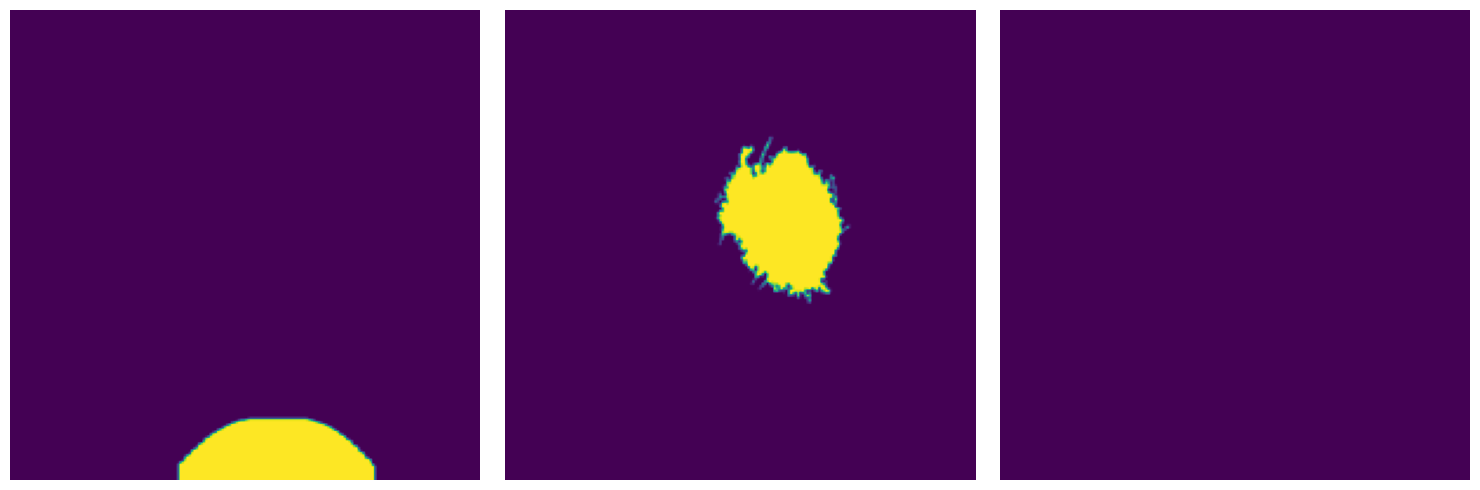

 50%|████▉     | 4580/9210 [00:43<00:25, 182.04it/s]

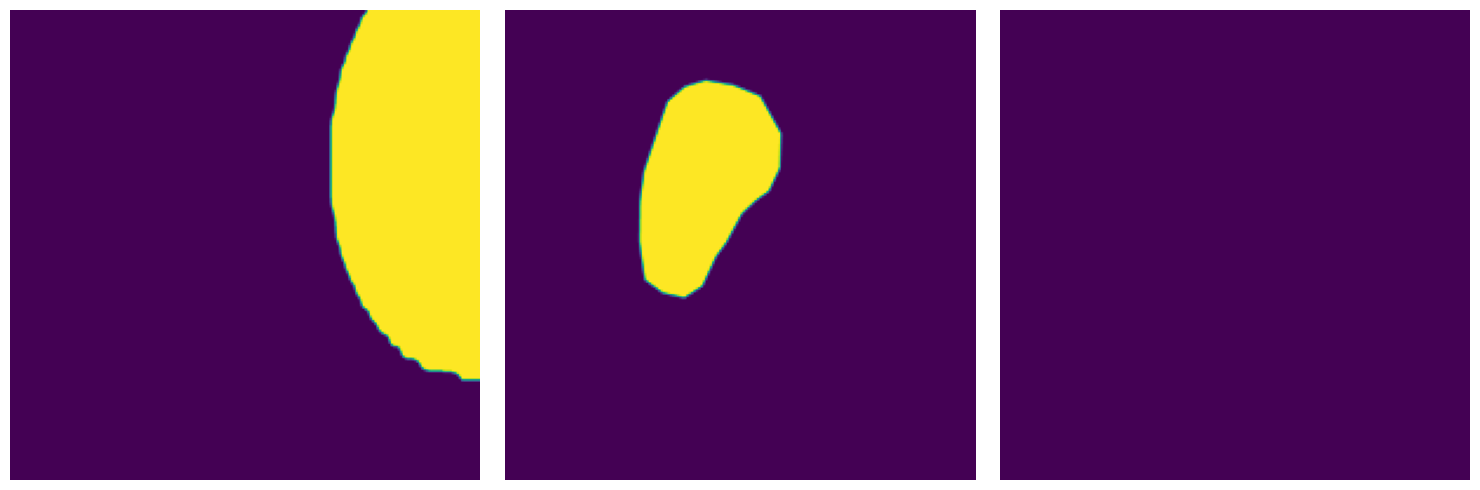

 53%|█████▎    | 4905/9210 [00:44<00:11, 387.45it/s]

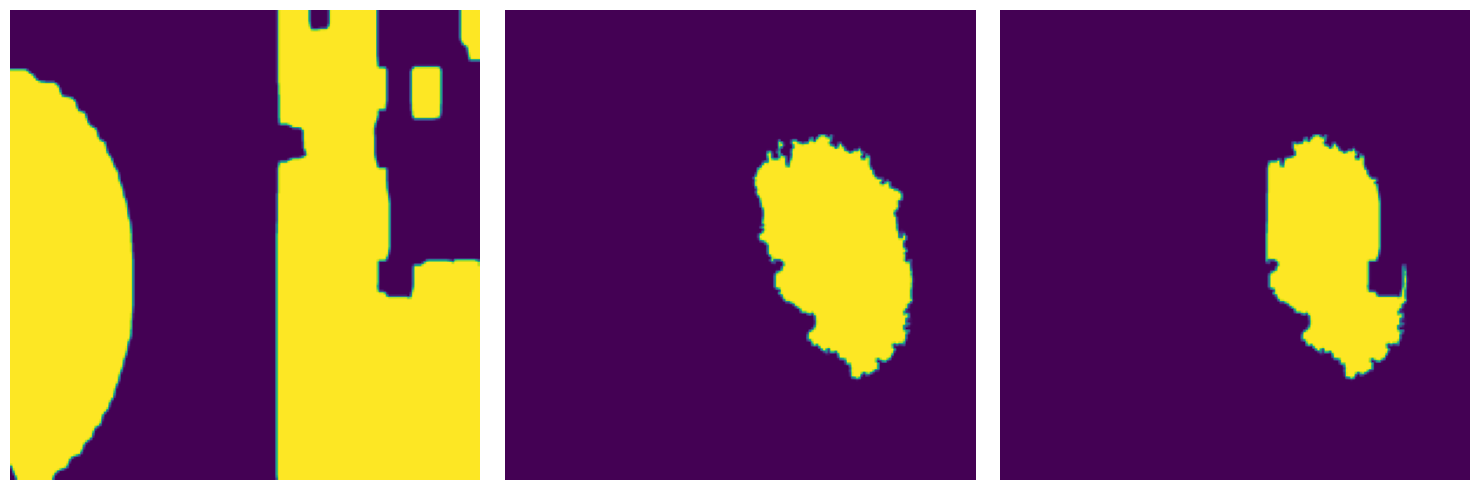

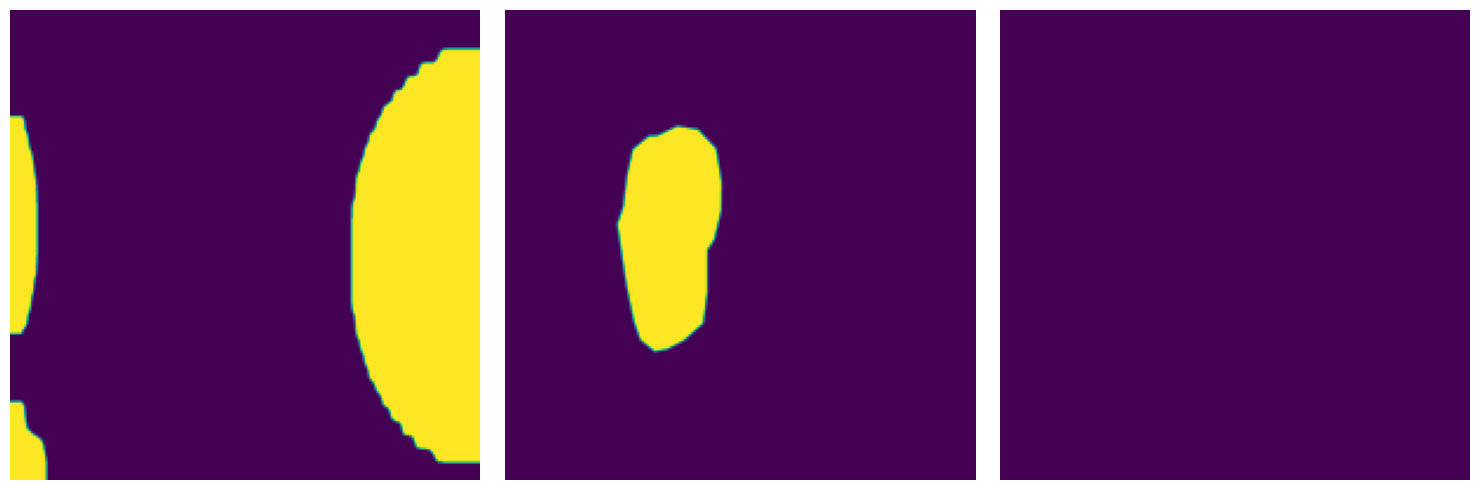

 54%|█████▍    | 4951/9210 [00:45<00:27, 154.46it/s]

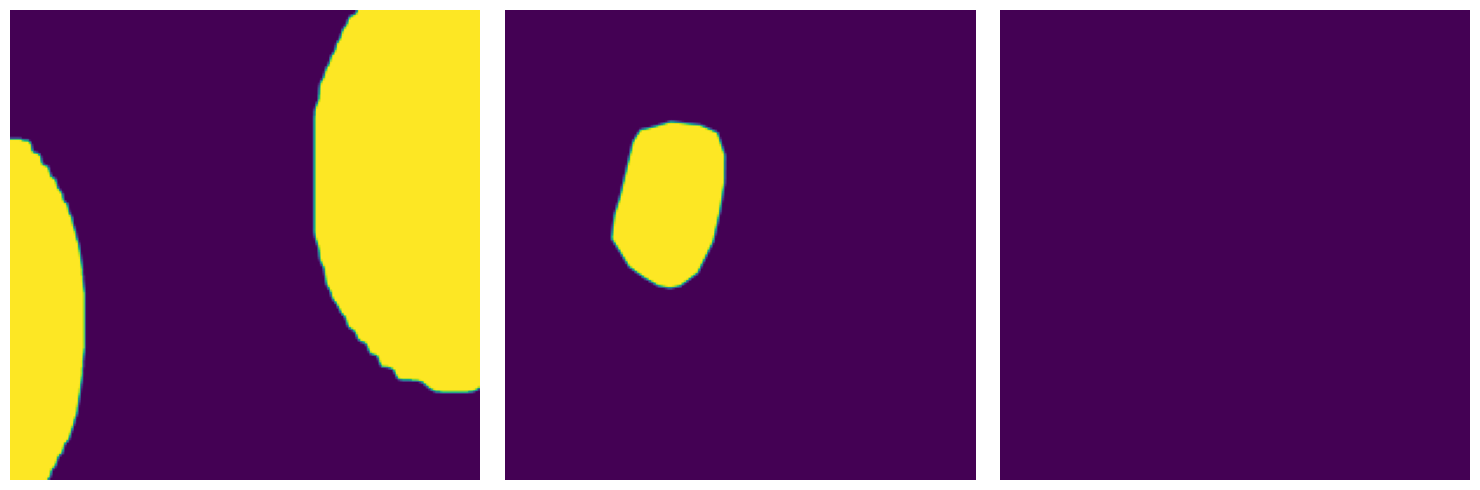

 54%|█████▍    | 4985/9210 [00:45<00:32, 130.53it/s]

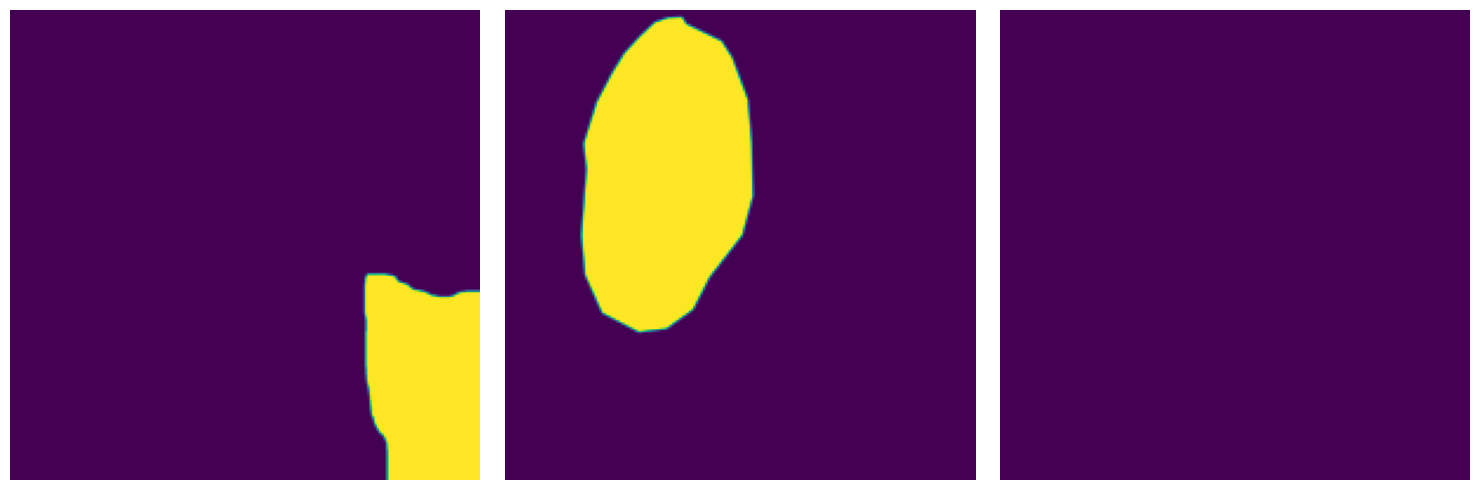

 54%|█████▍    | 5012/9210 [00:46<00:38, 110.18it/s]

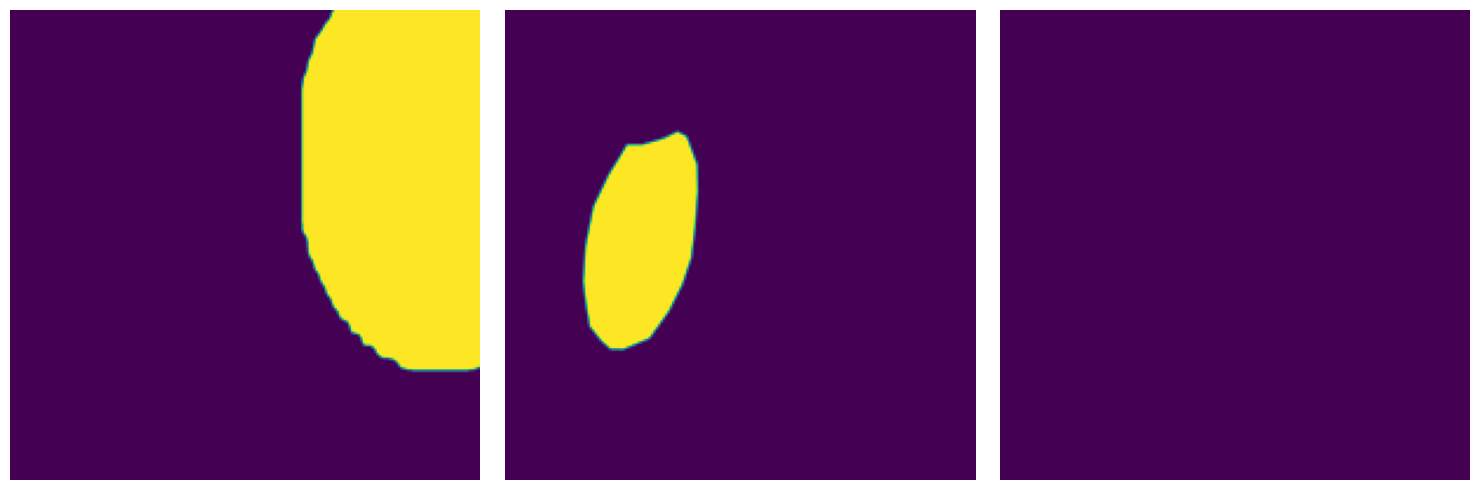

 56%|█████▌    | 5130/9210 [00:46<00:22, 182.80it/s]

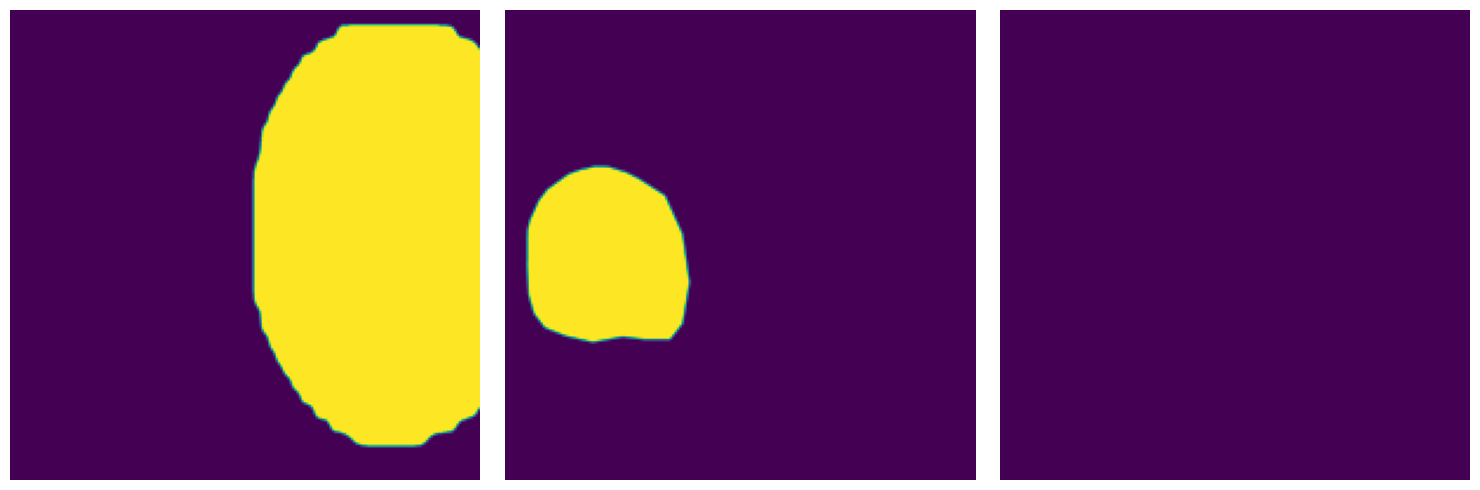

 58%|█████▊    | 5357/9210 [00:47<00:11, 323.96it/s]

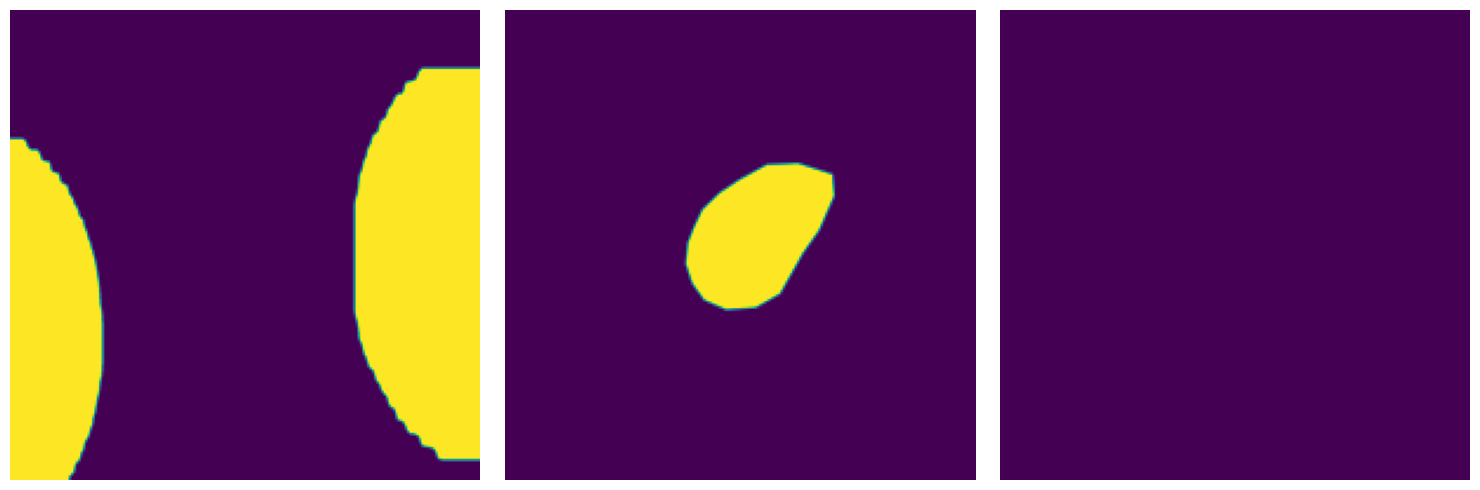

 59%|█████▉    | 5447/9210 [00:48<00:18, 204.93it/s]

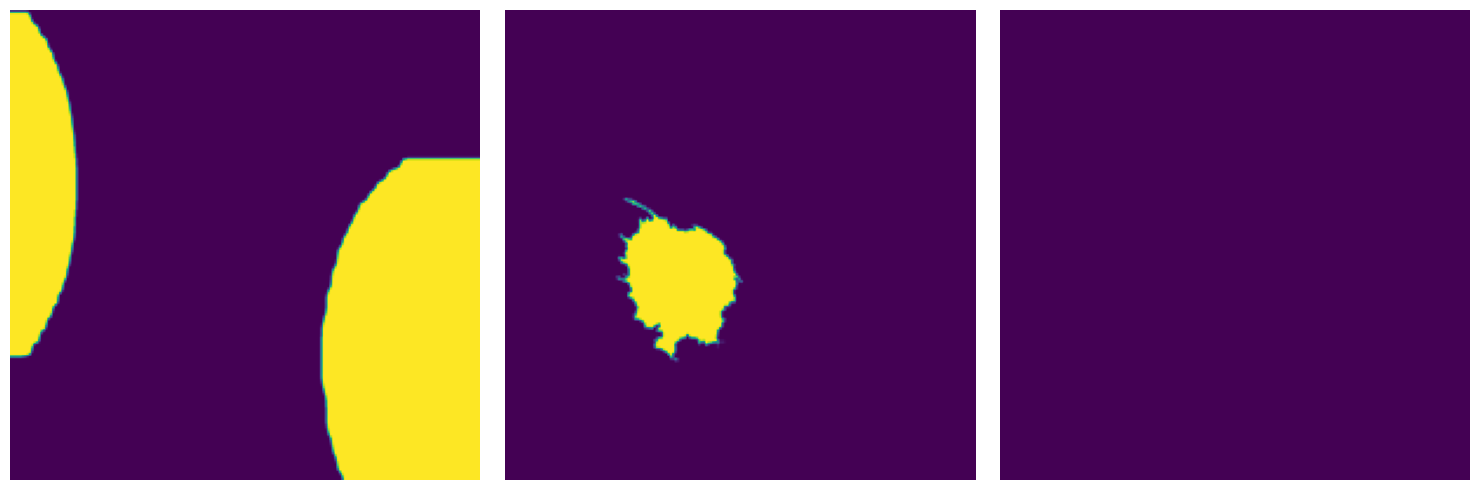

 60%|██████    | 5531/9210 [00:48<00:18, 197.10it/s]

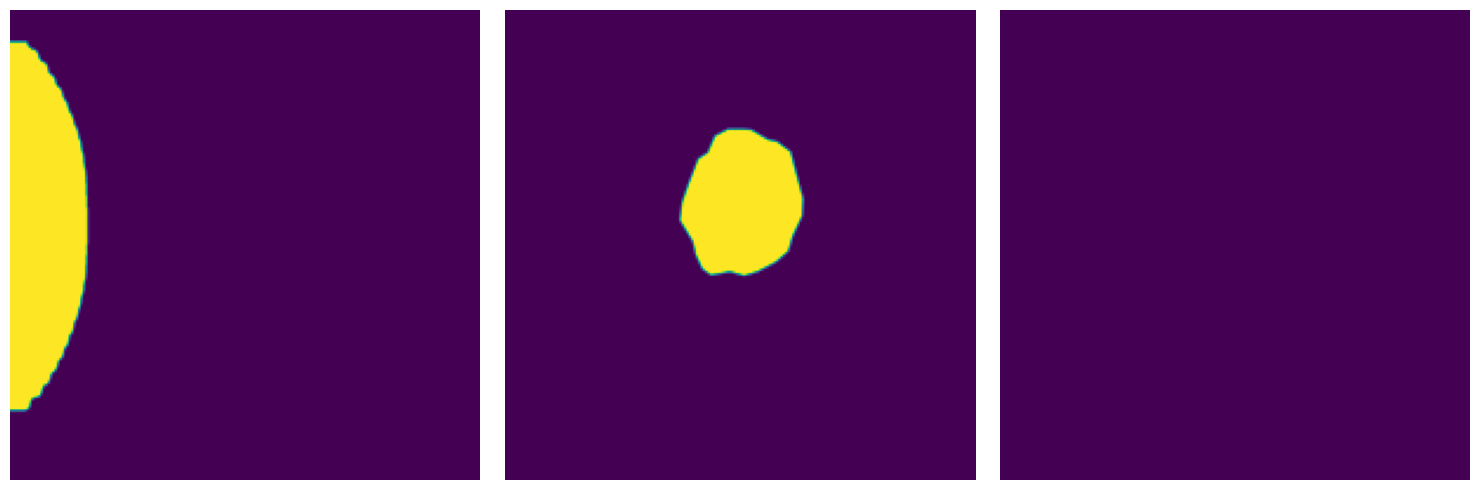

 61%|██████▏   | 5664/9210 [00:49<00:14, 244.34it/s]

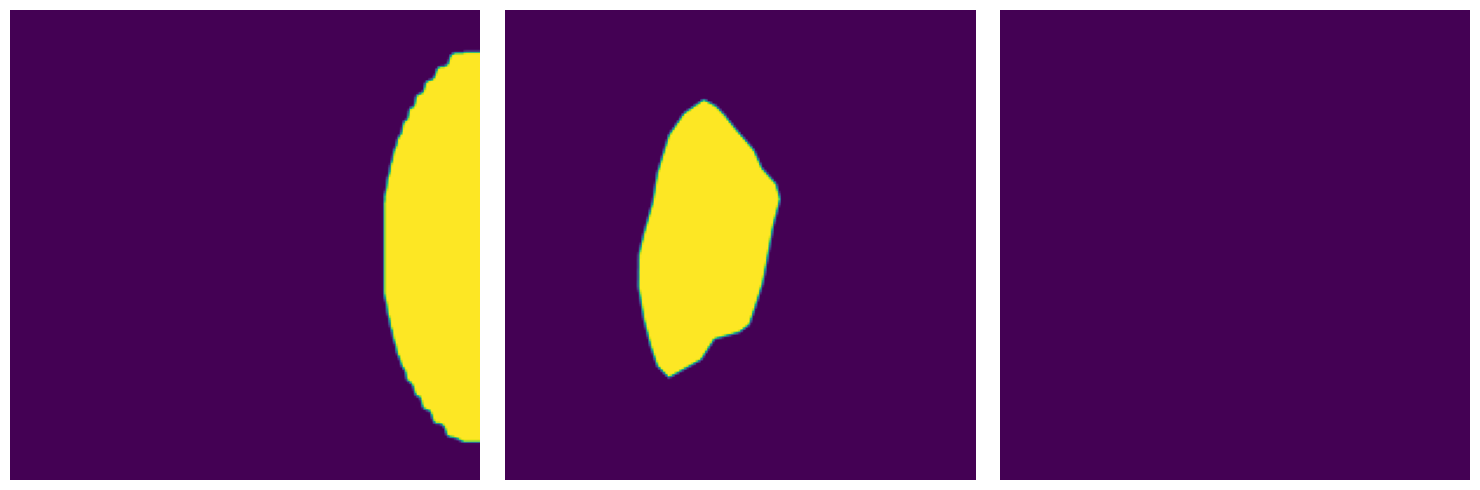

 65%|██████▍   | 5953/9210 [00:50<00:08, 380.62it/s]

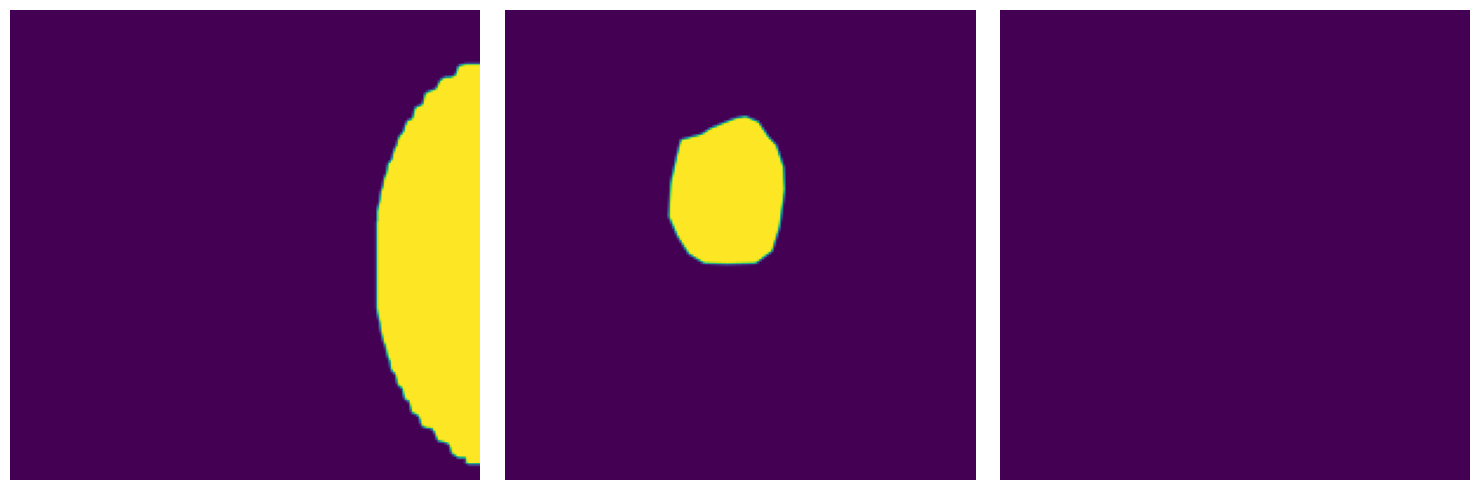

 65%|██████▌   | 5999/9210 [00:50<00:17, 179.93it/s]

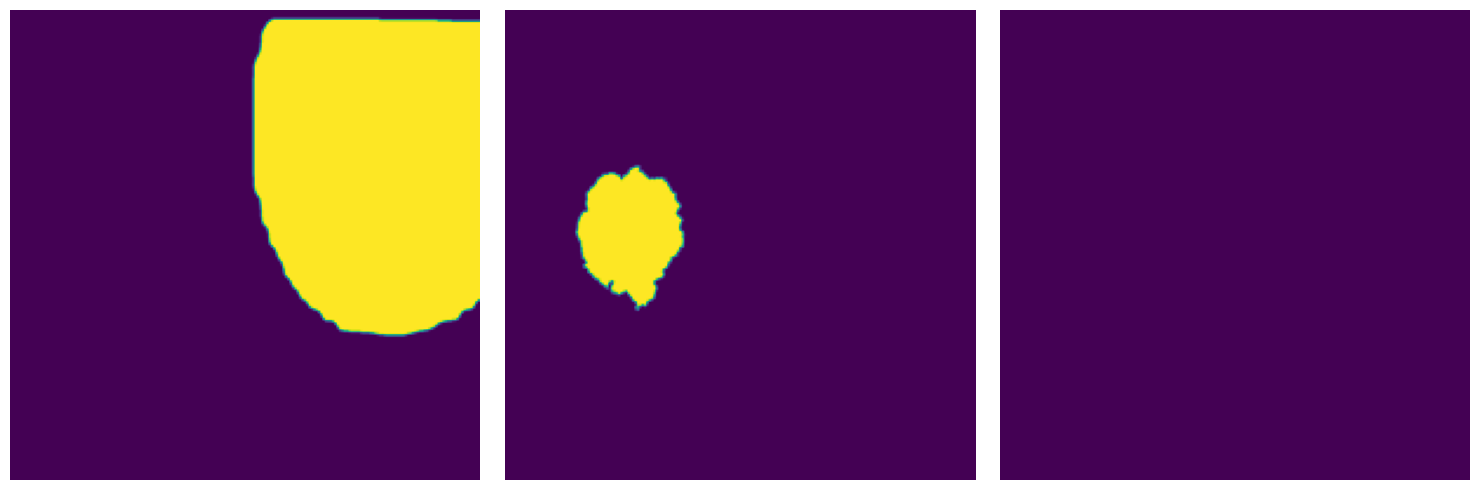

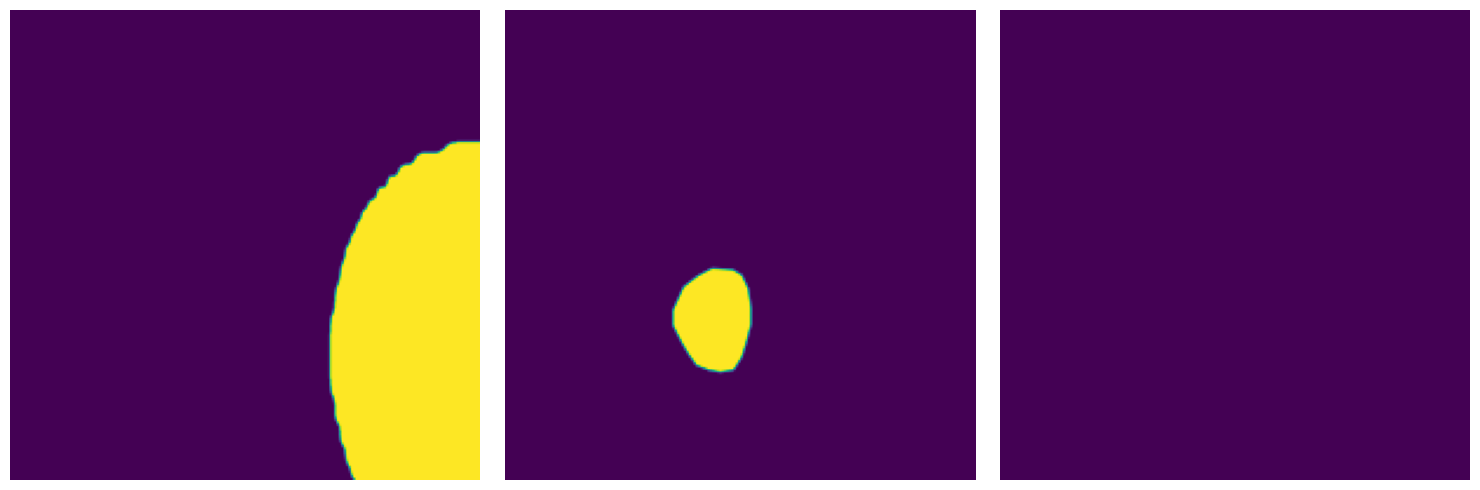

 66%|██████▌   | 6034/9210 [00:51<00:28, 110.65it/s]

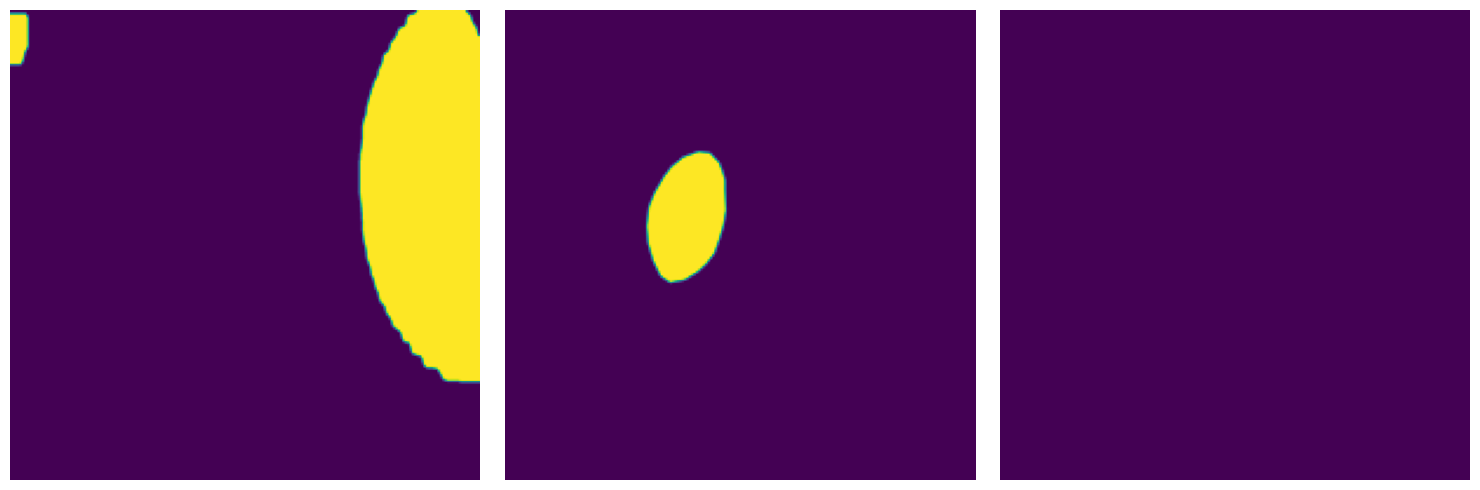

 66%|██████▋   | 6114/9210 [00:52<00:24, 124.17it/s]

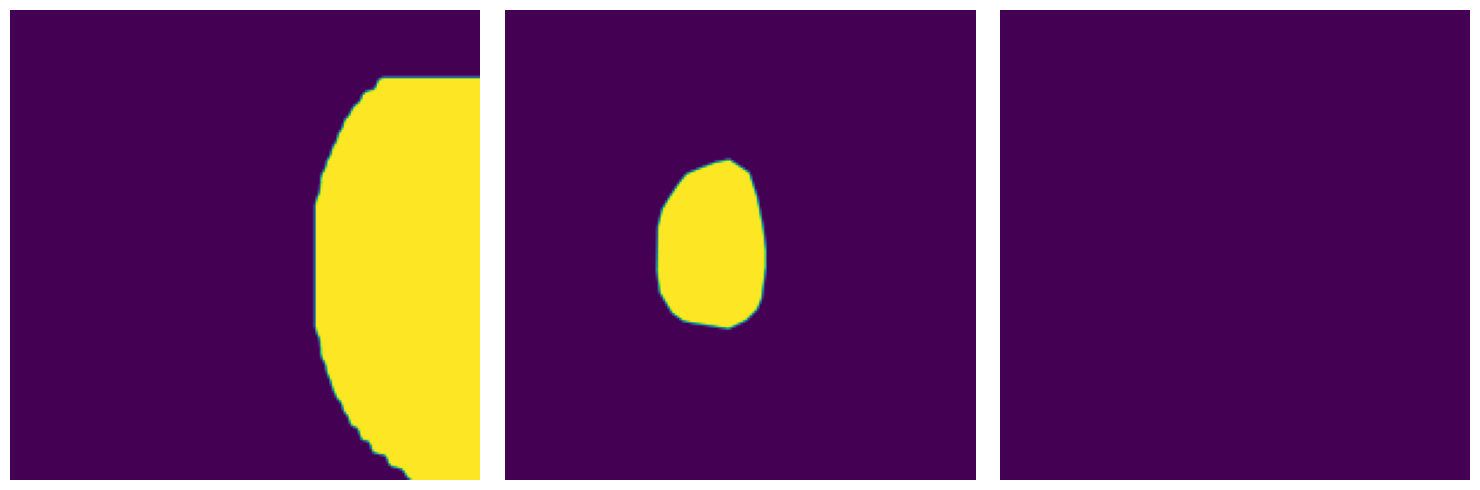

 67%|██████▋   | 6142/9210 [00:52<00:28, 108.03it/s]

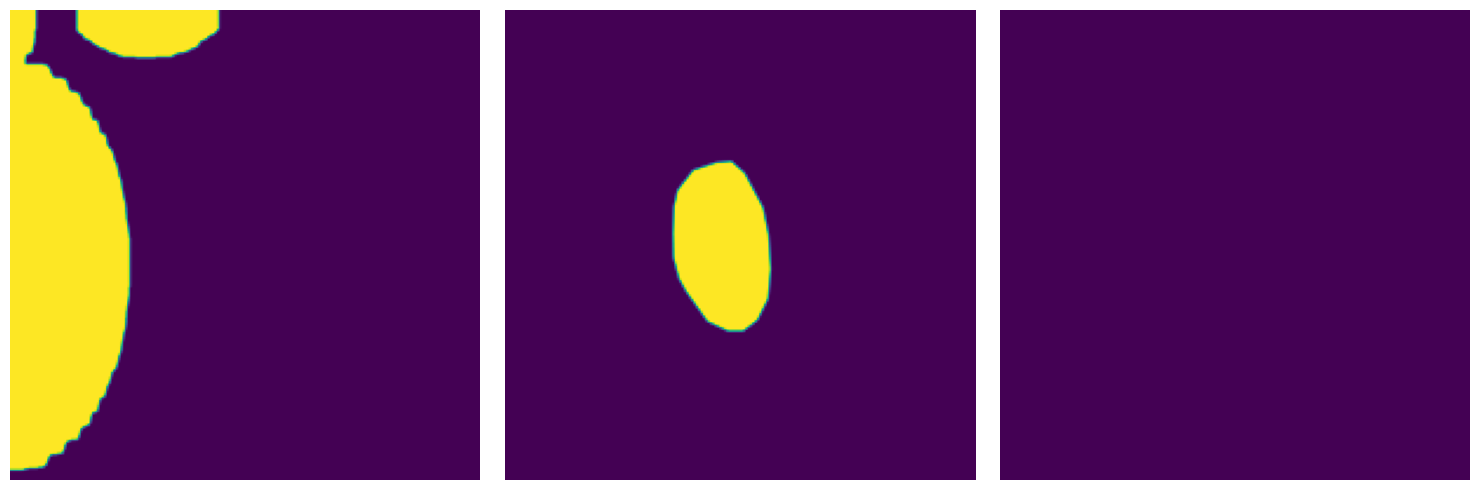

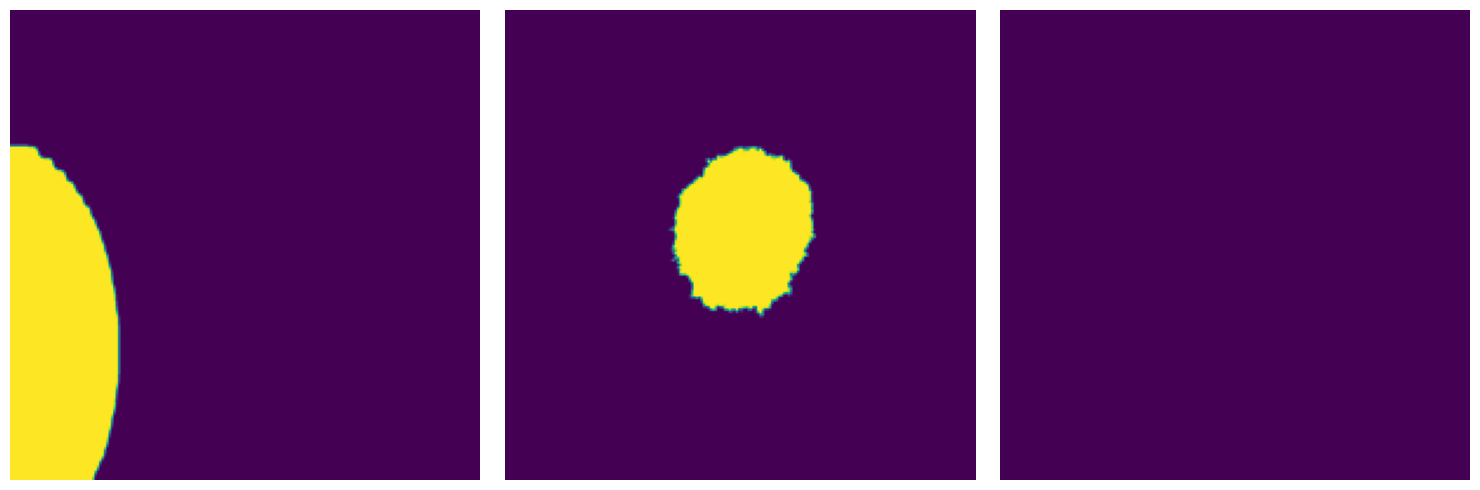

 67%|██████▋   | 6164/9210 [00:53<00:45, 66.32it/s] 

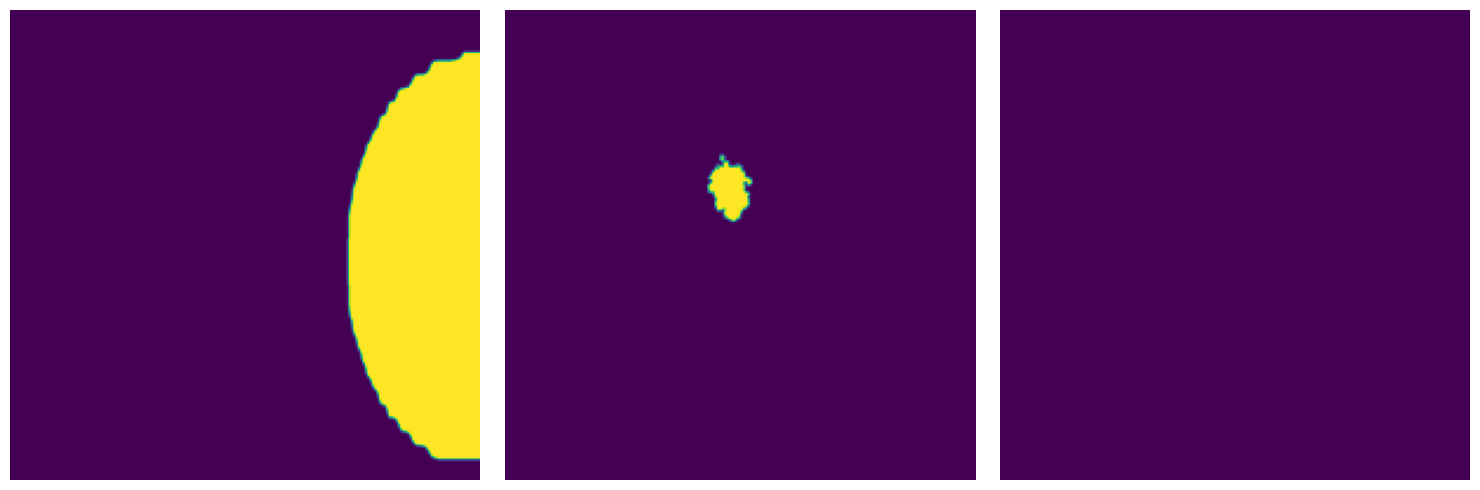

 68%|██████▊   | 6229/9210 [00:54<00:33, 89.49it/s]

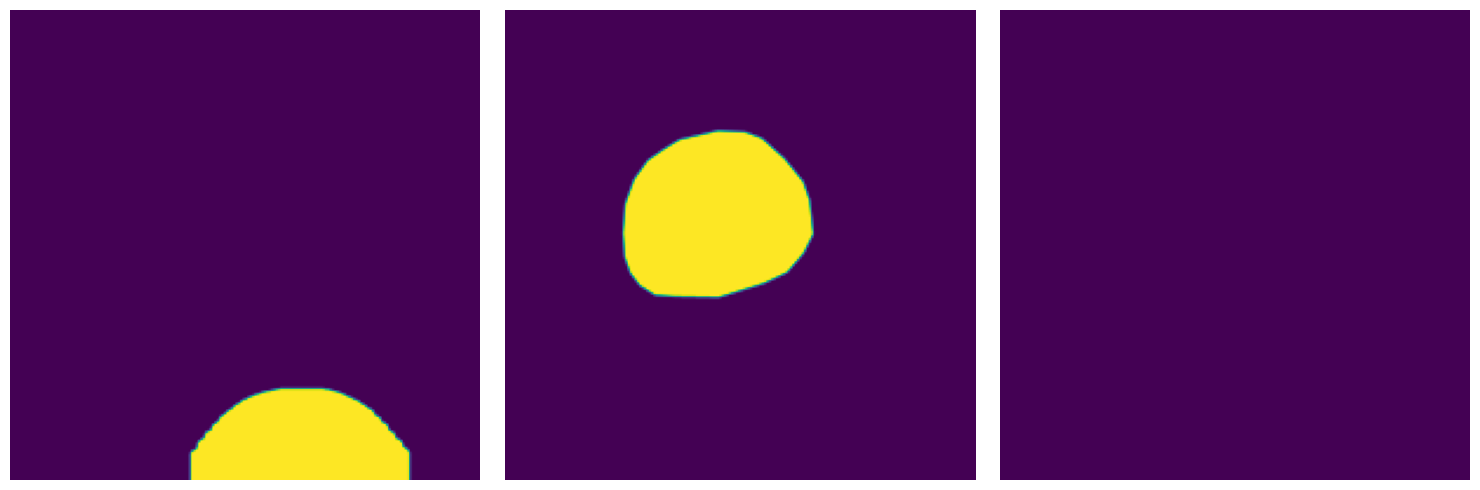

 68%|██████▊   | 6269/9210 [00:54<00:31, 92.85it/s]

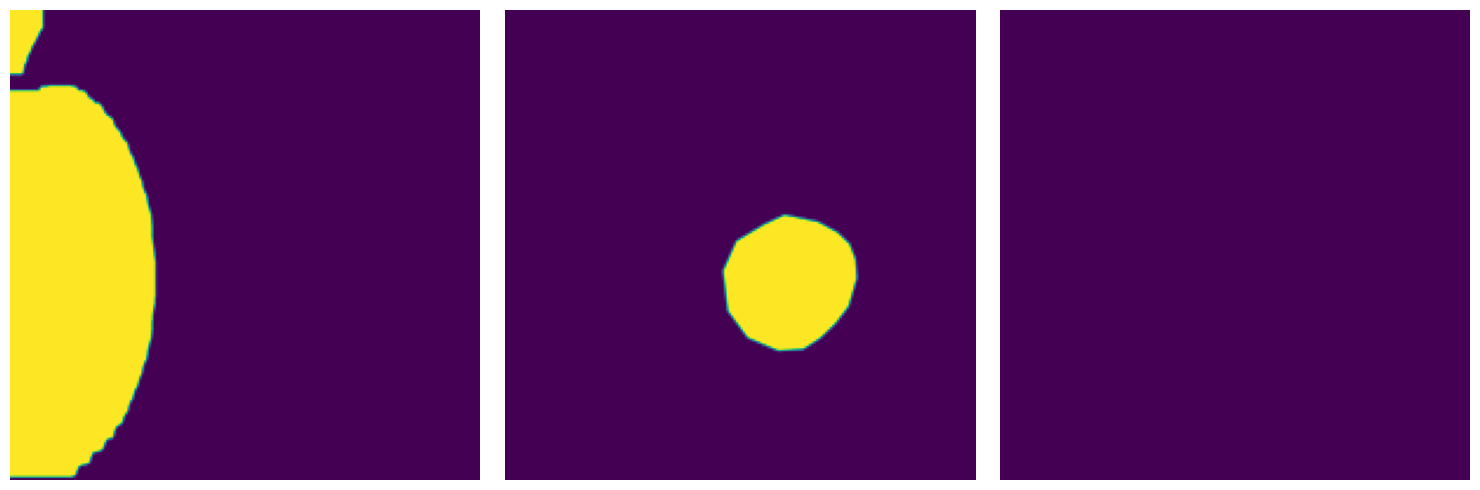

 68%|██████▊   | 6295/9210 [00:55<00:38, 75.33it/s]

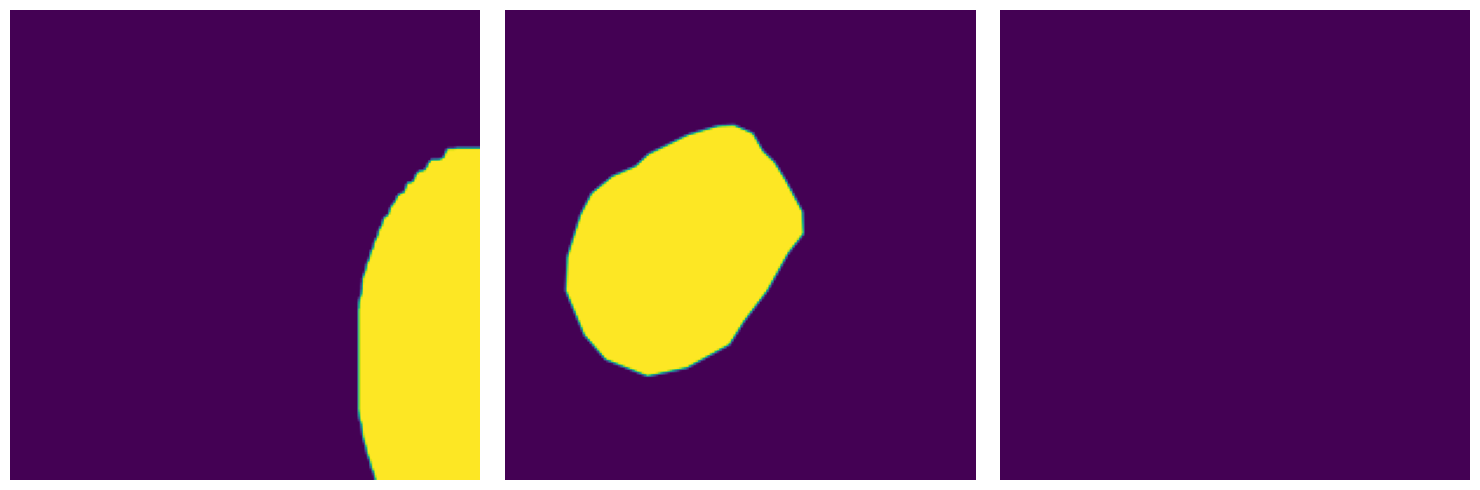

 69%|██████▉   | 6387/9210 [00:56<00:34, 82.44it/s]

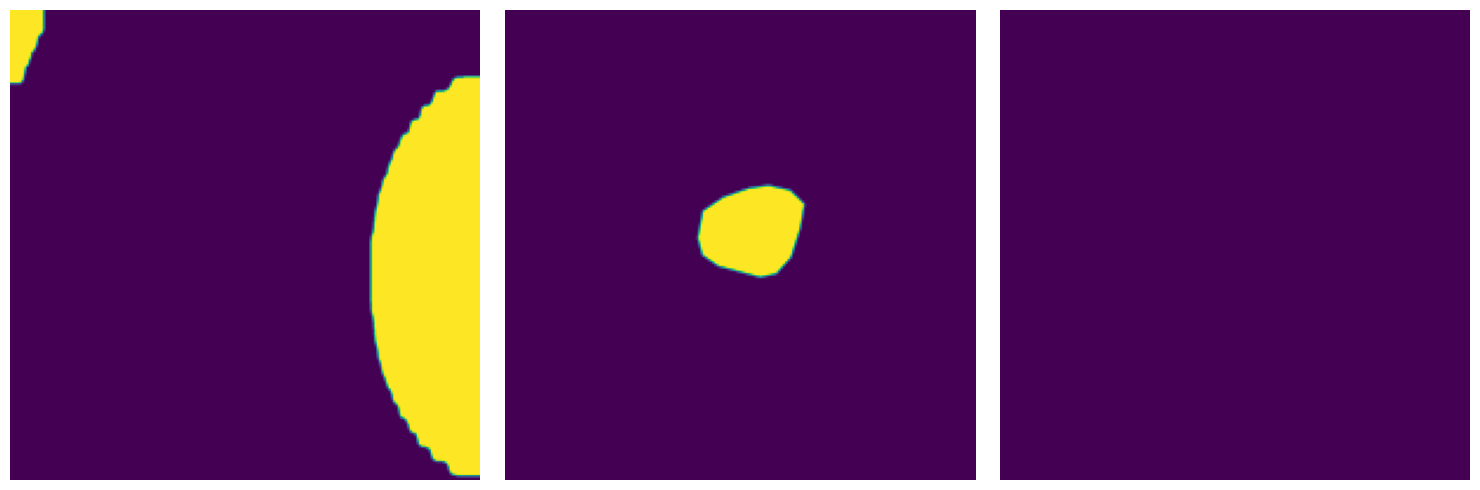

 70%|██████▉   | 6410/9210 [00:56<00:40, 69.73it/s]

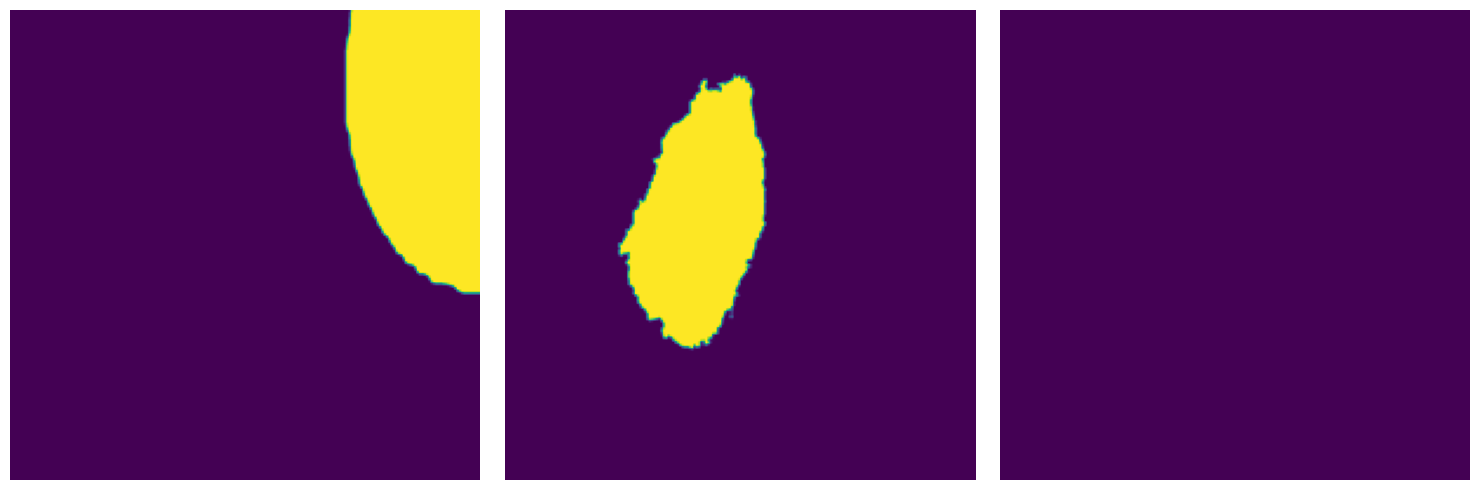

 70%|███████   | 6489/9210 [00:57<00:25, 105.85it/s]

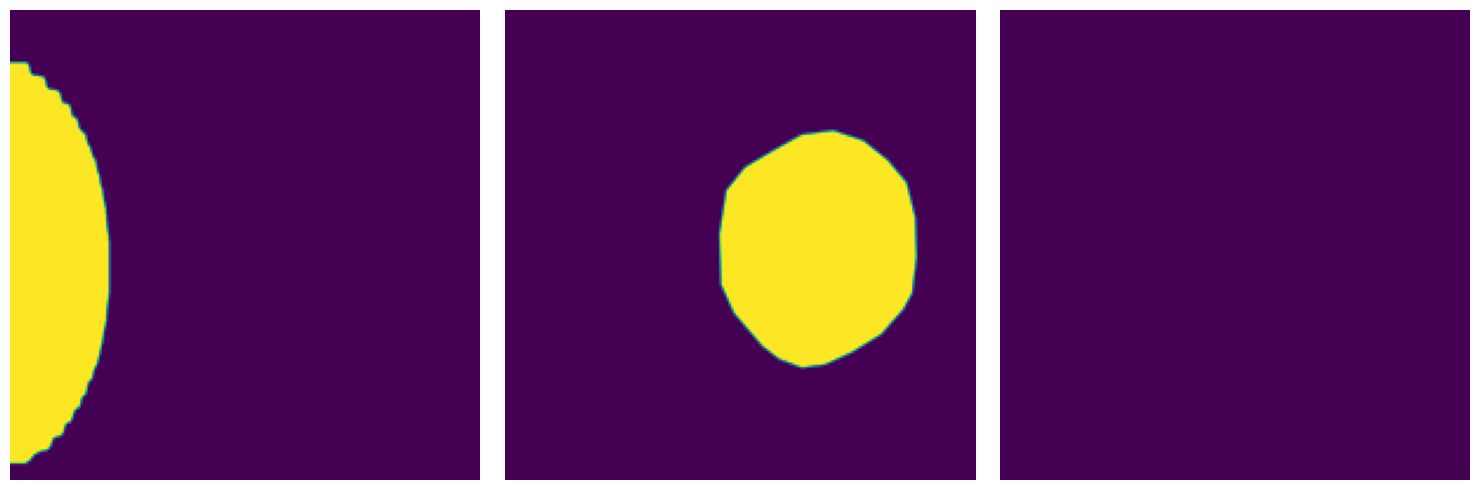

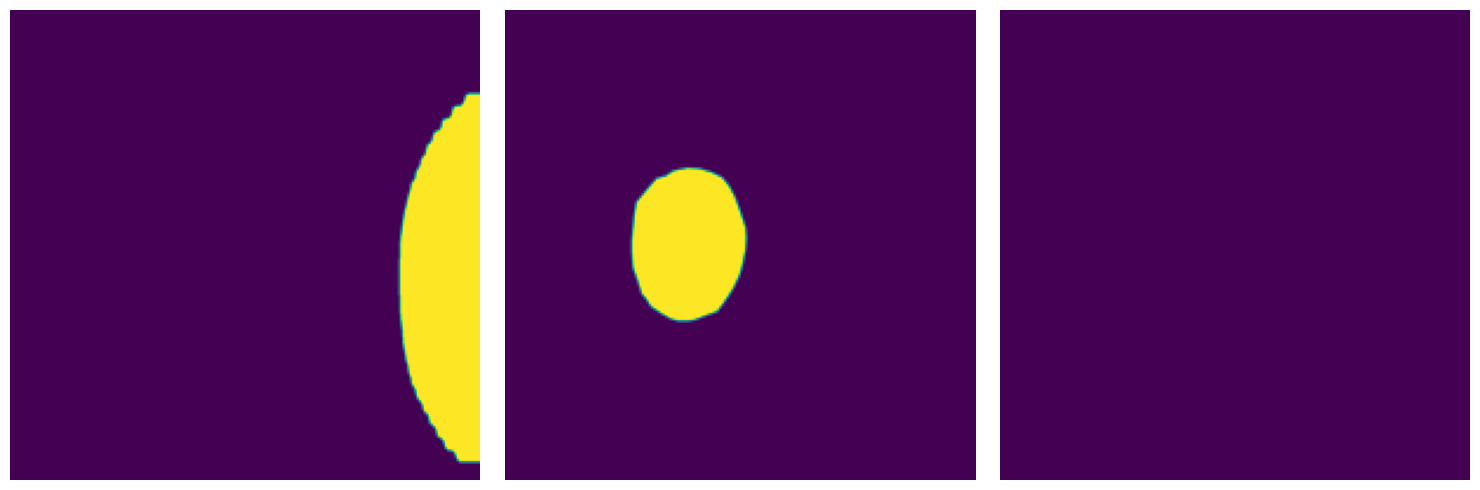

 71%|███████▏  | 6563/9210 [00:58<00:24, 109.88it/s]

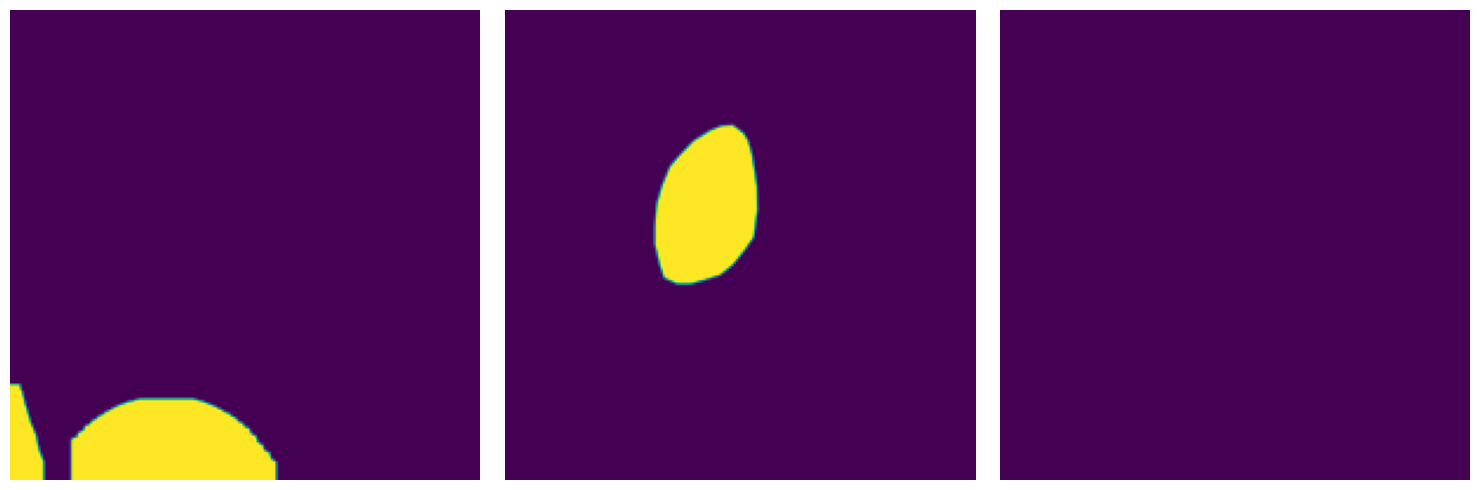

 72%|███████▏  | 6644/9210 [00:58<00:17, 143.03it/s]

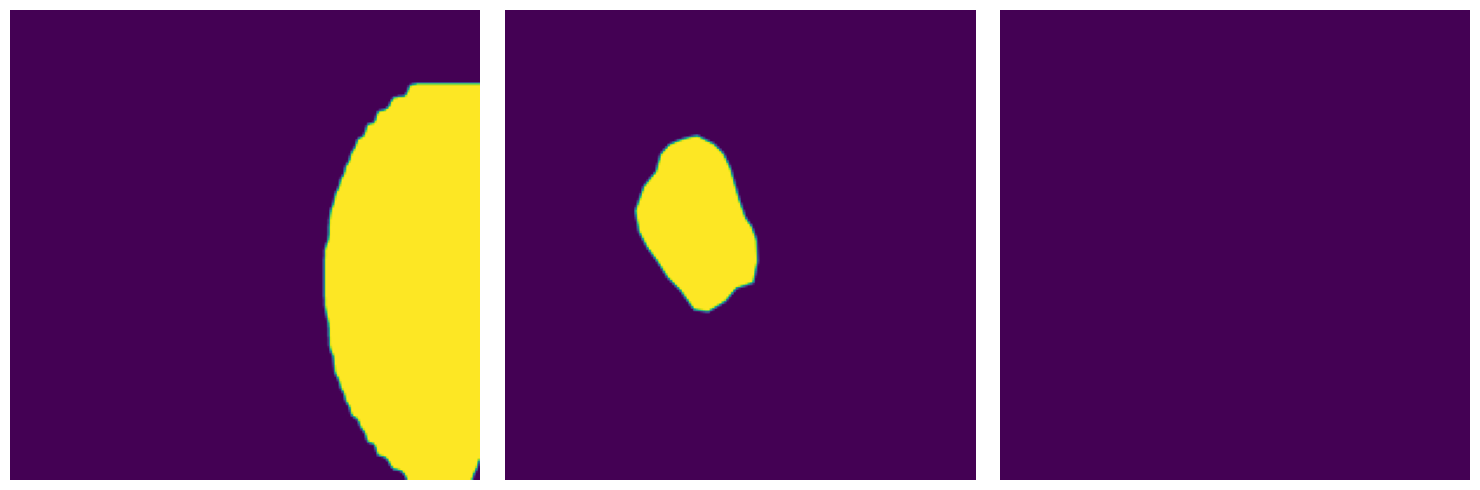

 72%|███████▏  | 6675/9210 [00:59<00:24, 104.68it/s]

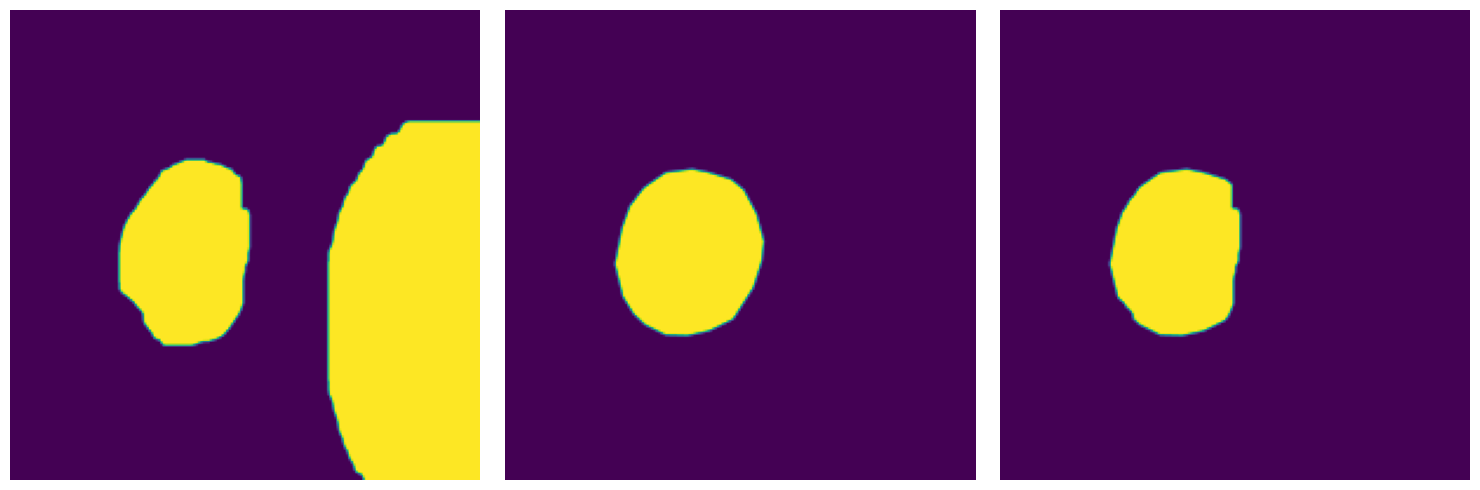

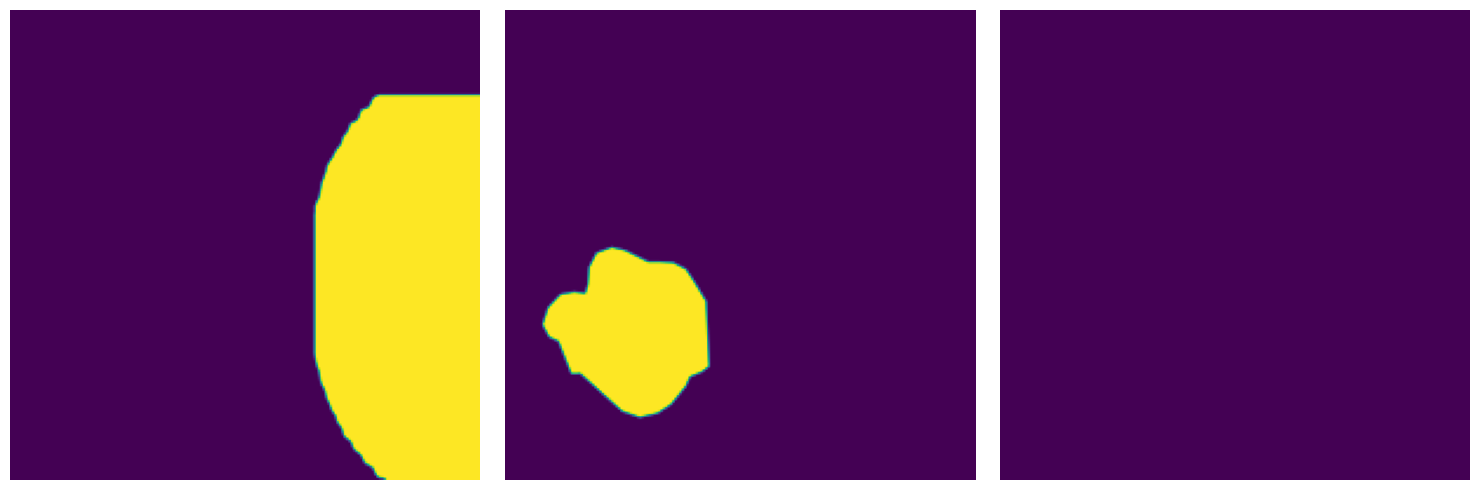

 74%|███████▍  | 6798/9210 [01:00<00:15, 152.90it/s]

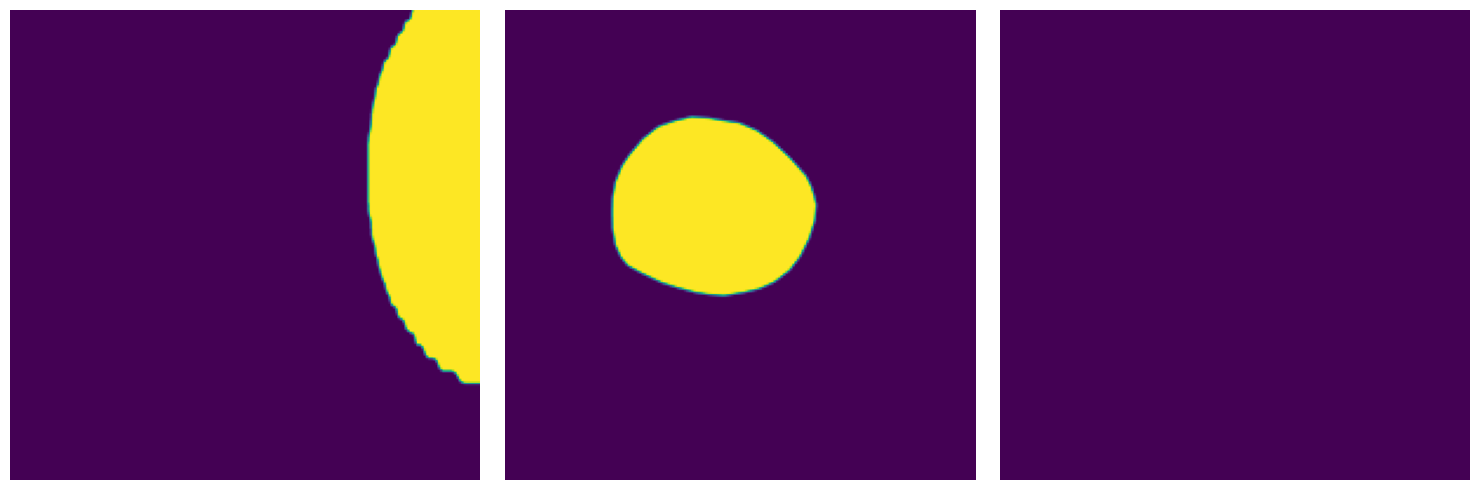

 74%|███████▍  | 6832/9210 [01:00<00:18, 128.96it/s]

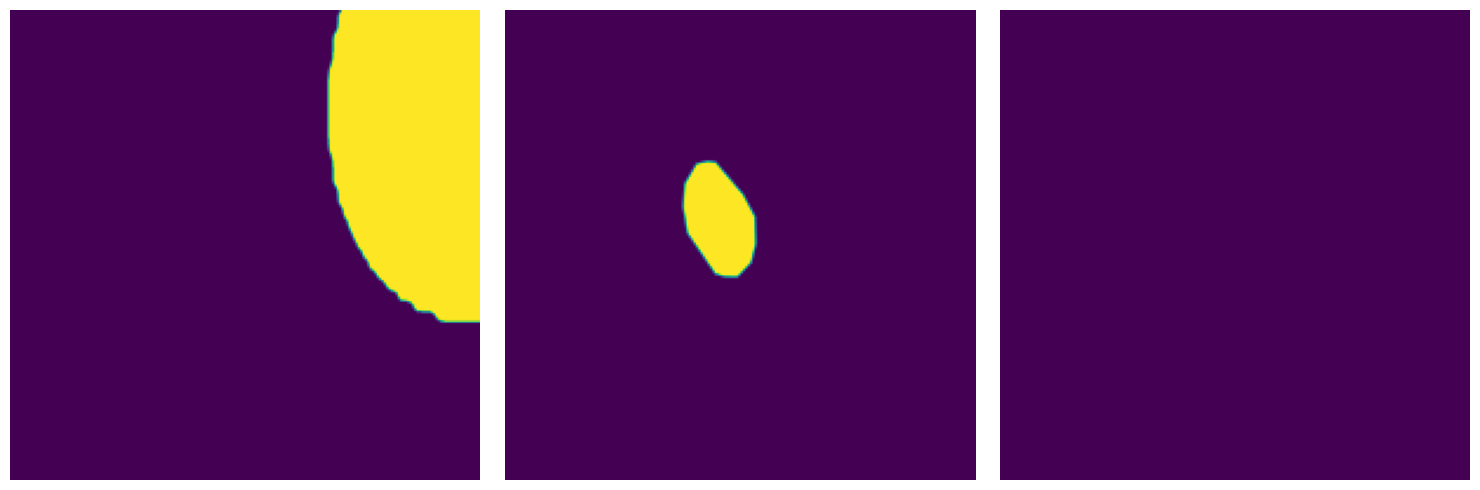

 75%|███████▍  | 6881/9210 [01:00<00:18, 126.05it/s]

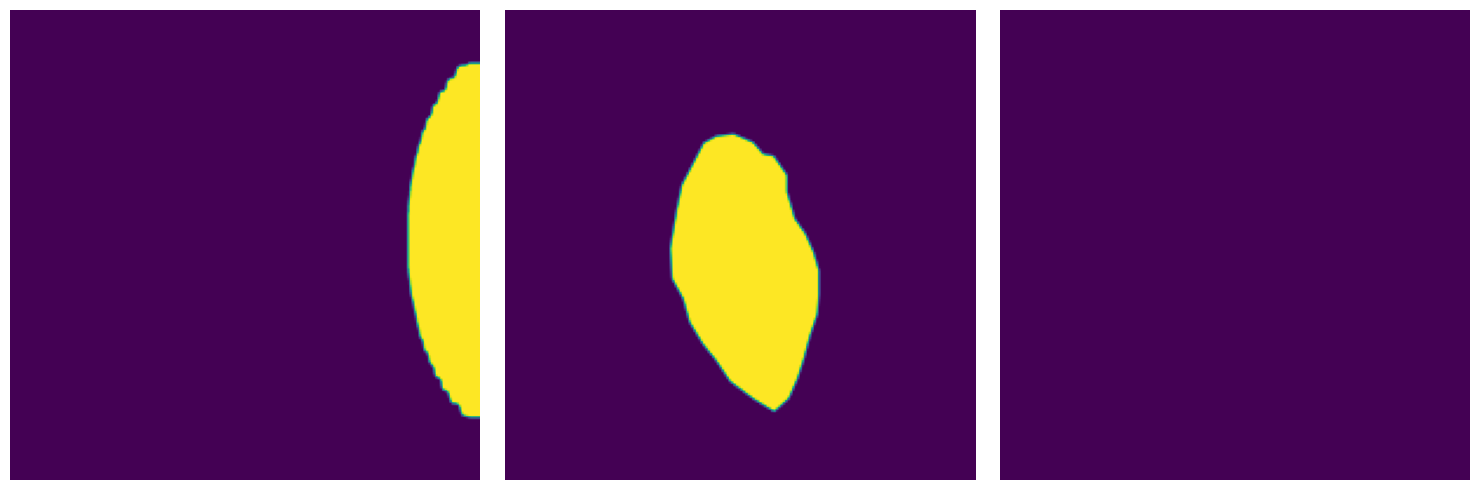

 77%|███████▋  | 7107/9210 [01:01<00:07, 292.46it/s]

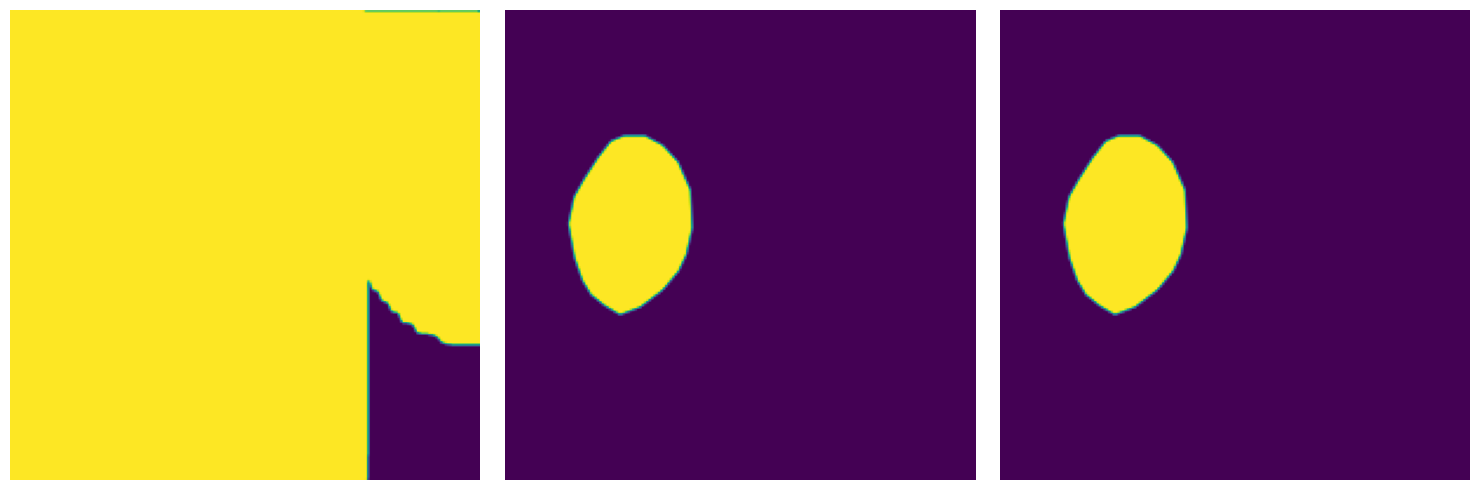

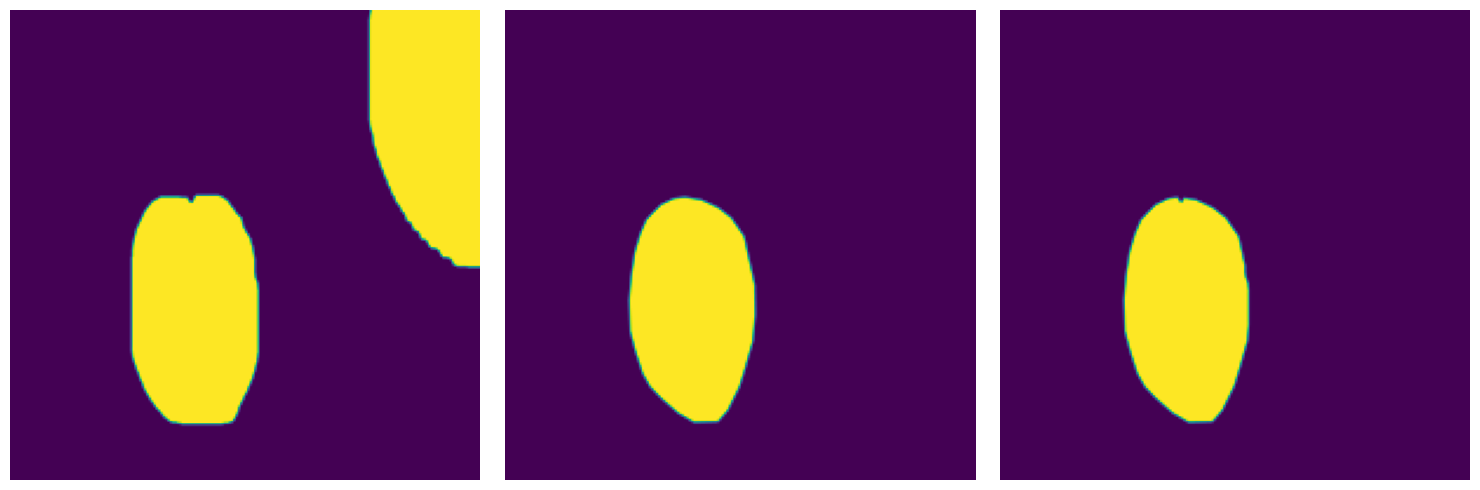

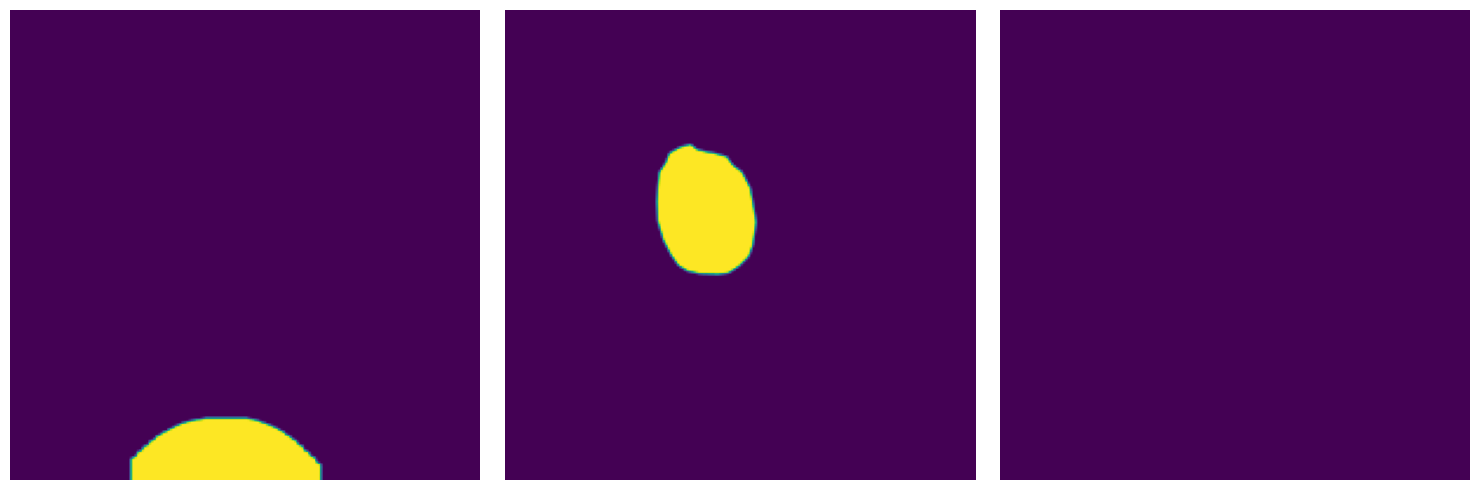

 80%|███████▉  | 7338/9210 [01:03<00:07, 245.70it/s]

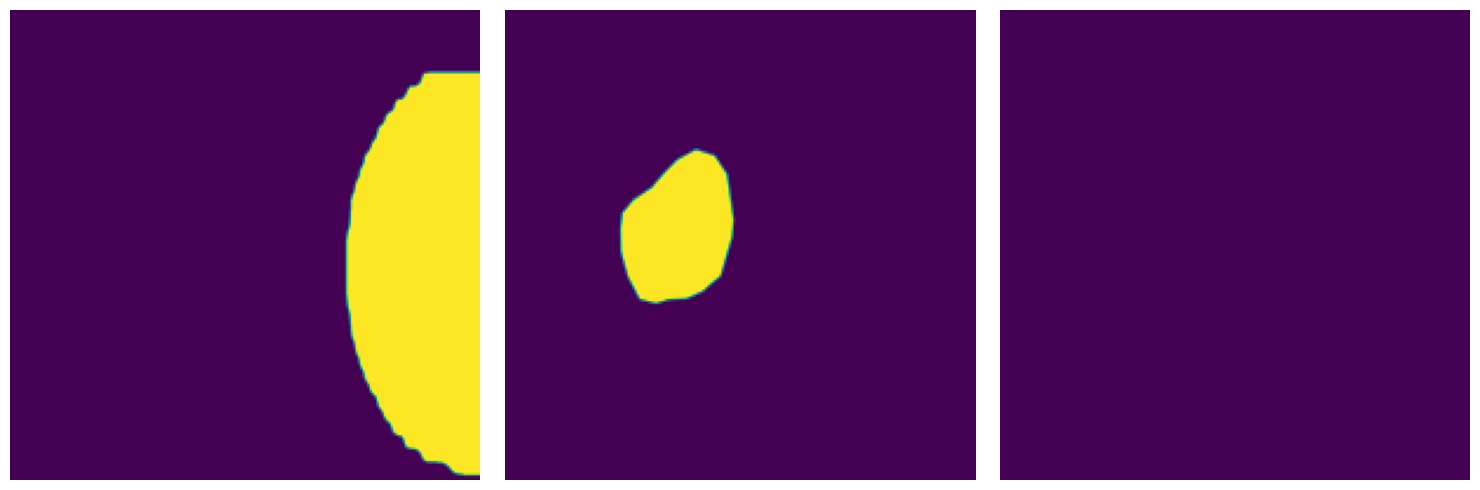

 81%|████████  | 7429/9210 [01:03<00:09, 189.60it/s]

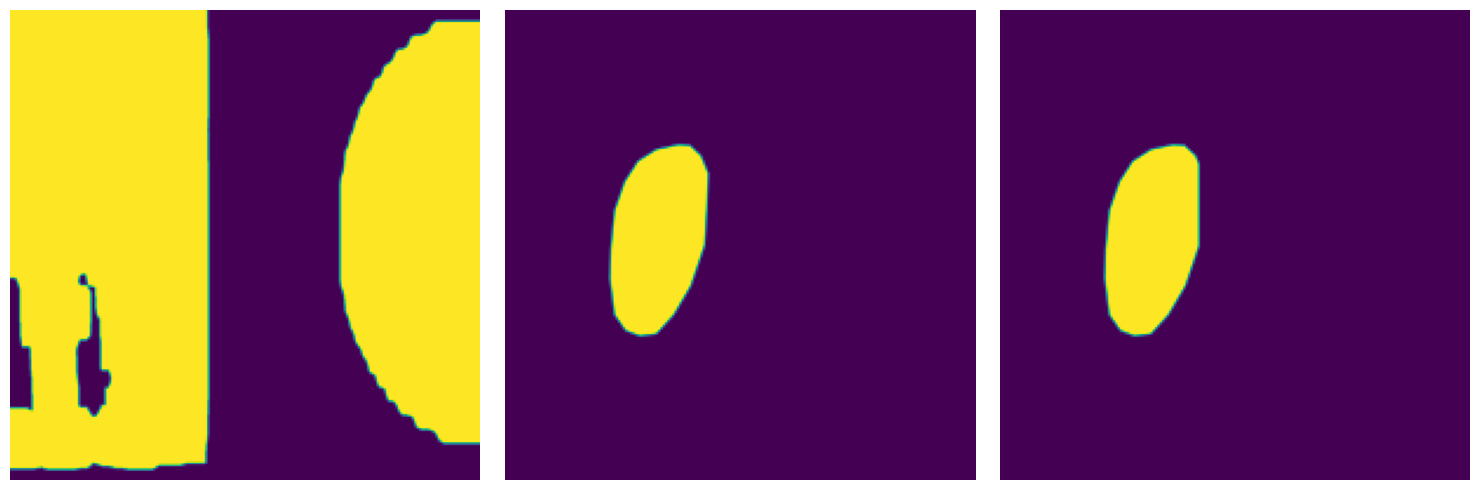

 81%|████████  | 7466/9210 [01:04<00:11, 150.61it/s]

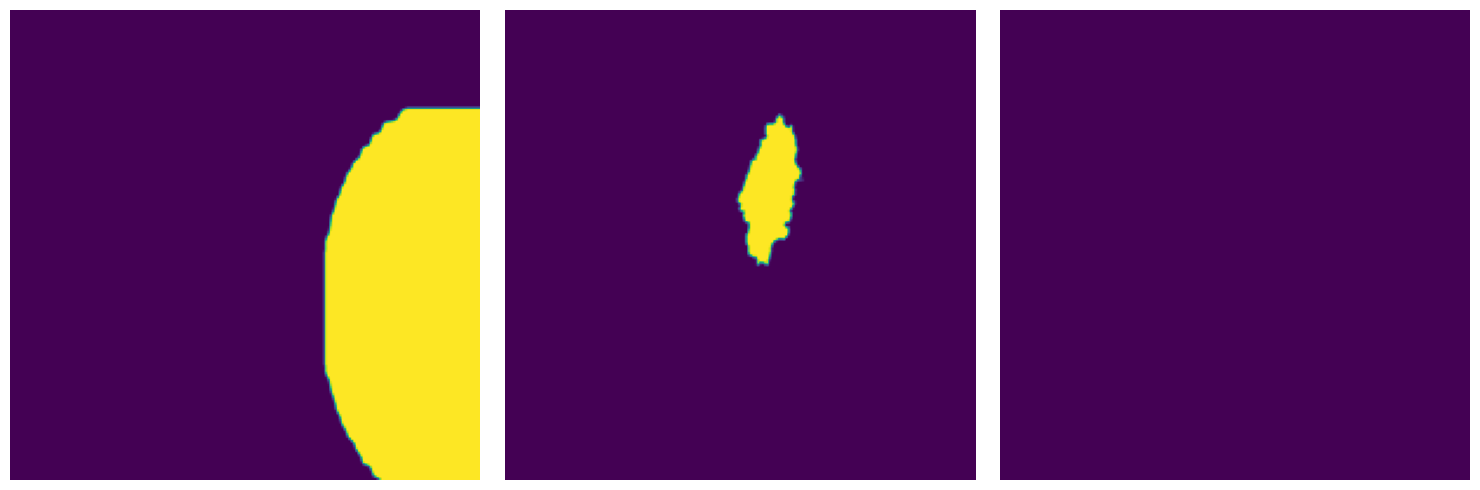

 82%|████████▏ | 7545/9210 [01:04<00:11, 149.57it/s]

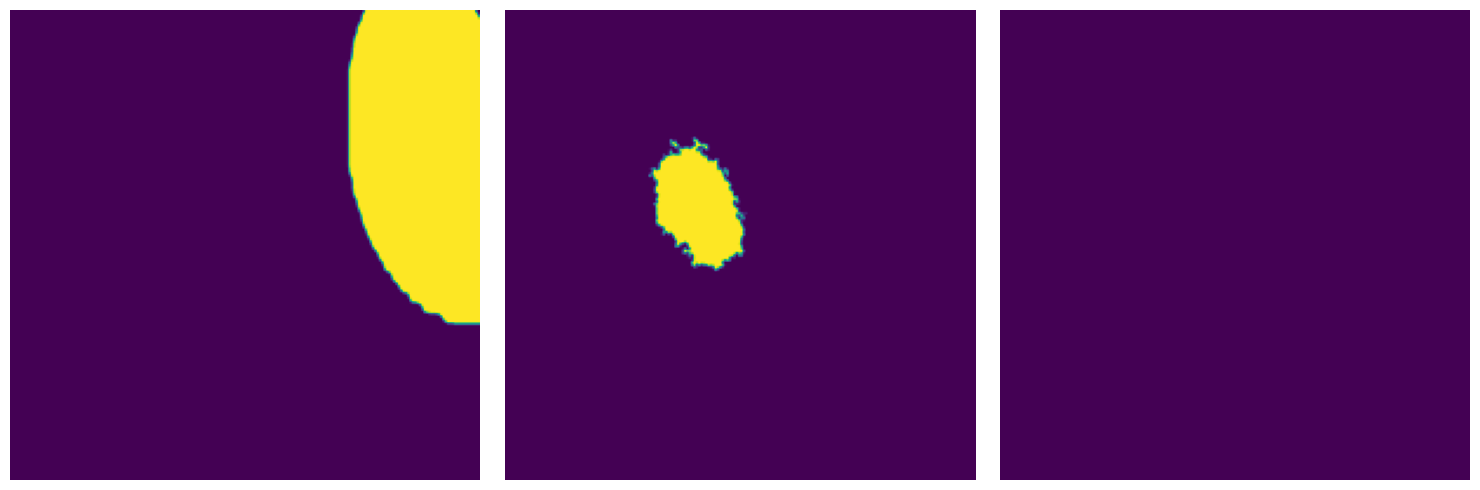

 82%|████████▏ | 7576/9210 [01:05<00:14, 109.37it/s]

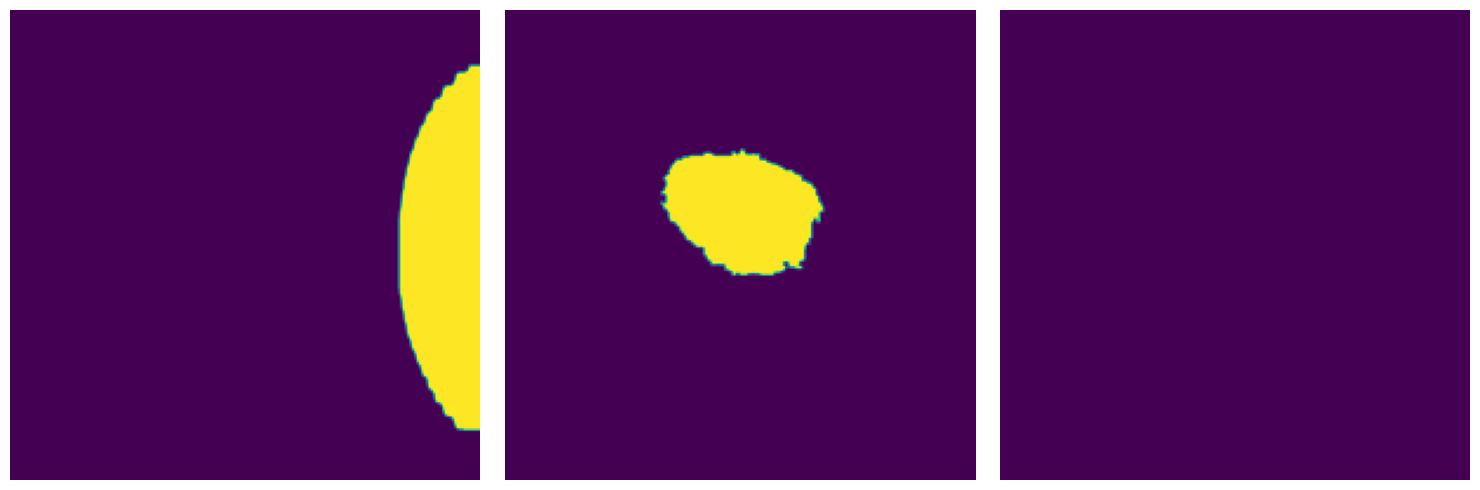

 83%|████████▎ | 7599/9210 [01:05<00:19, 82.86it/s] 

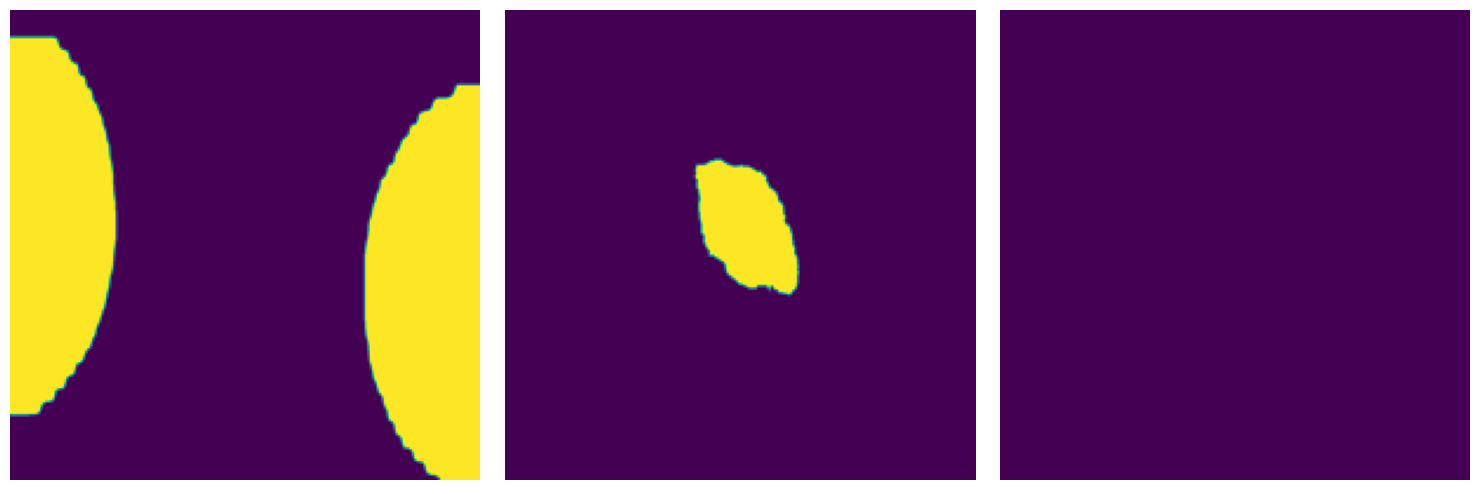

 83%|████████▎ | 7617/9210 [01:06<00:24, 65.84it/s]

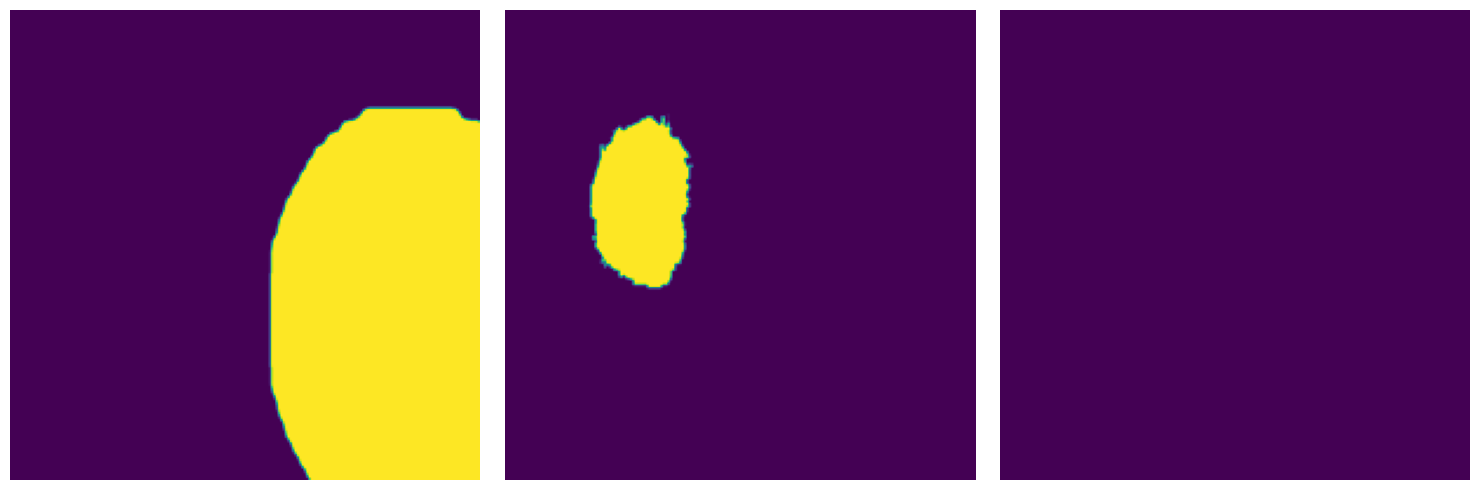

 83%|████████▎ | 7631/9210 [01:06<00:26, 59.80it/s]

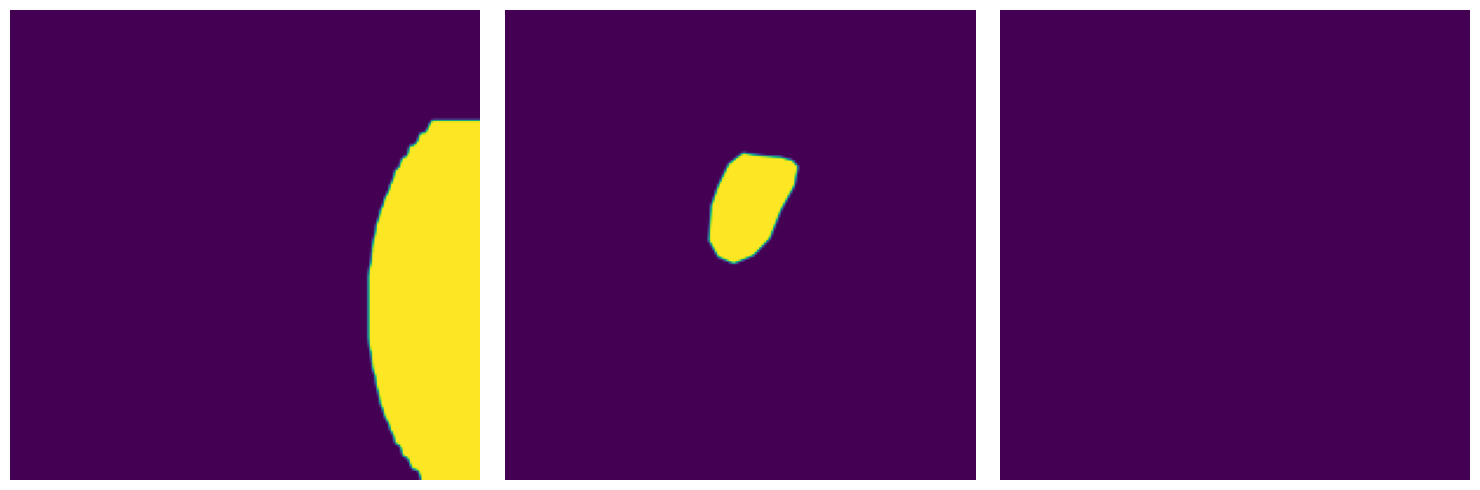

 83%|████████▎ | 7690/9210 [01:07<00:15, 95.30it/s]

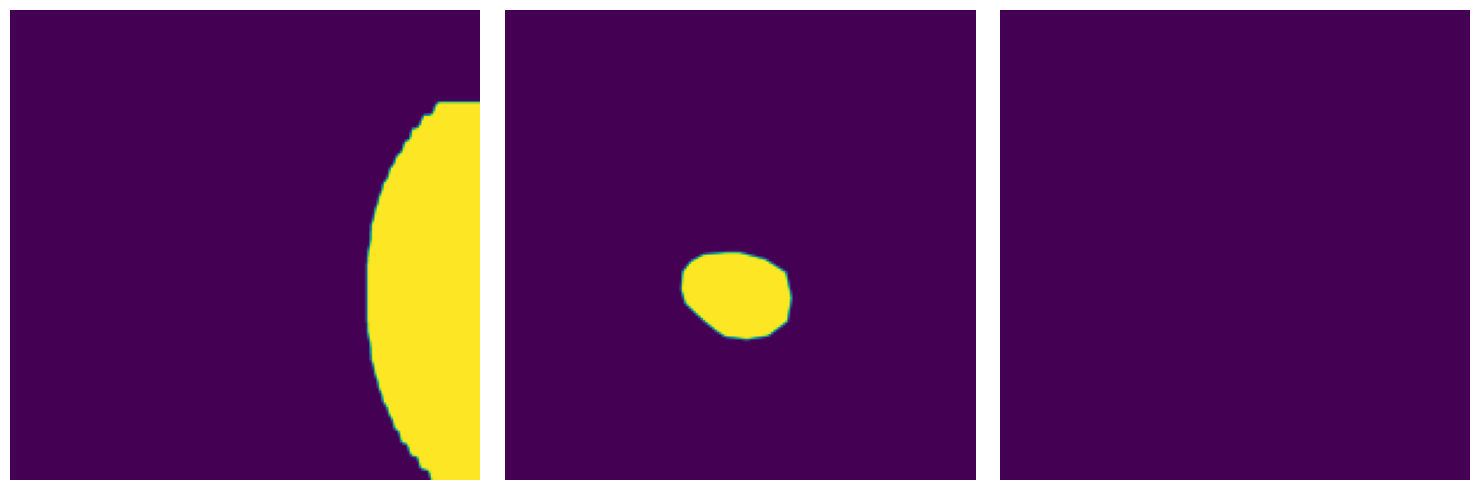

 84%|████████▎ | 7711/9210 [01:07<00:20, 71.99it/s]

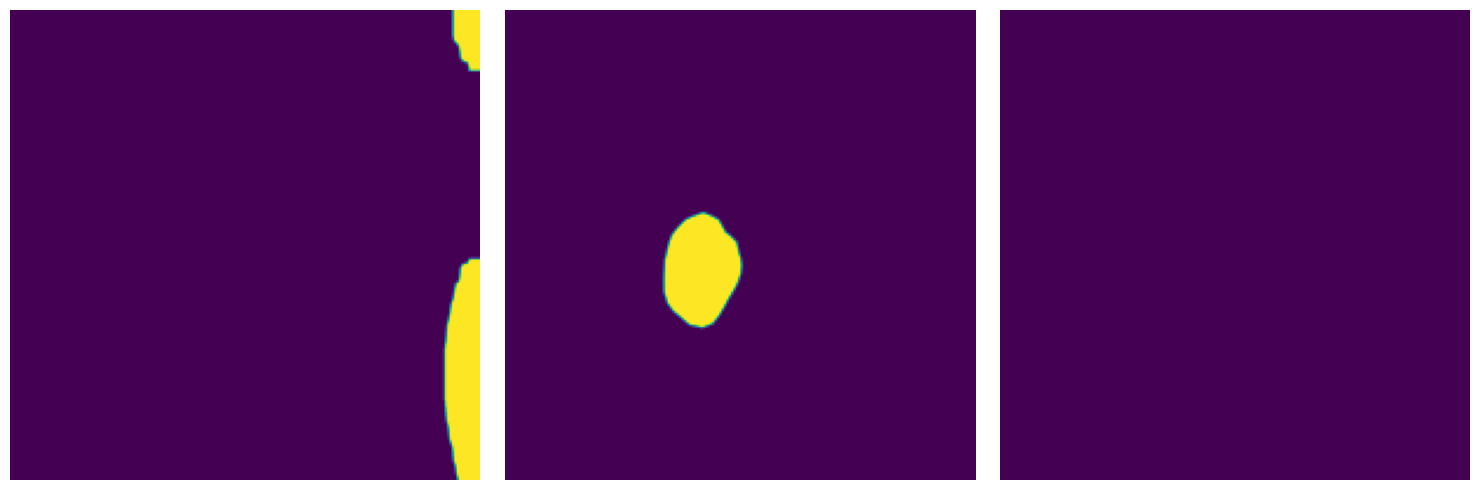

 84%|████████▍ | 7744/9210 [01:08<00:21, 67.93it/s]

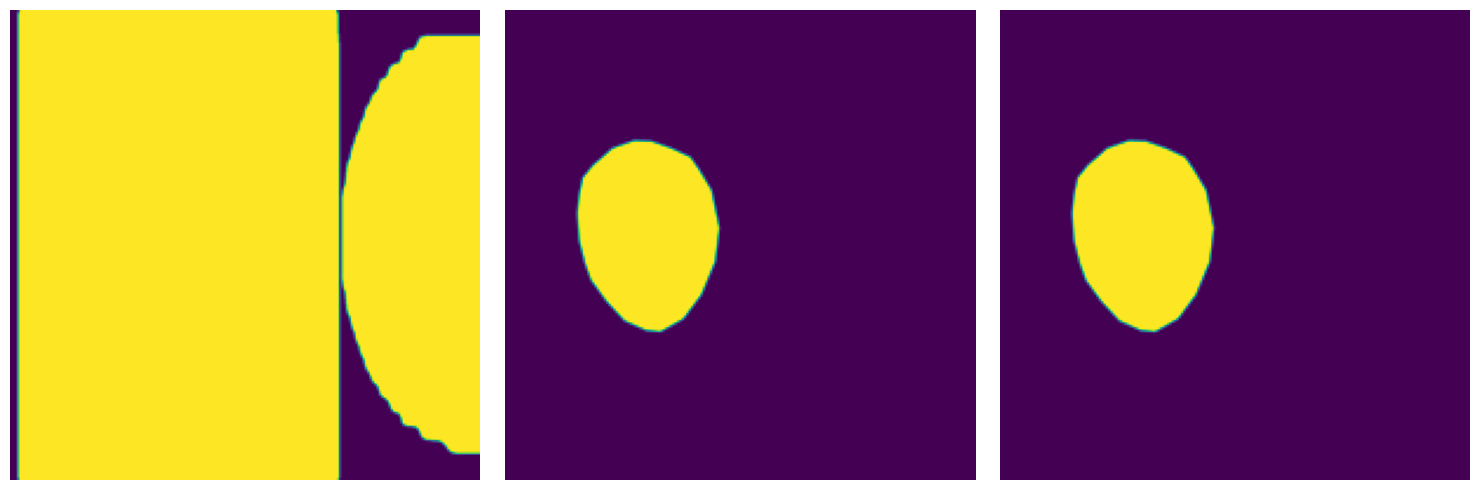

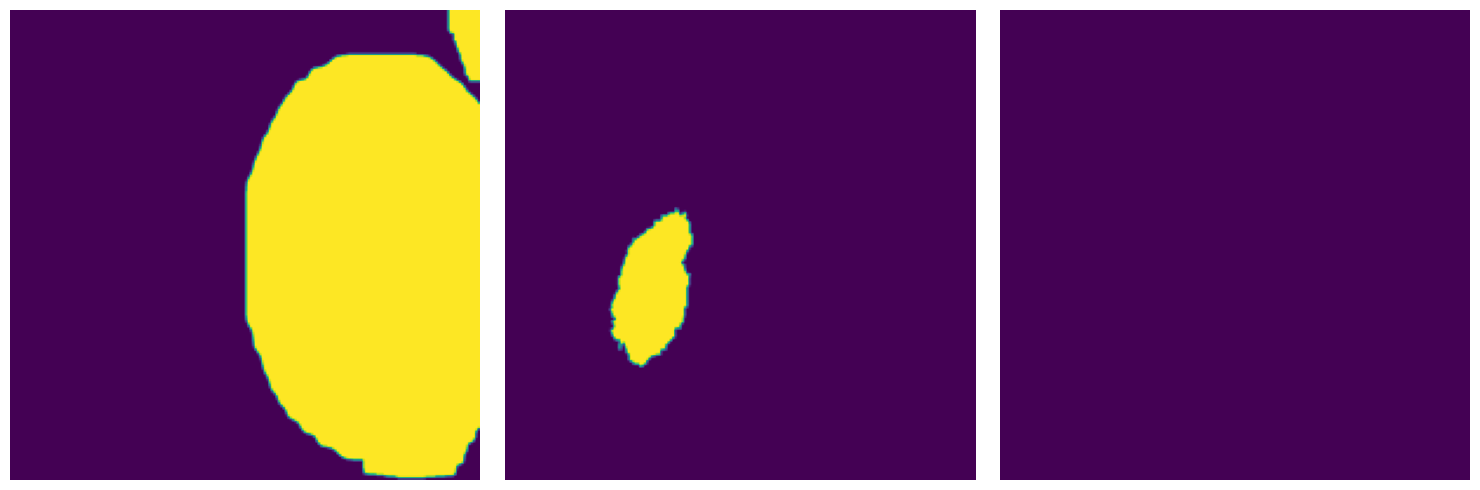

 85%|████████▍ | 7807/9210 [01:09<00:18, 77.32it/s]

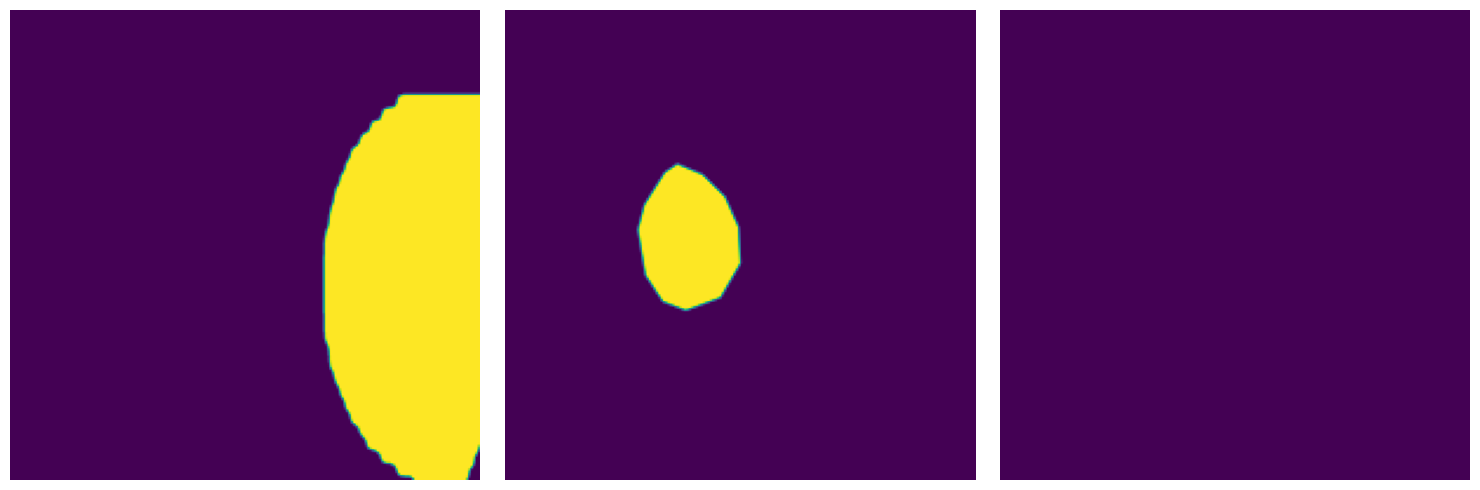

 85%|████████▌ | 7852/9210 [01:09<00:17, 78.24it/s]

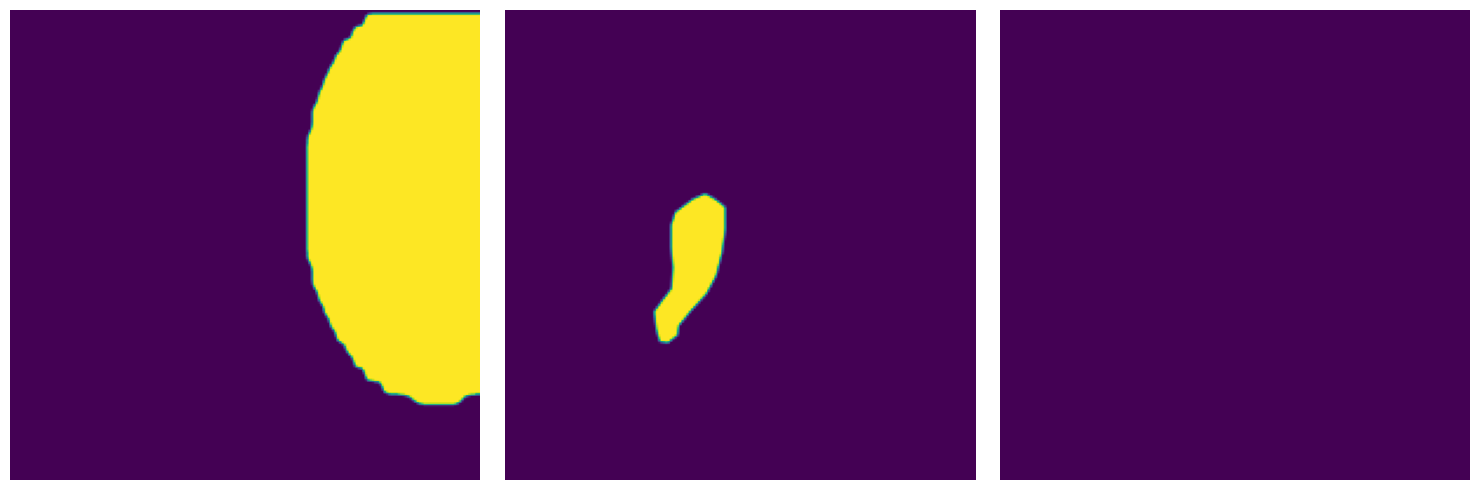

 85%|████████▌ | 7870/9210 [01:10<00:20, 64.00it/s]

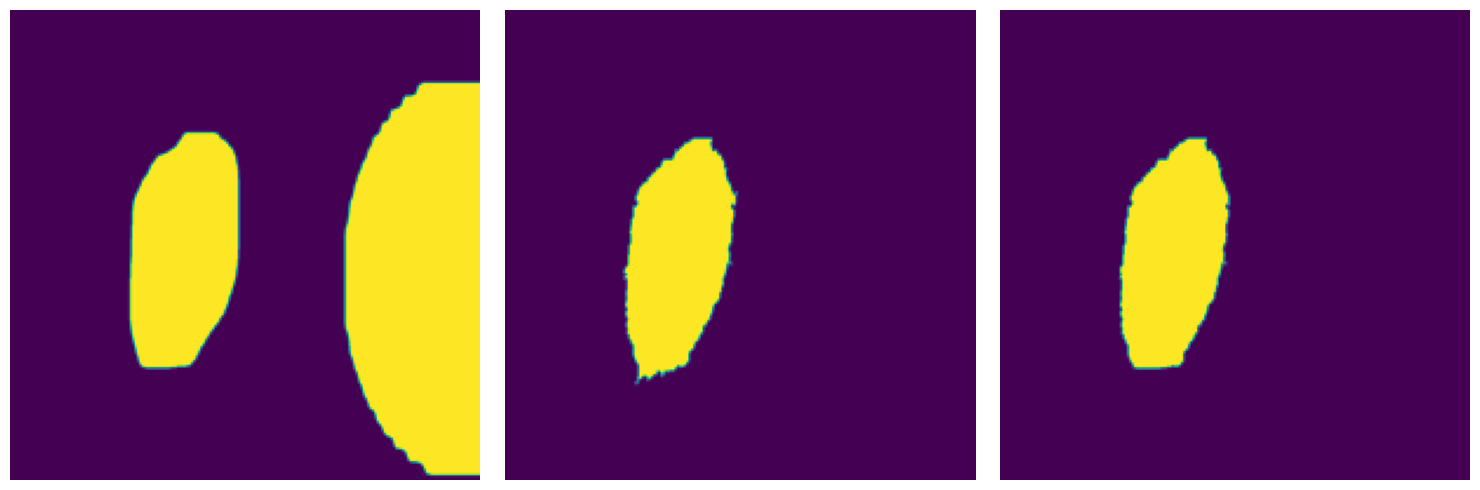

 86%|████████▌ | 7884/9210 [01:10<00:25, 52.15it/s]

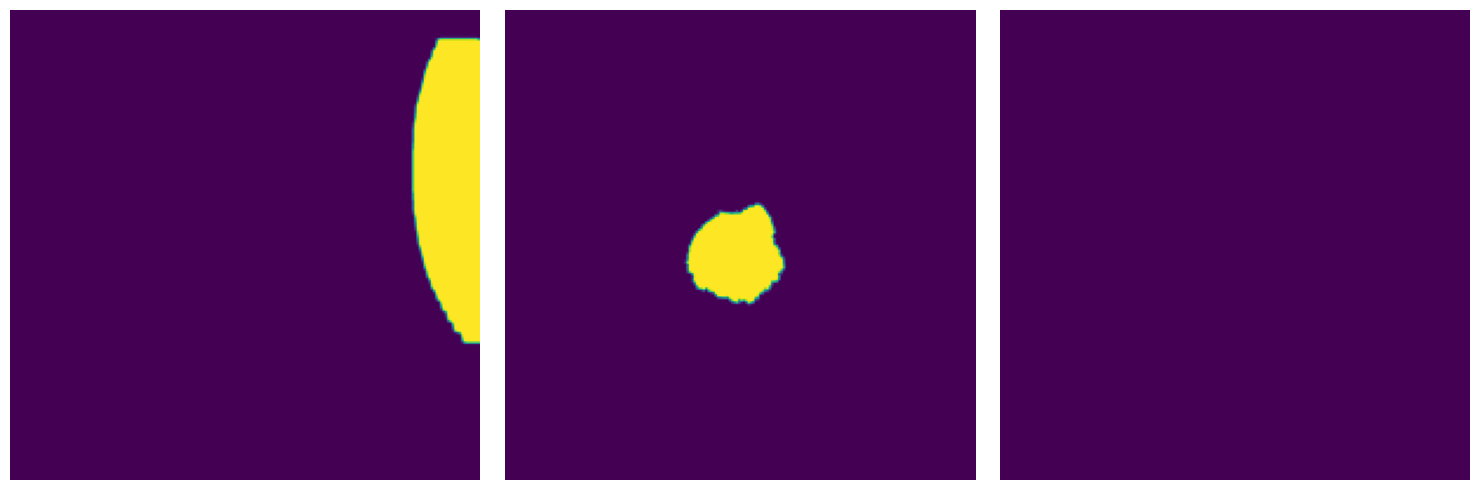

 86%|████████▌ | 7895/9210 [01:11<00:30, 42.78it/s]

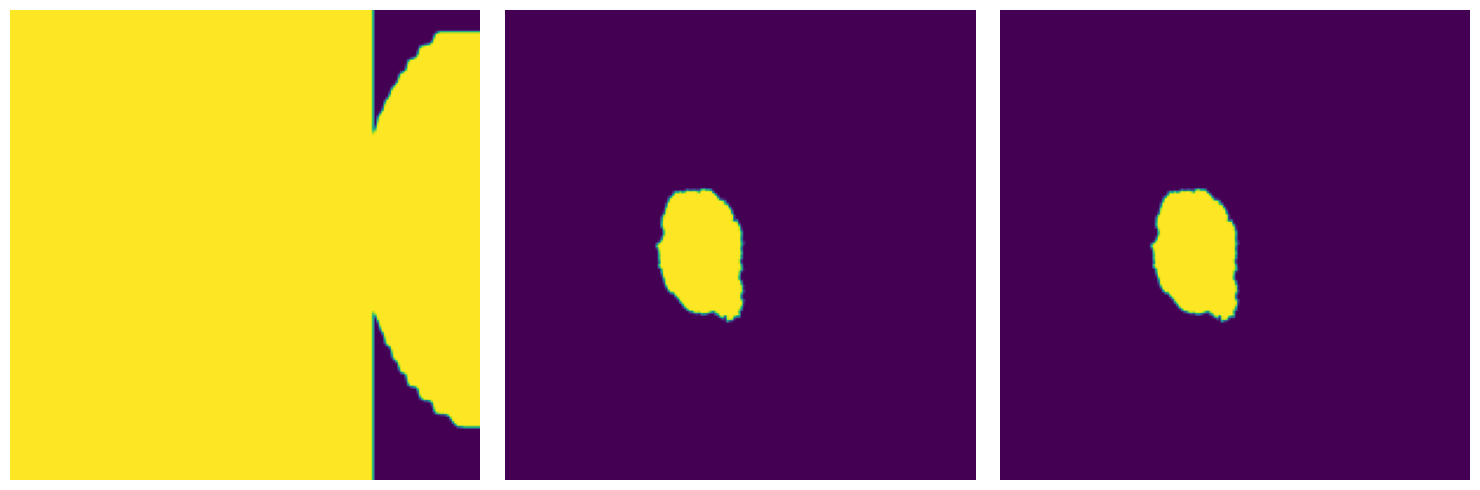

 86%|████████▌ | 7903/9210 [01:11<00:37, 34.81it/s]

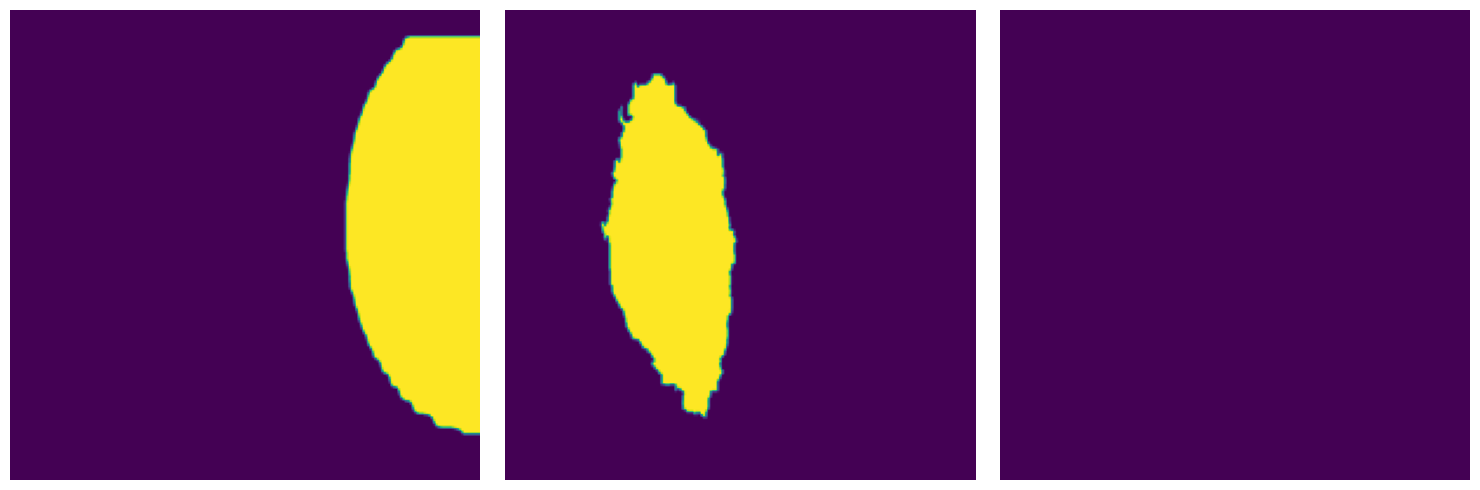

 86%|████████▋ | 7945/9210 [01:12<00:24, 52.58it/s]

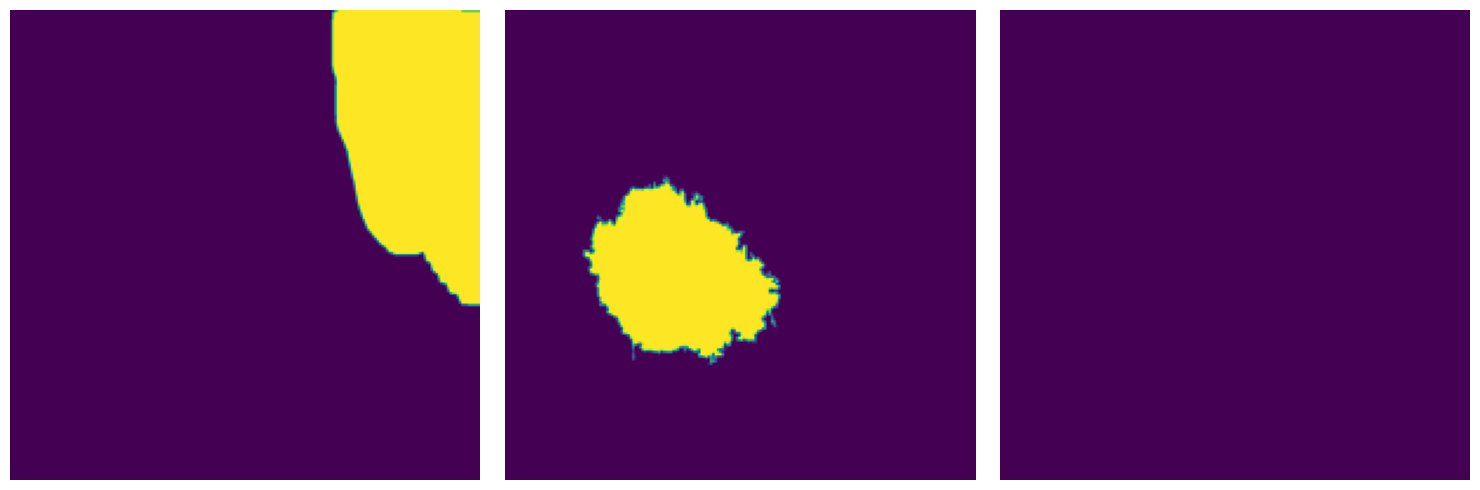

 87%|████████▋ | 7970/9210 [01:12<00:24, 50.37it/s]

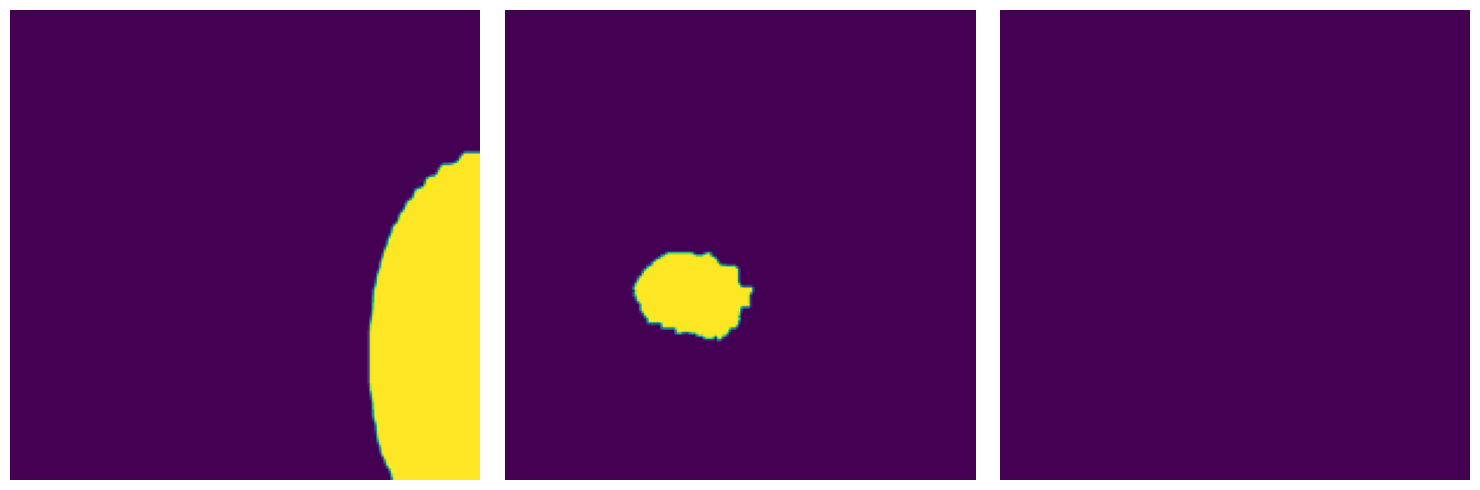

 88%|████████▊ | 8102/9210 [01:13<00:08, 128.50it/s]

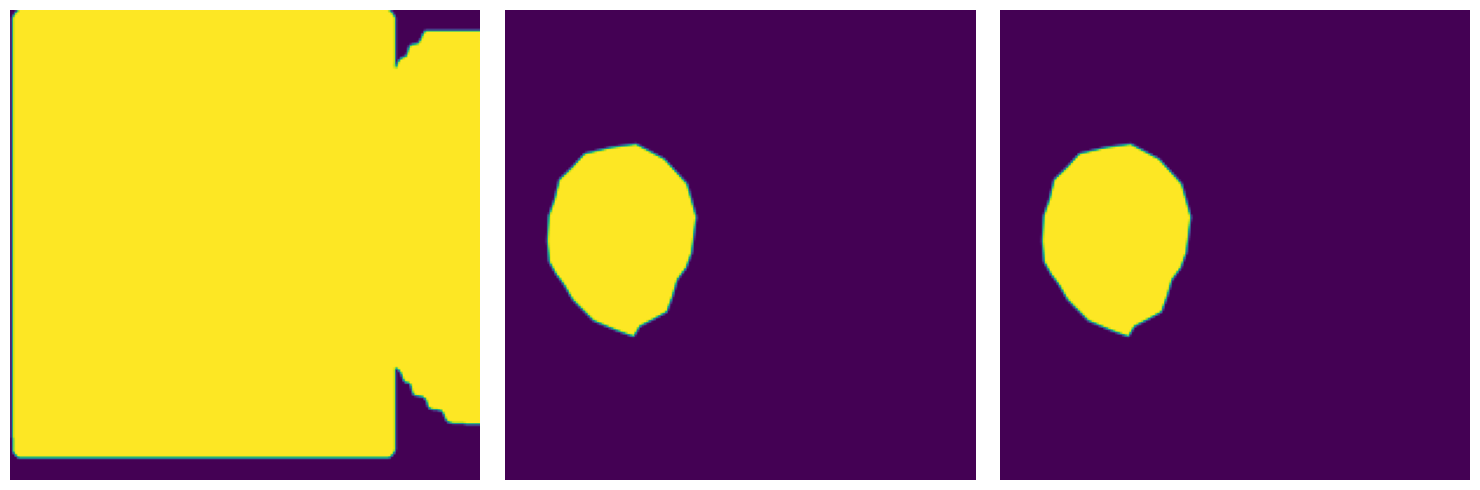

 88%|████████▊ | 8131/9210 [01:13<00:09, 110.68it/s]

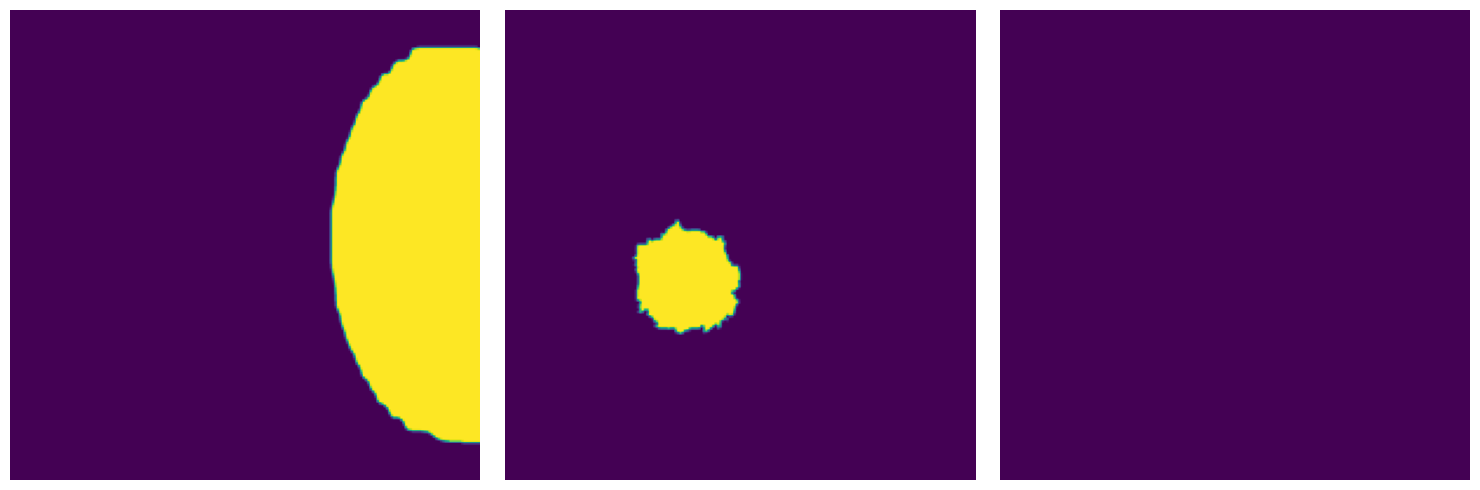

 89%|████████▉ | 8201/9210 [01:14<00:08, 122.31it/s]

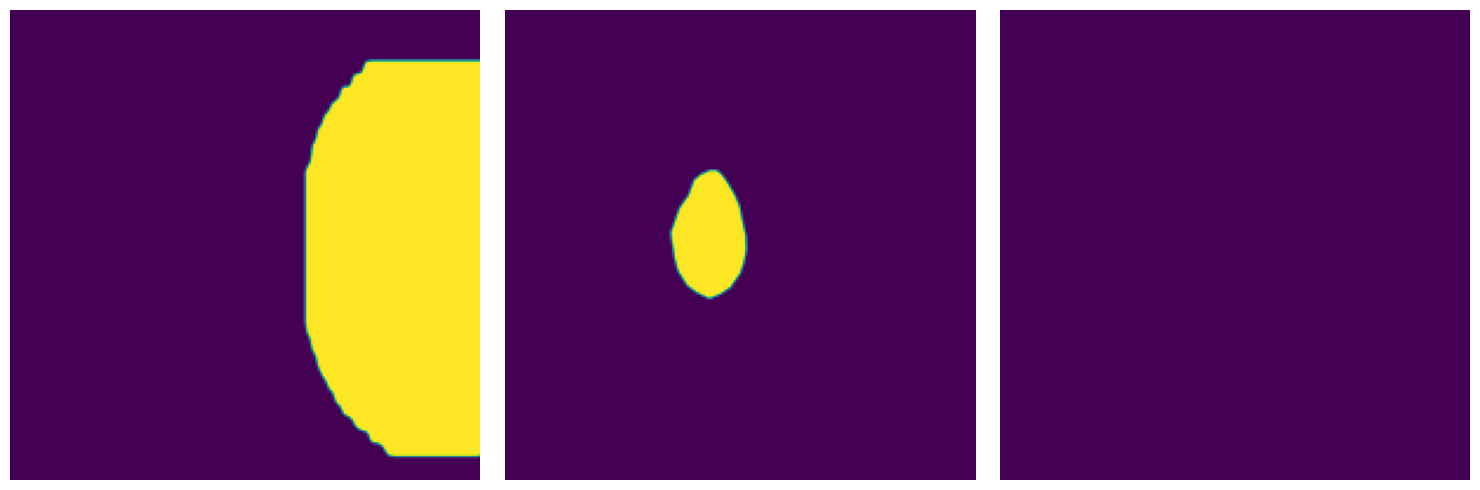

 89%|████████▉ | 8227/9210 [01:15<00:10, 90.99it/s] 

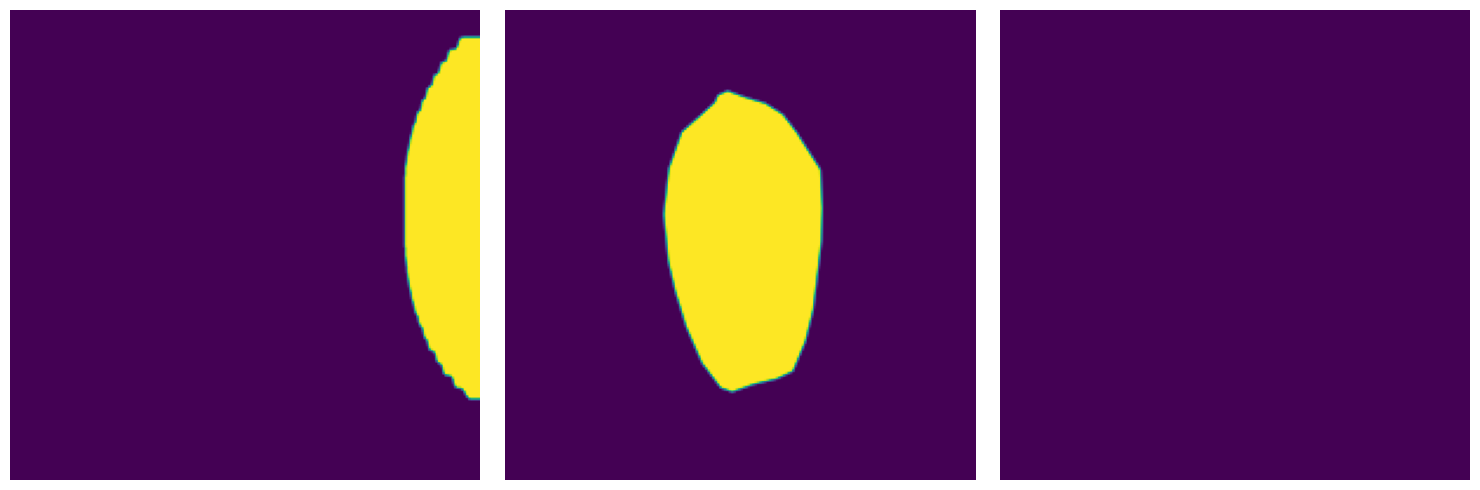

 90%|█████████ | 8306/9210 [01:15<00:07, 115.18it/s]

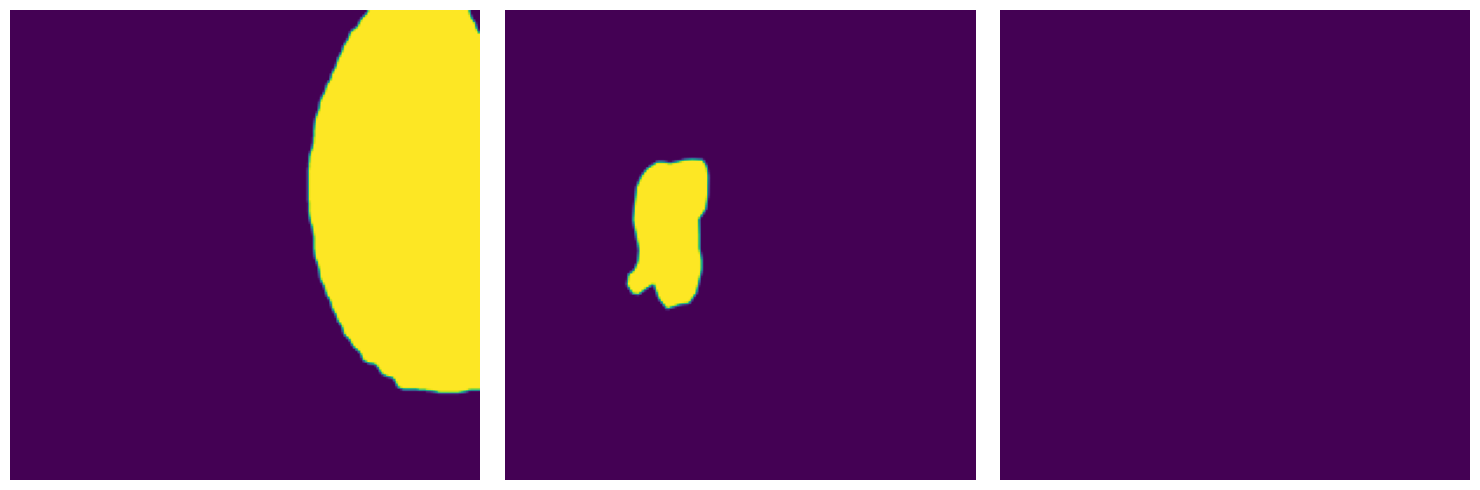

 91%|█████████ | 8336/9210 [01:16<00:09, 90.72it/s] 

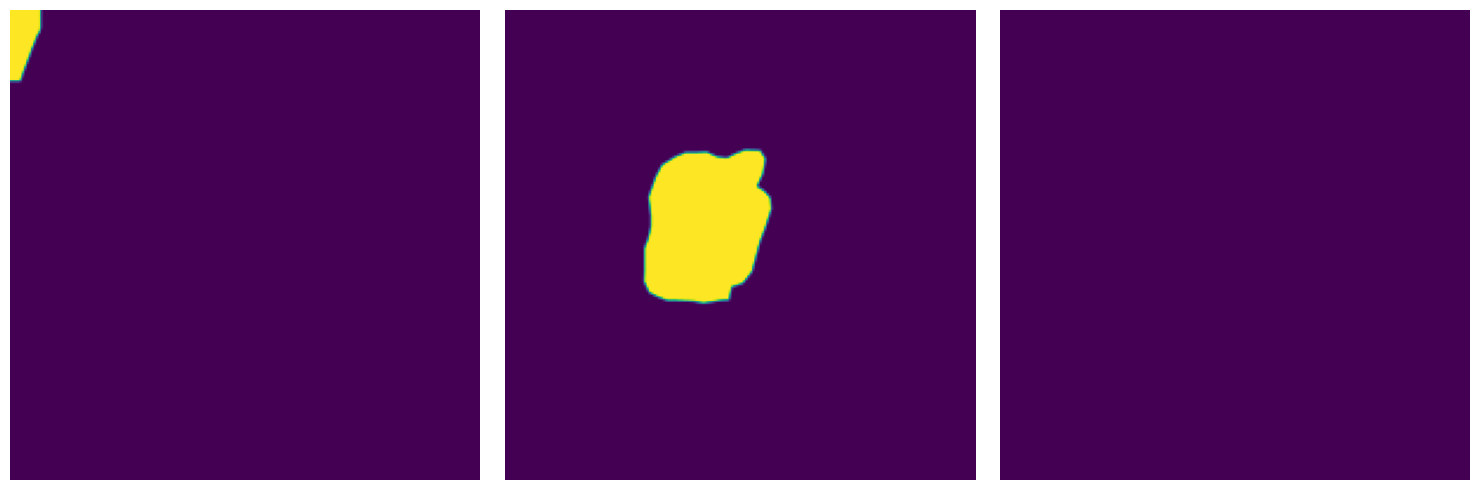

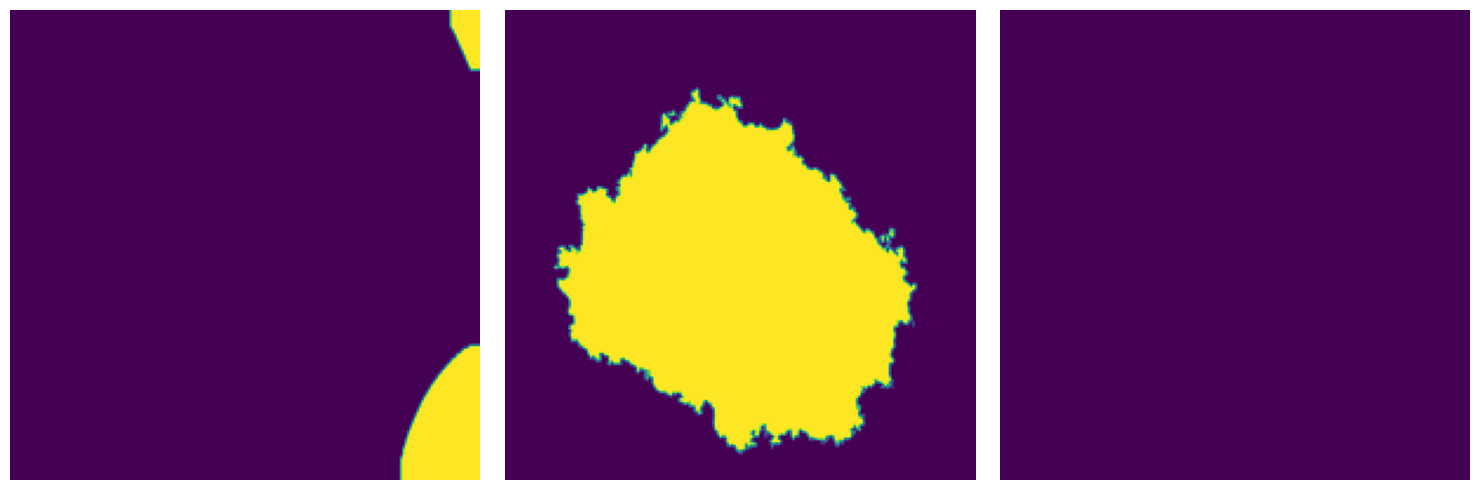

 91%|█████████ | 8356/9210 [01:17<00:14, 57.99it/s]

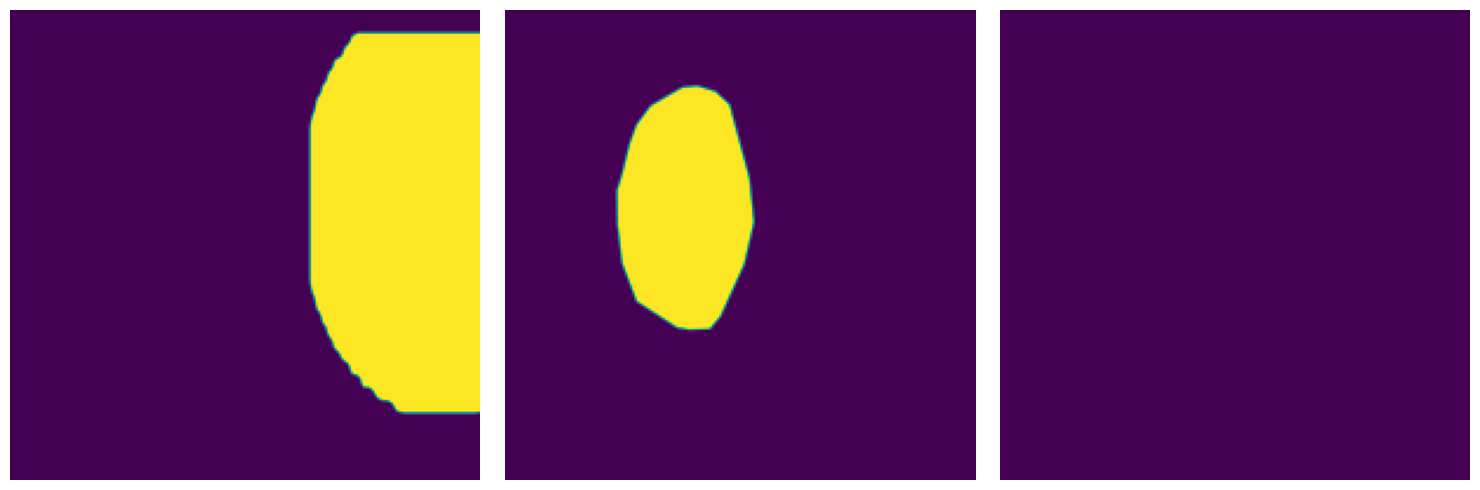

 91%|█████████ | 8379/9210 [01:17<00:15, 53.65it/s]

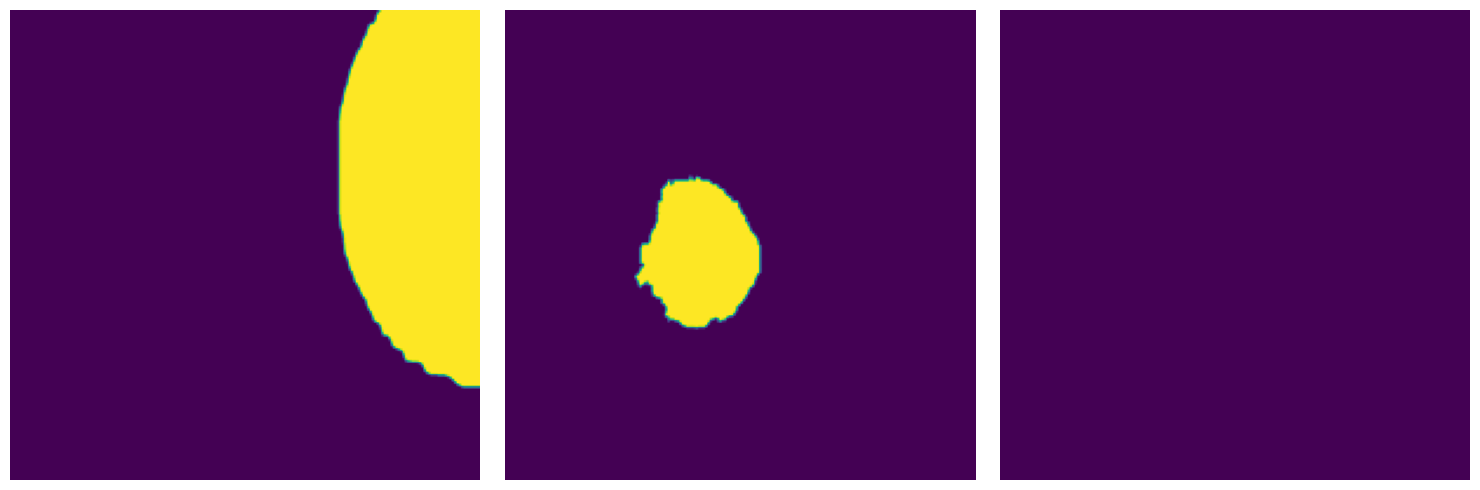

 91%|█████████▏| 8422/9210 [01:18<00:11, 66.82it/s]

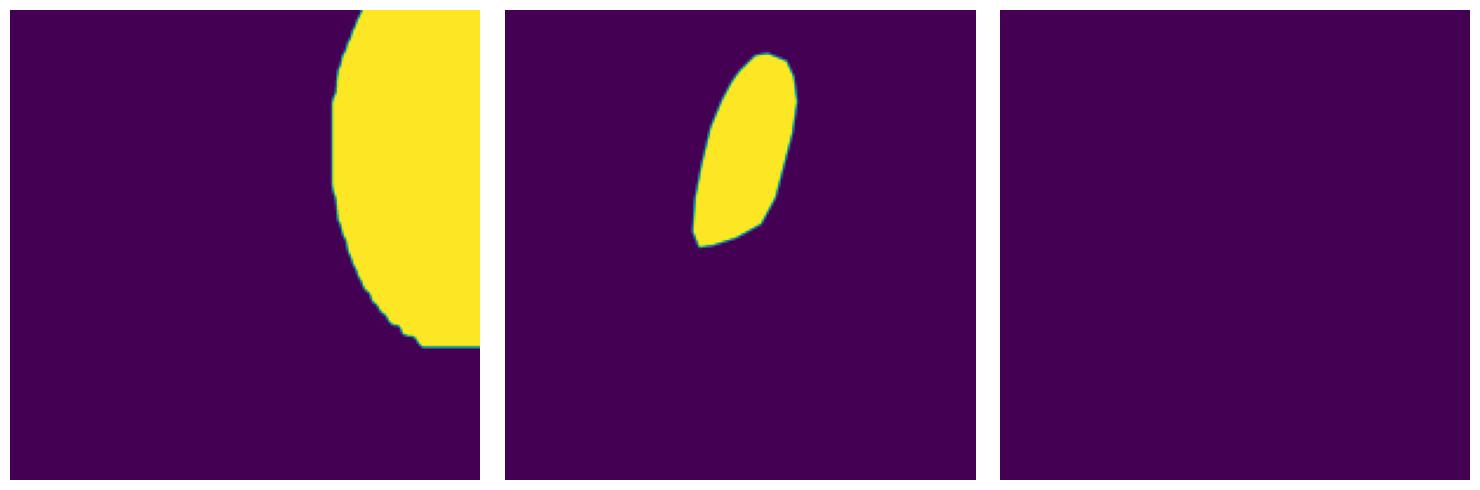

 92%|█████████▏| 8484/9210 [01:18<00:08, 88.83it/s]

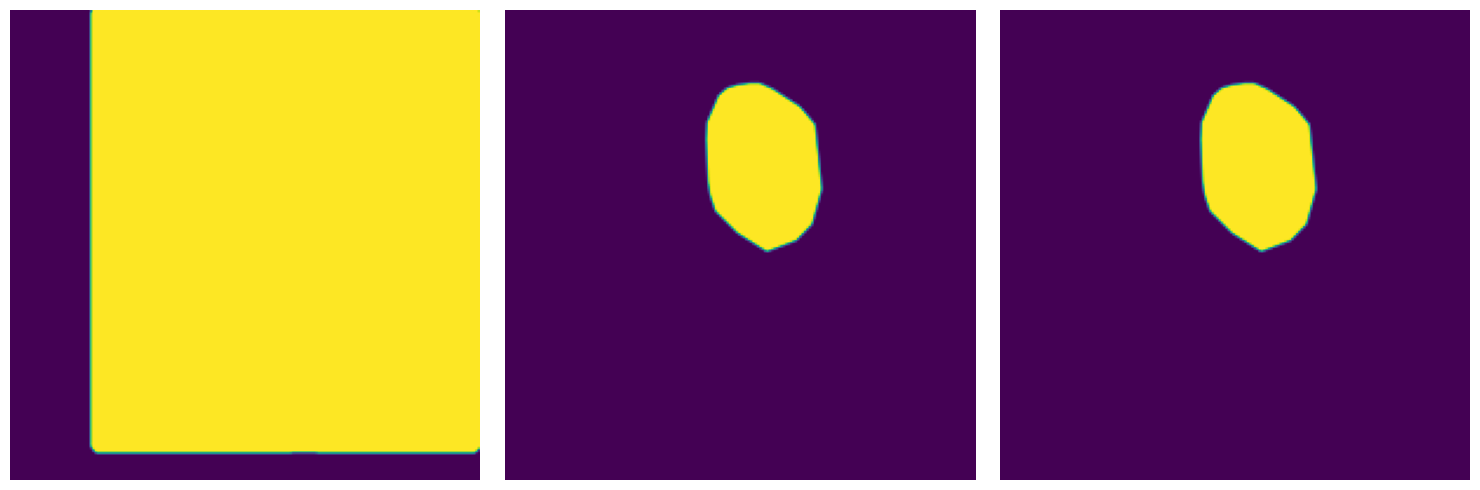

 92%|█████████▏| 8505/9210 [01:19<00:08, 80.52it/s]

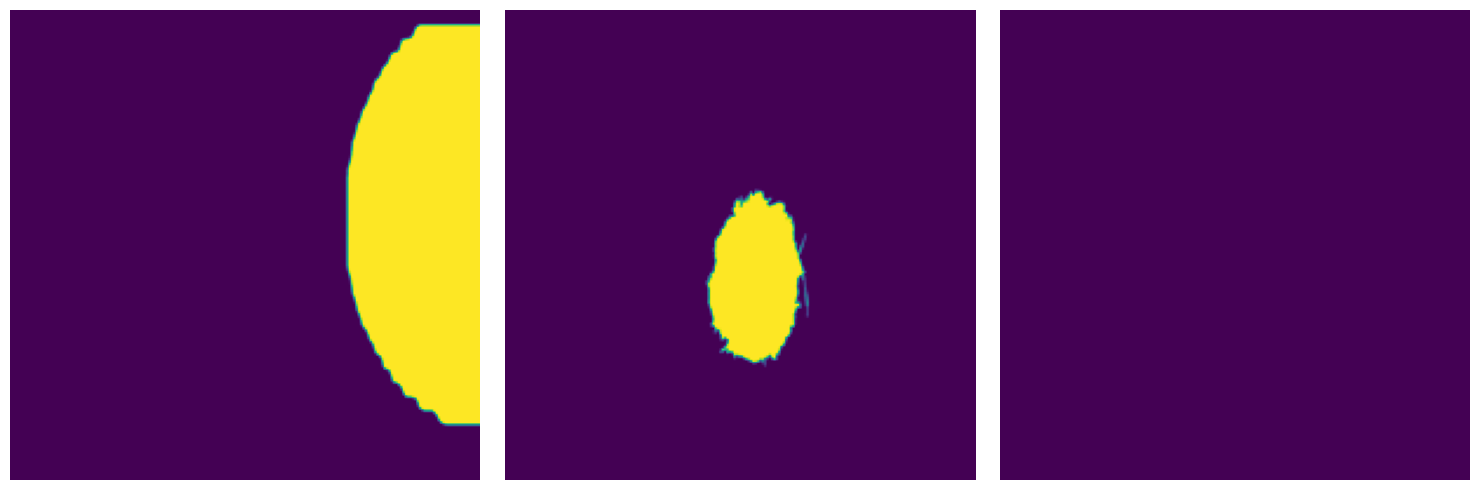

 93%|█████████▎| 8522/9210 [01:19<00:11, 62.54it/s]

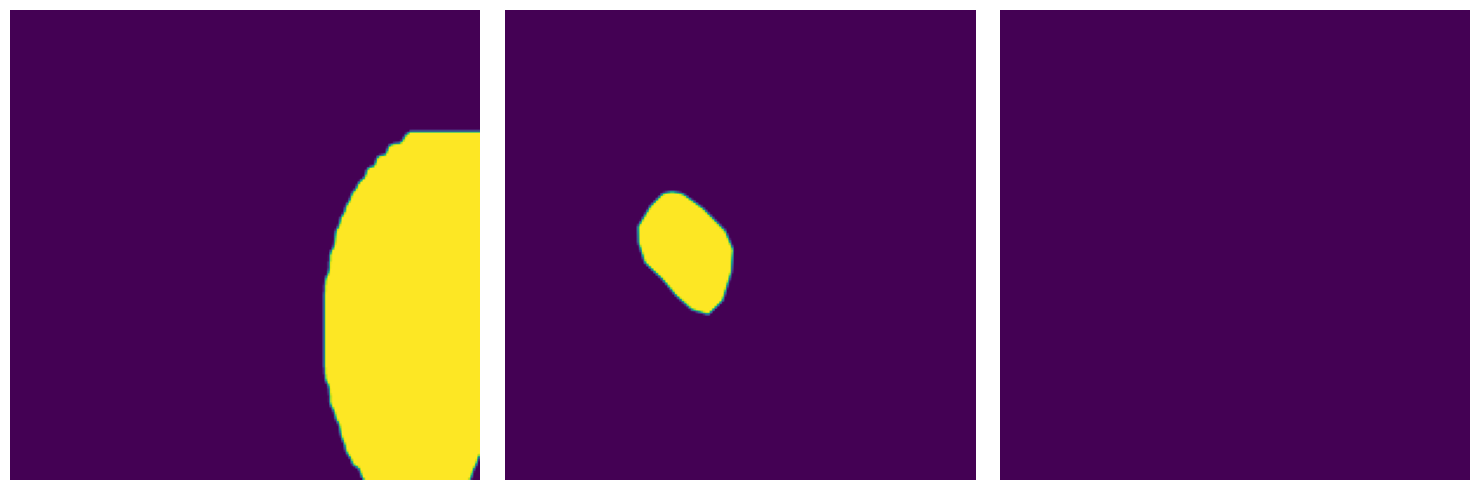

 93%|█████████▎| 8535/9210 [01:20<00:13, 50.33it/s]

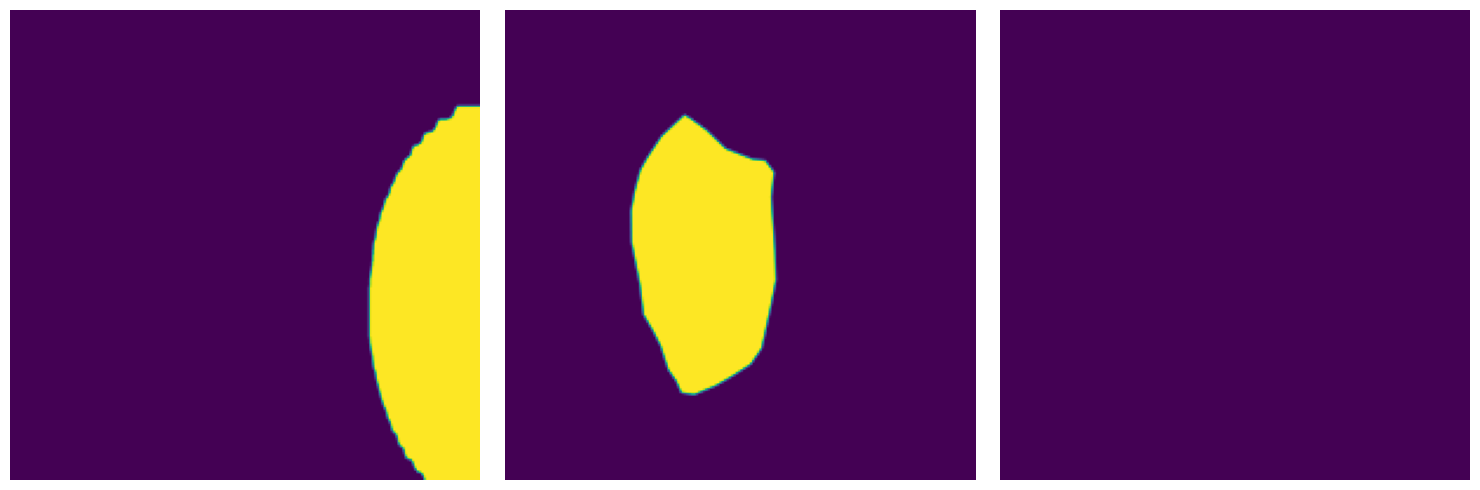

 93%|█████████▎| 8595/9210 [01:20<00:07, 79.57it/s]

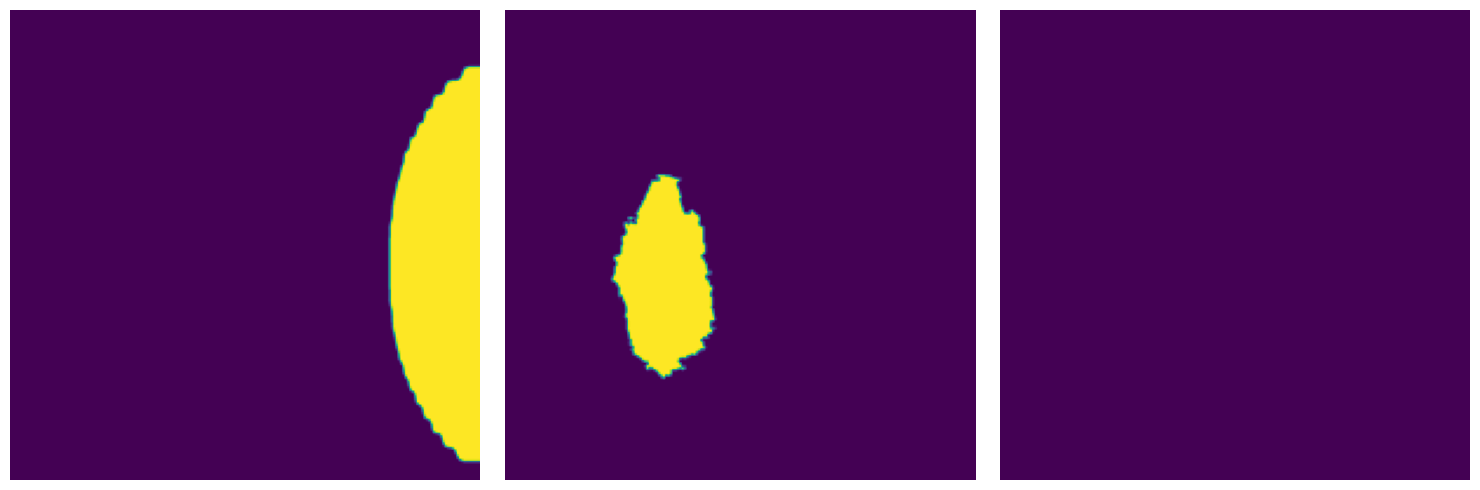

 94%|█████████▎| 8615/9210 [01:20<00:08, 72.13it/s]

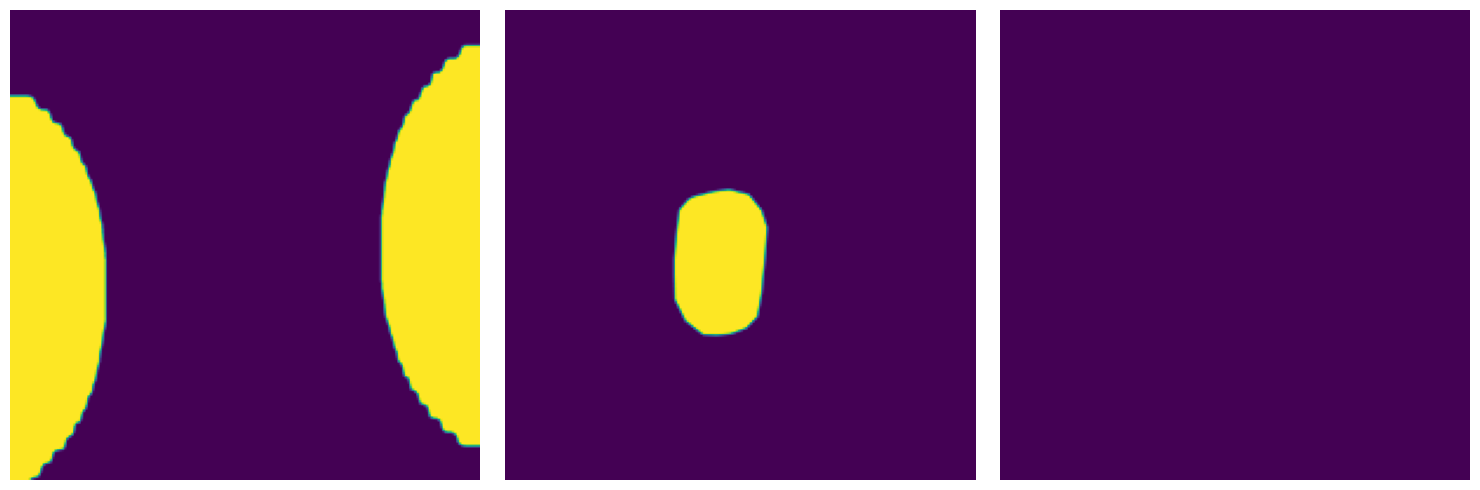

 94%|█████████▍| 8641/9210 [01:21<00:09, 62.88it/s]

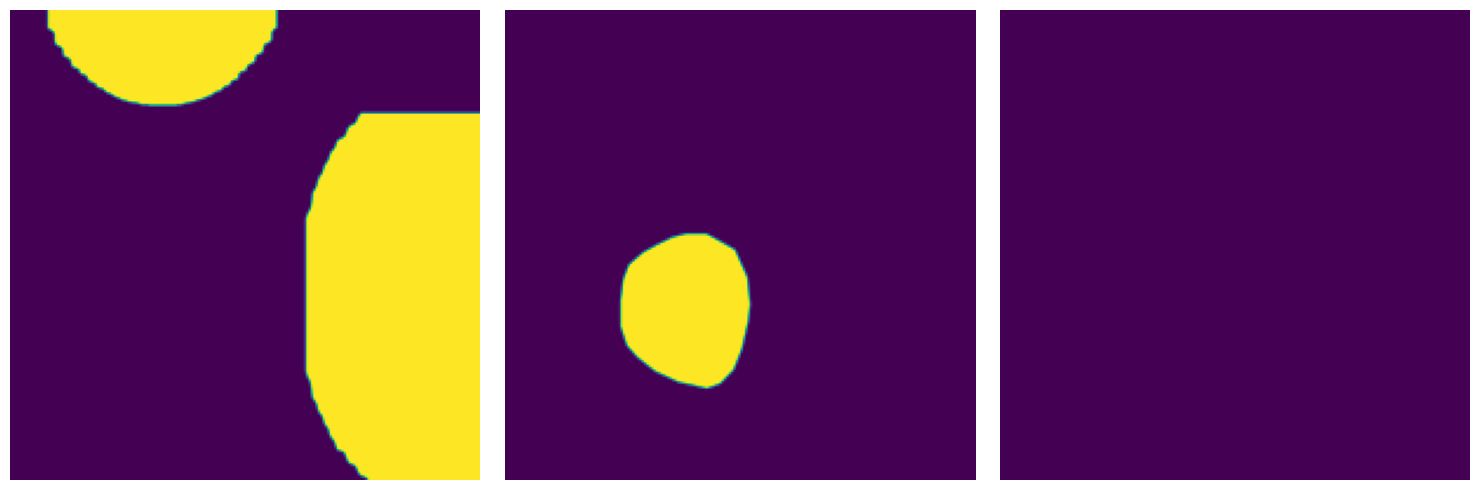

 94%|█████████▍| 8654/9210 [01:22<00:11, 50.14it/s]

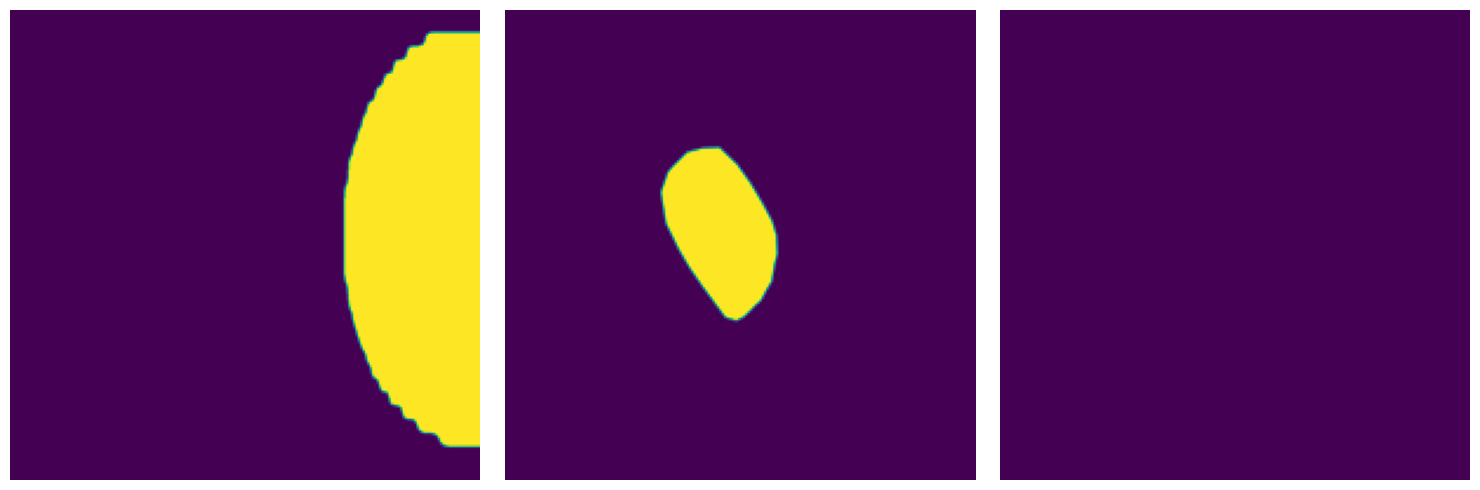

 95%|█████████▍| 8738/9210 [01:23<00:06, 68.94it/s]

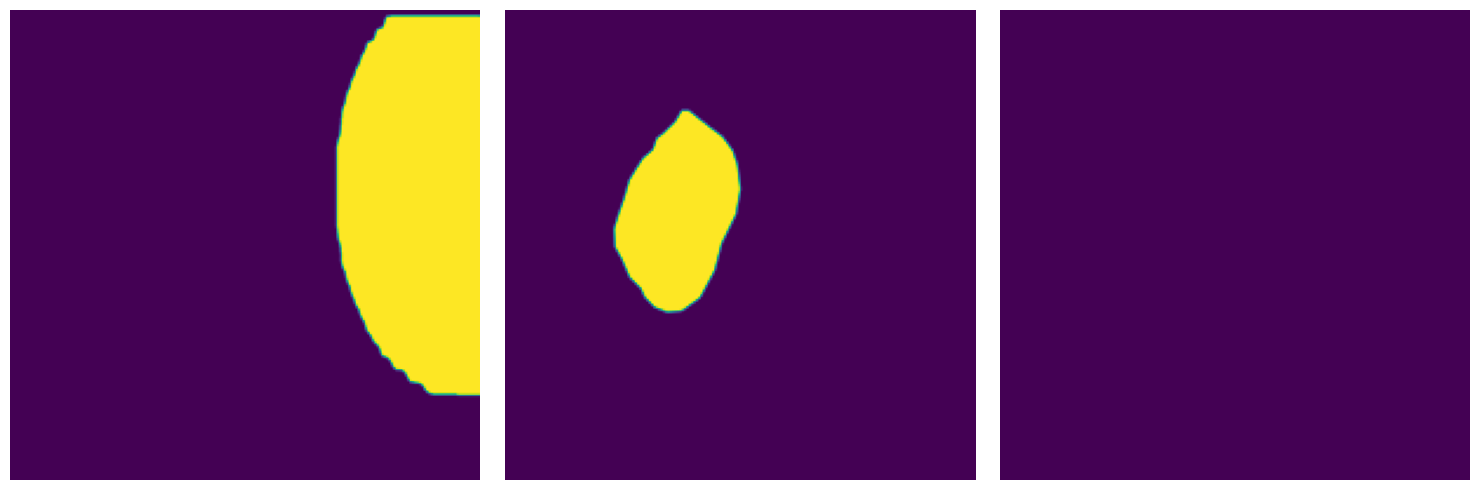

 96%|█████████▌| 8824/9210 [01:23<00:03, 111.79it/s]

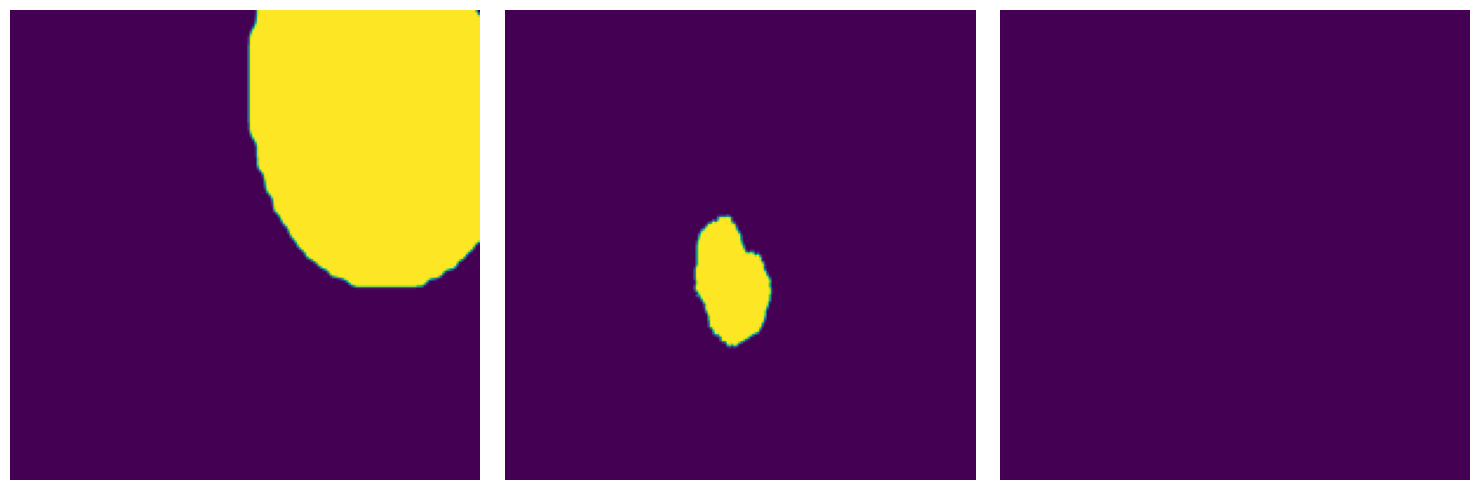

 96%|█████████▌| 8851/9210 [01:24<00:04, 87.70it/s] 

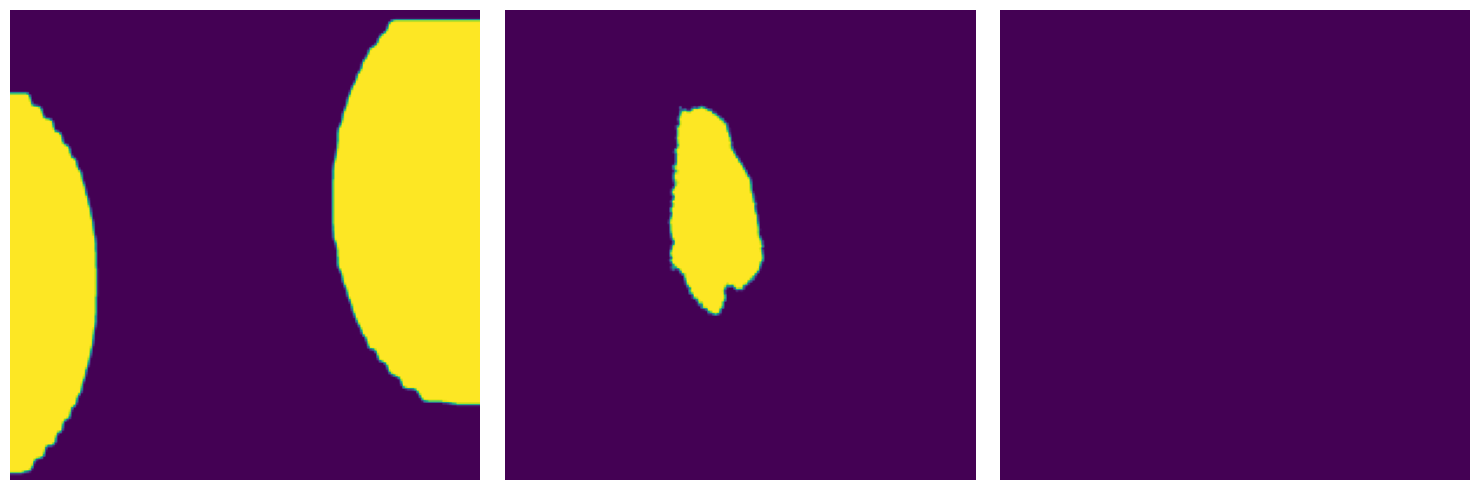

 96%|█████████▋| 8877/9210 [01:24<00:04, 73.27it/s]

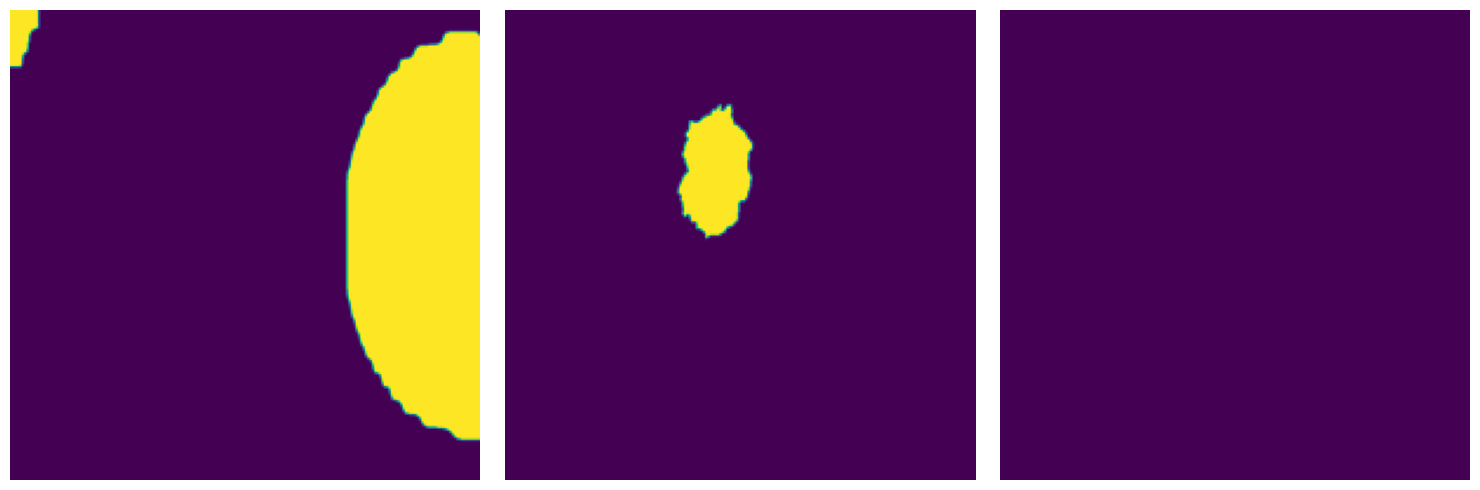

 97%|█████████▋| 8908/9210 [01:25<00:04, 66.88it/s]

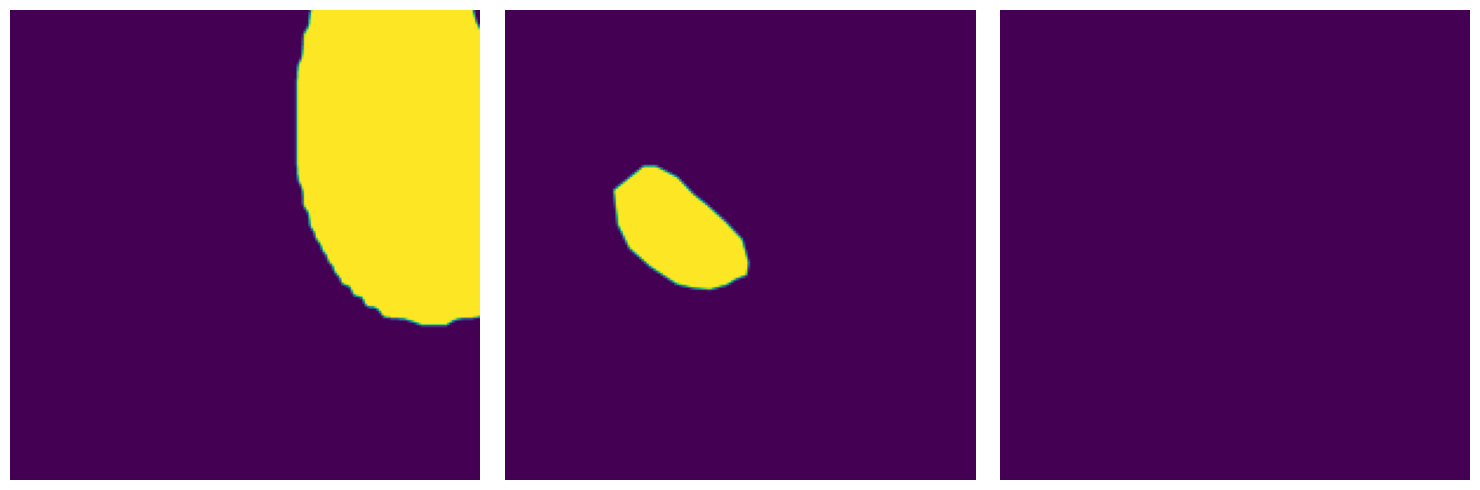

 97%|█████████▋| 8927/9210 [01:25<00:04, 57.55it/s]

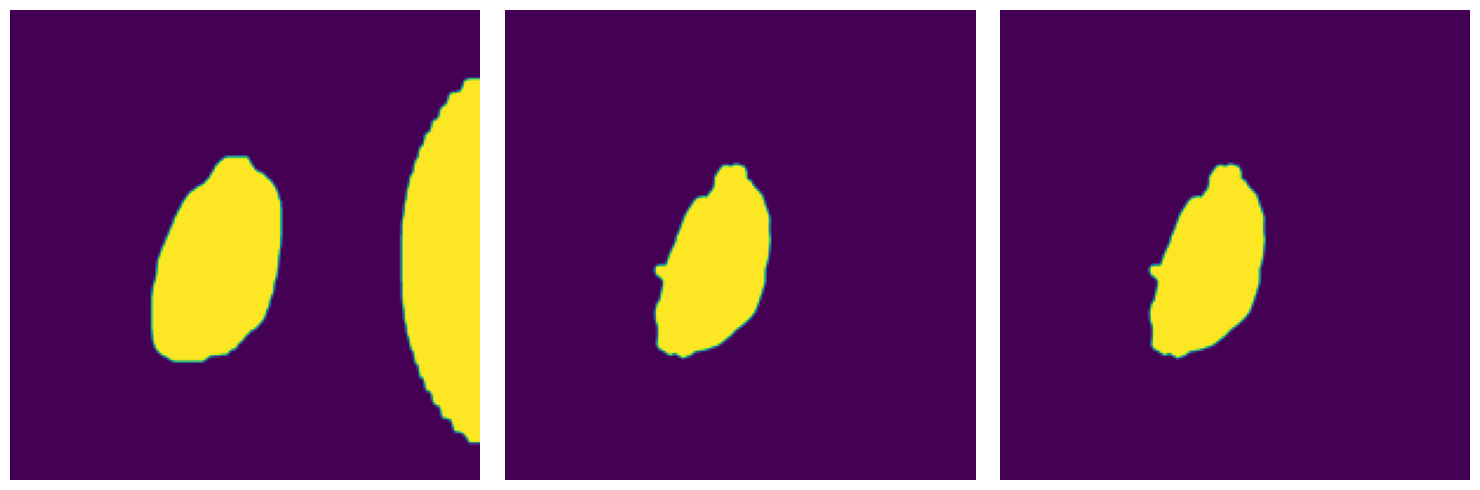

 99%|█████████▊| 9091/9210 [01:26<00:00, 172.62it/s]

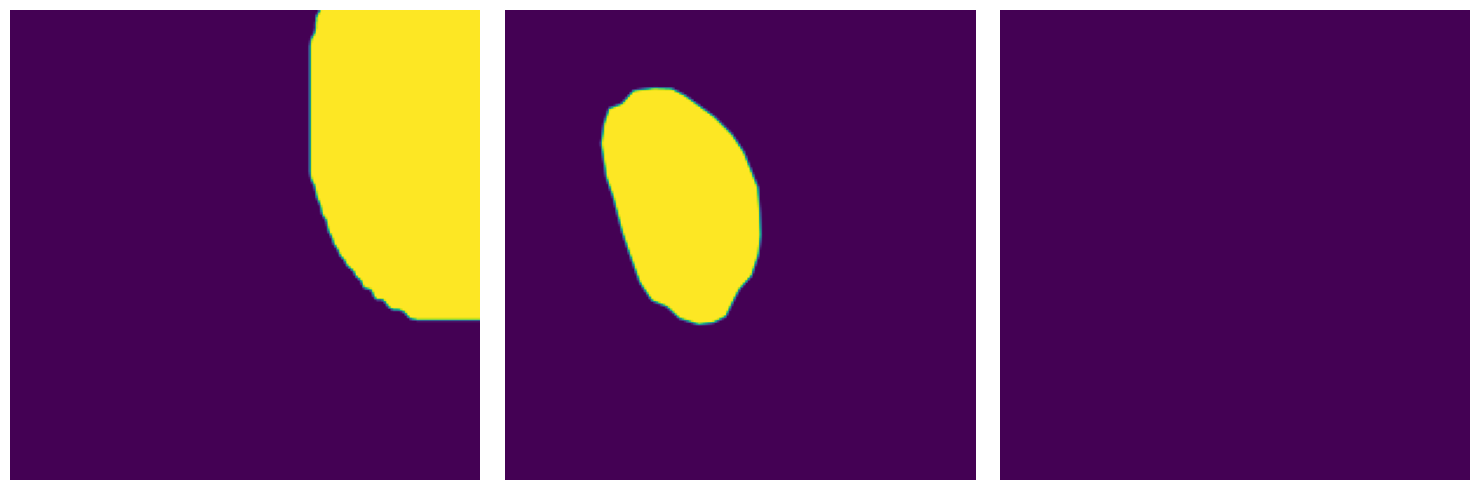

 99%|█████████▉| 9126/9210 [01:27<00:00, 136.92it/s]

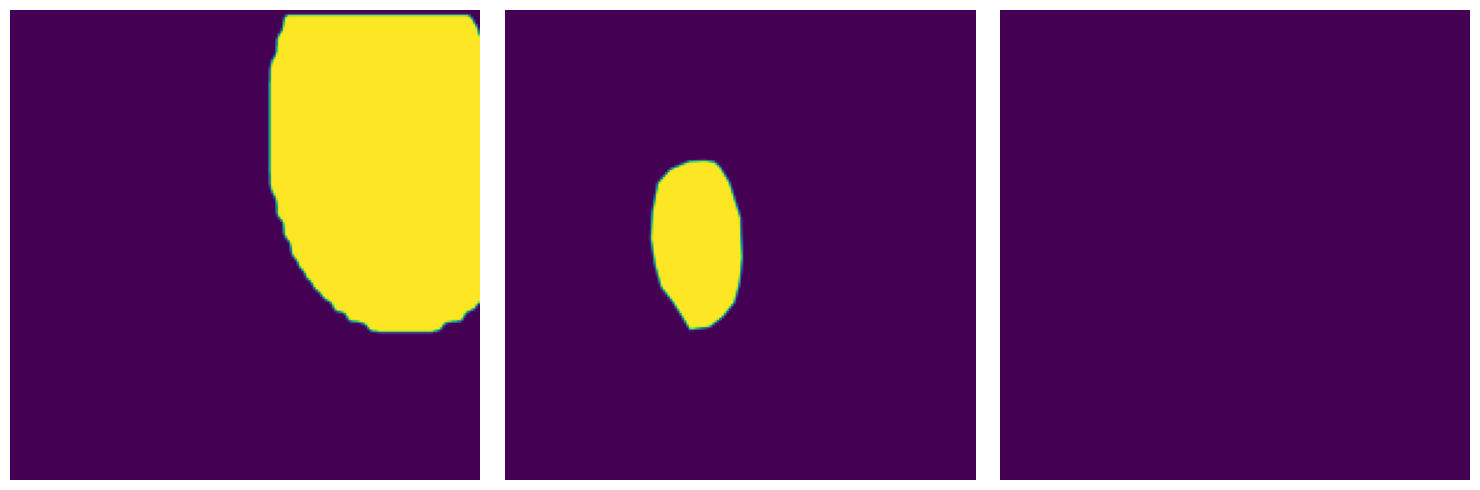

 99%|█████████▉| 9154/9210 [01:27<00:00, 99.59it/s] 

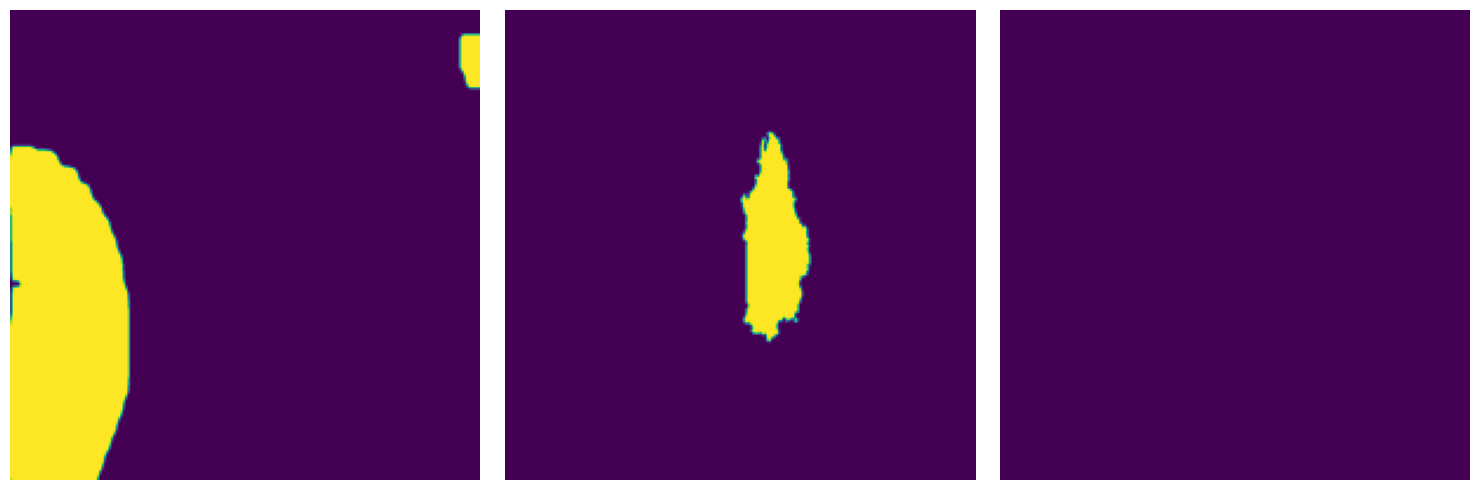

100%|██████████| 9210/9210 [01:28<00:00, 104.39it/s]


In [16]:
percentages_hint_on_mask = []
count_hint = 0
for mask_dict in tqdm(segmentation_masks):
    mask_name = mask_dict['file_name']
    mask = np.array(Image.open(mask_dict['file_path']).point(lambda x: 255 if x > 128 else 0))
    mask = dilate_mask(mask, config["inpainting"]["dilation"]["kernel_size"], config["inpainting"]["dilation"]["iterations"])
    if mask_name in segmentation_masks_hint_names:
        hint_mask_path = segmentation_masks_hint[segmentation_masks_hint_names.index(mask_name)]['file_path']
        hint_mask = np.array(Image.open(hint_mask_path).convert("L").point(lambda x: 255 if x > 128 else 0))
        count_hint += 1
    else:
        hint_mask = hint_mask
        continue
    percentages_hint_on_mask.append(percentage_hint_on_mask(mask, hint_mask))

In [17]:
percentages_hint_on_mask = np.array(percentages_hint_on_mask)
# print statistics
print(percentages_hint_on_mask)
# total number of images
print(f"Total number of images: {len(percentages_hint_on_mask)}")
print(f"Number of images with hint: {count_hint}")
# mean and median of all
print(f"Mean percentage of hint on mask: {np.mean(percentages_hint_on_mask)}")
print(f"Median percentage of hint on mask: {np.median(percentages_hint_on_mask)}")
# mean and median of those with percentage > 0
print(f"Mean percentage of hint on mask (percentage > 0): {np.mean(percentages_hint_on_mask[percentages_hint_on_mask > 0])}")
print(f"Median percentage of hint on mask (percentage > 0): {np.median(percentages_hint_on_mask[percentages_hint_on_mask > 0])}")
# get number where percentage is > 0
print(f"Number of images with hint on mask > 0.0: {np.sum(percentages_hint_on_mask > 0)}")
# get number where percentage is > 0.1
print(f"Number of images with hint on mask > 0.1: {np.sum(percentages_hint_on_mask > 0.1)}")
# get number where percentage is > 0.25
print(f"Number of images with hint on mask > 0.25: {np.sum(percentages_hint_on_mask > 0.25)}")
# get number where percentage is > 0.5
print(f"Number of images with hint on mask > 0.5: {np.sum(percentages_hint_on_mask > 0.5)}")



[          0           0           0           0           0           0           0           0           0           0           0           0           0           0           0           0           0           0           0           0           0           0           0           0           0           0
           0           0           0           0           0           0           0           0           0           0           0           0           0   0.0024506           0           0           0           0           0           0           0   0.0035701           0           0           0           0
           0           0           0           0           0           0           0           0   0.0039216           0           0           0           0           0           0           0   0.0039216           0           0           0           0           0           0   0.0037364           0           0
           0           0           0           0           0 